# Comparison: With vs Without Charging-at-Breaks Constraint

This notebook compares the uncertainty analysis results between:
- **Baseline**: Without `constraint_charging_at_breaks_only`
- **Constrained**: With `constraint_charging_at_breaks_only`

The constraint restricts BEV charging to locations where mandatory driver breaks occur (every ~360 km for 45 minutes).

Key metrics compared:
1. Fleet electrification (h variable - vehicle stock by technology)
2. Charging locations and energy (s variable)
3. Infrastructure deployment (q_fuel_infr_plus)

In [1]:
import os
import yaml
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from glob import glob
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

In [2]:
# Define paths
BASE_DIR = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM"
RESULTS_DIR = os.path.join(BASE_DIR, "results")

# Results folders
BASELINE_DIR = os.path.join(RESULTS_DIR, "uncertainty_analysis")  # WITHOUT constraint
CONSTRAINED_DIR = os.path.join(RESULTS_DIR, "uncertainty_analysis_with_breaks_full")  # WITH constraint

# Load scenario parameters
with open(os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "cases.json"), 'r') as f:
    cases_config = json.load(f)

print(f"Number of scenarios: {cases_config['n_cases']}")
print(f"Baseline directory: {BASELINE_DIR}")
print(f"Constrained directory: {CONSTRAINED_DIR}")

Number of scenarios: 24
Baseline directory: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis
Constrained directory: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis_with_breaks_full


In [3]:
def get_latest_file(folder, pattern):
    """Get the most recent file matching a pattern in a folder."""
    files = glob(os.path.join(folder, f"*{pattern}"))
    if not files:
        return None
    # Sort by modification time, return most recent
    return max(files, key=os.path.getmtime)

def load_yaml_safe(filepath):
    """Load YAML file with error handling."""
    try:
        with open(filepath, 'r') as f:
            return yaml.safe_load(f)
    except Exception as e:
        print(f"Error loading {filepath}: {e}")
        return None

def parse_key_to_year(key):
    """Extract year from a key string like '(2020, ...)' or tuple."""
    if isinstance(key, str):
        parts = key.strip("()").split(",")
        return int(parts[0].strip())
    elif isinstance(key, tuple):
        return key[0]
    return None

def parse_key_to_tech(key):
    """Extract tech_id from h_dict key - format: (year, mode_id, tech_id, generation)."""
    if isinstance(key, str):
        parts = key.strip("()").split(",")
        if len(parts) >= 3:
            return int(parts[2].strip())  # Return as integer
    elif isinstance(key, tuple) and len(key) >= 3:
        return key[2]
    return None


## Load All Scenario Results

In [4]:
# Load results from all scenarios
scenarios = [f"scenario_{i:03d}" for i in range(24)]

baseline_results = {}
constrained_results = {}

import datetime

# Show which files are being loaded (for verification)
print(f"Loading results at: {datetime.datetime.now()}")
print(f"Baseline directory: {BASELINE_DIR}")
print(f"Constrained directory: {CONSTRAINED_DIR}")
print()

for scenario in scenarios:
    # Baseline results
    baseline_folder = os.path.join(BASELINE_DIR, scenario)
    if os.path.exists(baseline_folder):
        h_file = get_latest_file(baseline_folder, "h_dict.yaml")
        s_file = get_latest_file(baseline_folder, "_s_dict.yaml")
        q_file = get_latest_file(baseline_folder, "q_fuel_infr_plus_dict.yaml")
        tt_file = get_latest_file(baseline_folder, "travel_time_dict.yaml")
        
        # Print file info for first scenario to verify correct data is loaded
        if scenario == "scenario_000" and h_file:
            mtime = datetime.datetime.fromtimestamp(os.path.getmtime(h_file))
            print(f"First baseline h_dict file: {os.path.basename(h_file)}")
            print(f"  Modified: {mtime}")
        
        baseline_results[scenario] = {
            'h': load_yaml_safe(h_file) if h_file else None,
            's': load_yaml_safe(s_file) if s_file else None,
            'q': load_yaml_safe(q_file) if q_file else None,
            'travel_time': load_yaml_safe(tt_file) if tt_file else None
        }
    
    # Constrained results
    constrained_folder = os.path.join(CONSTRAINED_DIR, scenario)
    if os.path.exists(constrained_folder):
        h_file = get_latest_file(constrained_folder, "h_dict.yaml")
        s_file = get_latest_file(constrained_folder, "_s_dict.yaml")
        q_file = get_latest_file(constrained_folder, "q_fuel_infr_plus_dict.yaml")
        tt_file = get_latest_file(constrained_folder, "travel_time_dict.yaml")
        
        # Print file info for first scenario to verify correct data is loaded
        if scenario == "scenario_000" and h_file:
            mtime = datetime.datetime.fromtimestamp(os.path.getmtime(h_file))
            print(f"First constrained h_dict file: {os.path.basename(h_file)}")
            print(f"  Modified: {mtime}")
        
        constrained_results[scenario] = {
            'h': load_yaml_safe(h_file) if h_file else None,
            's': load_yaml_safe(s_file) if s_file else None,
            'q': load_yaml_safe(q_file) if q_file else None,
            'travel_time': load_yaml_safe(tt_file) if tt_file else None
        }

print()
print(f"Loaded baseline results for {len(baseline_results)} scenarios")
print(f"Loaded constrained results for {len(constrained_results)} scenarios")

# Check travel_time loading
baseline_tt_count = sum(1 for s in baseline_results.values() if s.get('travel_time'))
constrained_tt_count = sum(1 for s in constrained_results.values() if s.get('travel_time'))
print(f"Baseline scenarios with travel_time: {baseline_tt_count}")
print(f"Constrained scenarios with travel_time: {constrained_tt_count}")

# Quick verification: calculate BEV share for scenario_000 year 2040 to verify data integrity
def quick_bev_check(h_dict):
    if h_dict is None:
        return "N/A"
    bev_2040 = 0
    icev_2040 = 0
    for key, val in h_dict.items():
        v = float(val) if isinstance(val, str) else val
        if v <= 1e-6:
            continue
        if isinstance(key, str):
            parts = key.strip("()").split(",")
            year = int(parts[0].strip())
            tech = int(parts[2].strip())
        else:
            year, _, tech, _ = key
        if year == 2040:
            if tech == 1:
                bev_2040 += v
            else:
                icev_2040 += v
    total = bev_2040 + icev_2040
    return f"{100*bev_2040/total:.1f}%" if total > 0 else "N/A"

print()
print("Data verification (BEV share @ 2040 for scenario_000):")
print(f"  Baseline: {quick_bev_check(baseline_results.get('scenario_000', {}).get('h'))}")
print(f"  Constrained: {quick_bev_check(constrained_results.get('scenario_000', {}).get('h'))}")
print("  (If these show 100%, the notebook needs to be re-run or kernel restarted)")

Loading results at: 2025-12-16 21:40:27.277872
Baseline directory: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis
Constrained directory: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis_with_breaks_full

First baseline h_dict file: scenario_000_2025-12-16_10-22-42_h_dict.yaml
  Modified: 2025-12-16 10:34:40.786491
First constrained h_dict file: scenario_000_with_breaks_2025-12-16_15-36-35_h_dict.yaml
  Modified: 2025-12-16 15:47:57.288309

Loaded baseline results for 24 scenarios
Loaded constrained results for 24 scenarios

Data verification (BEV share @ 2040 for scenario_000):
  Baseline: 30.8%
  Constrained: 30.9%
  (If these show 100%, the notebook needs to be re-run or kernel restarted)


## 1. Fleet Electrification Comparison (h variable)

Compare the vehicle stock by technology between baseline and constrained runs.

In [5]:
def aggregate_h_by_year_and_tech(h_dict):
    """Aggregate vehicle stock by year and technology."""
    if h_dict is None:
        return {}
    
    result = defaultdict(lambda: defaultdict(float))
    
    for key, value in h_dict.items():
        val = float(value) if isinstance(value, str) else value
        if val > 1e-6:
            year = parse_key_to_year(key)
            tech = parse_key_to_tech(key)
            if year and tech:
                result[year][tech] += val
    
    return dict(result)

# Aggregate for all scenarios
baseline_h_agg = {}
constrained_h_agg = {}

for scenario in scenarios:
    if scenario in baseline_results and baseline_results[scenario]['h']:
        baseline_h_agg[scenario] = aggregate_h_by_year_and_tech(baseline_results[scenario]['h'])
    if scenario in constrained_results and constrained_results[scenario]['h']:
        constrained_h_agg[scenario] = aggregate_h_by_year_and_tech(constrained_results[scenario]['h'])

In [6]:
# Calculate BEV share over time for each scenario
years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

def calc_bev_share(h_by_year_tech):
    """Calculate BEV share as percentage of total fleet."""
    bev_share = {}
    for year in years:
        if year in h_by_year_tech:
            total = sum(h_by_year_tech[year].values())
            bev = sum(v for k, v in h_by_year_tech[year].items() if k == 1 or k == '1')
            bev_share[year] = 100 * bev / total if total > 0 else 0
        else:
            bev_share[year] = 0
    return bev_share

# Calculate for all scenarios
baseline_bev_shares = {s: calc_bev_share(baseline_h_agg.get(s, {})) for s in scenarios}
constrained_bev_shares = {s: calc_bev_share(constrained_h_agg.get(s, {})) for s in scenarios}

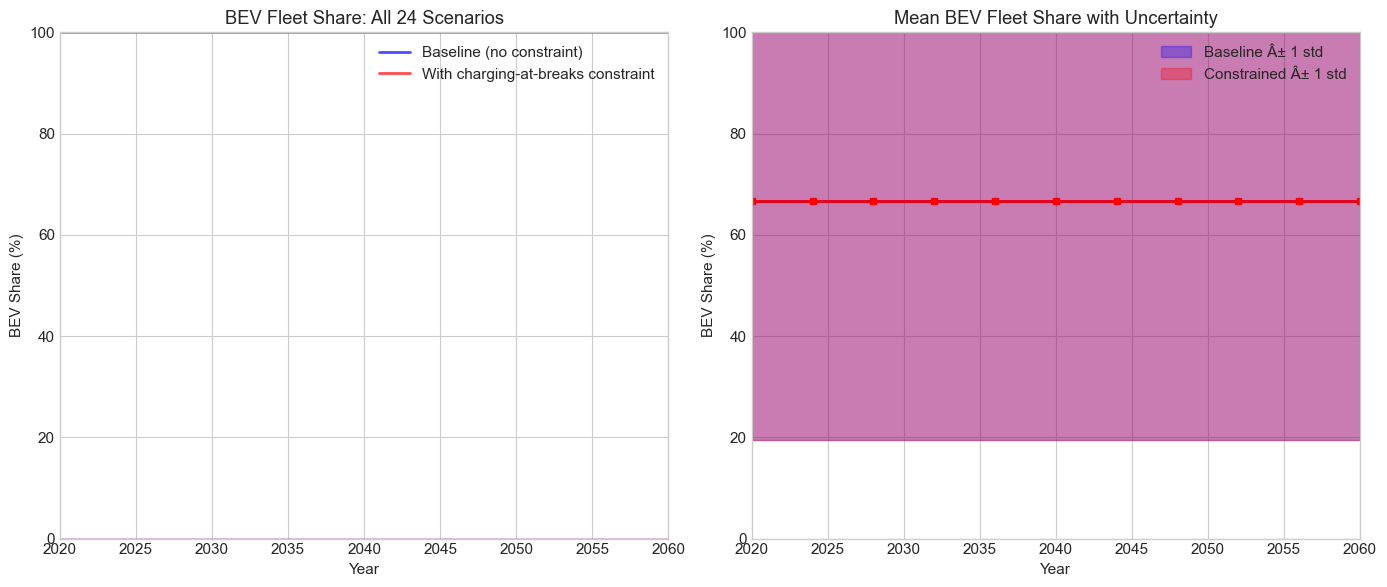

In [7]:
# Plot BEV share comparison across all scenarios
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Individual scenario comparison
ax1 = axes[0]
for i, scenario in enumerate(scenarios):
    if scenario in baseline_bev_shares and scenario in constrained_bev_shares:
        baseline_vals = [baseline_bev_shares[scenario].get(y, 0) for y in years]
        constrained_vals = [constrained_bev_shares[scenario].get(y, 0) for y in years]
        
        ax1.plot(years, baseline_vals, 'b-', alpha=0.3, linewidth=0.8)
        ax1.plot(years, constrained_vals, 'r-', alpha=0.3, linewidth=0.8)

# Add legend entries
ax1.plot([], [], 'b-', alpha=0.7, linewidth=2, label='Baseline (no constraint)')
ax1.plot([], [], 'r-', alpha=0.7, linewidth=2, label='With charging-at-breaks constraint')
ax1.set_xlabel('Year')
ax1.set_ylabel('BEV Share (%)')
ax1.set_title('BEV Fleet Share: All 24 Scenarios')
ax1.legend()
ax1.set_xlim(2020, 2060)
ax1.set_ylim(0, 100)

# Right: Mean with uncertainty bands
ax2 = axes[1]

# Calculate mean and std for each year
baseline_means = []
baseline_stds = []
constrained_means = []
constrained_stds = []

for year in years:
    b_vals = [baseline_bev_shares[s].get(year, 0) for s in scenarios if s in baseline_bev_shares]
    c_vals = [constrained_bev_shares[s].get(year, 0) for s in scenarios if s in constrained_bev_shares]
    
    baseline_means.append(np.mean(b_vals) if b_vals else 0)
    baseline_stds.append(np.std(b_vals) if b_vals else 0)
    constrained_means.append(np.mean(c_vals) if c_vals else 0)
    constrained_stds.append(np.std(c_vals) if c_vals else 0)

baseline_means = np.array(baseline_means)
baseline_stds = np.array(baseline_stds)
constrained_means = np.array(constrained_means)
constrained_stds = np.array(constrained_stds)

ax2.fill_between(years, baseline_means - baseline_stds, baseline_means + baseline_stds, 
                  alpha=0.3, color='blue', label='Baseline Â± 1 std')
ax2.fill_between(years, constrained_means - constrained_stds, constrained_means + constrained_stds, 
                  alpha=0.3, color='red', label='Constrained Â± 1 std')
ax2.plot(years, baseline_means, 'b-', linewidth=2, marker='o', markersize=4)
ax2.plot(years, constrained_means, 'r-', linewidth=2, marker='s', markersize=4)

ax2.set_xlabel('Year')
ax2.set_ylabel('BEV Share (%)')
ax2.set_title('Mean BEV Fleet Share with Uncertainty')
ax2.legend()
ax2.set_xlim(2020, 2060)
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'bev_share_constraint_comparison.pdf'), dpi=300, bbox_inches='tight')
plt.show()

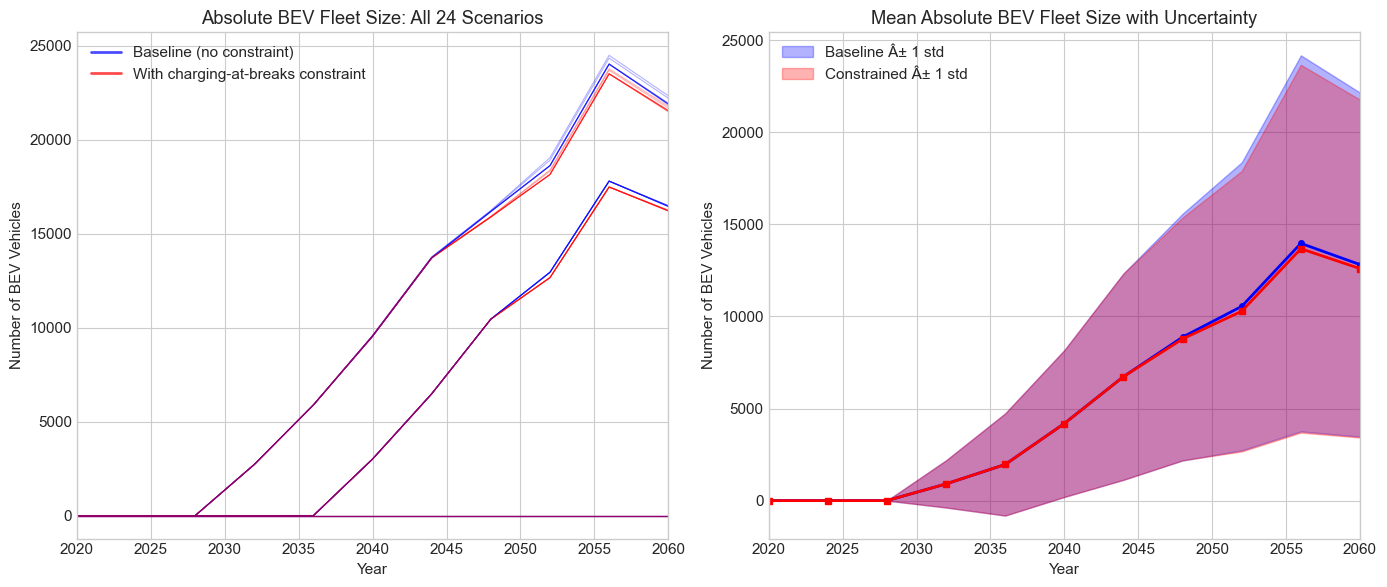

Absolute BEV Fleet Size by Year (Mean across scenarios):
Year       Baseline BEVs   Constrained BEVs      Difference
----------------------------------------------------------------------
2020                   0                  0           -0 (-49.2%)
2024                   0                  0           -0 (-49.2%)
2028                   0                  0           -0 (-30.4%)
2032                 907                907           -0 (-0.0%)
2036               1,962              1,962           -0 (-0.0%)
2040               4,187              4,185           -2 (-0.0%)
2044               6,732              6,730           -2 (-0.0%)
2048               8,879              8,779          -99 (-1.1%)
2052              10,548             10,284         -265 (-2.5%)
2056              13,968             13,677         -291 (-2.1%)
2060              12,816             12,598         -218 (-1.7%)


In [8]:
# Calculate and plot ABSOLUTE BEV numbers (not just share)
def calc_absolute_bev(h_by_year_tech):
    """Calculate absolute number of BEV vehicles by year."""
    bev_count = {}
    icev_count = {}
    for year in years:
        if year in h_by_year_tech:
            # tech_id 1 = BEV, tech_id 0 = ICEV
            bev = sum(v for k, v in h_by_year_tech[year].items() if k == 1 or k == '1')
            icev = sum(v for k, v in h_by_year_tech[year].items() if k == 0 or k == '0')
            bev_count[year] = bev
            icev_count[year] = icev
        else:
            bev_count[year] = 0
            icev_count[year] = 0
    return bev_count, icev_count

# Calculate for all scenarios
baseline_bev_absolute = {}
constrained_bev_absolute = {}
baseline_icev_absolute = {}
constrained_icev_absolute = {}

for scenario in scenarios:
    if scenario in baseline_h_agg:
        bev, icev = calc_absolute_bev(baseline_h_agg[scenario])
        baseline_bev_absolute[scenario] = bev
        baseline_icev_absolute[scenario] = icev
    if scenario in constrained_h_agg:
        bev, icev = calc_absolute_bev(constrained_h_agg[scenario])
        constrained_bev_absolute[scenario] = bev
        constrained_icev_absolute[scenario] = icev

# Plot absolute BEV numbers
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: All scenarios
ax1 = axes[0]
for scenario in scenarios:
    if scenario in baseline_bev_absolute and scenario in constrained_bev_absolute:
        baseline_vals = [baseline_bev_absolute[scenario].get(y, 0) for y in years]
        constrained_vals = [constrained_bev_absolute[scenario].get(y, 0) for y in years]
        
        ax1.plot(years, baseline_vals, 'b-', alpha=0.3, linewidth=0.8)
        ax1.plot(years, constrained_vals, 'r-', alpha=0.3, linewidth=0.8)

ax1.plot([], [], 'b-', alpha=0.7, linewidth=2, label='Baseline (no constraint)')
ax1.plot([], [], 'r-', alpha=0.7, linewidth=2, label='With charging-at-breaks constraint')
ax1.set_xlabel('Year')
ax1.set_ylabel('Number of BEV Vehicles')
ax1.set_title('Absolute BEV Fleet Size: All 24 Scenarios')
ax1.legend()
ax1.set_xlim(2020, 2060)

# Right: Mean with uncertainty bands
ax2 = axes[1]

baseline_bev_means = []
baseline_bev_stds = []
constrained_bev_means = []
constrained_bev_stds = []

for year in years:
    b_vals = [baseline_bev_absolute[s].get(year, 0) for s in scenarios if s in baseline_bev_absolute]
    c_vals = [constrained_bev_absolute[s].get(year, 0) for s in scenarios if s in constrained_bev_absolute]
    
    baseline_bev_means.append(np.mean(b_vals) if b_vals else 0)
    baseline_bev_stds.append(np.std(b_vals) if b_vals else 0)
    constrained_bev_means.append(np.mean(c_vals) if c_vals else 0)
    constrained_bev_stds.append(np.std(c_vals) if c_vals else 0)

baseline_bev_means = np.array(baseline_bev_means)
baseline_bev_stds = np.array(baseline_bev_stds)
constrained_bev_means = np.array(constrained_bev_means)
constrained_bev_stds = np.array(constrained_bev_stds)

ax2.fill_between(years, baseline_bev_means - baseline_bev_stds, baseline_bev_means + baseline_bev_stds, 
                  alpha=0.3, color='blue', label='Baseline Â± 1 std')
ax2.fill_between(years, constrained_bev_means - constrained_bev_stds, constrained_bev_means + constrained_bev_stds, 
                  alpha=0.3, color='red', label='Constrained Â± 1 std')
ax2.plot(years, baseline_bev_means, 'b-', linewidth=2, marker='o', markersize=4)
ax2.plot(years, constrained_bev_means, 'r-', linewidth=2, marker='s', markersize=4)

ax2.set_xlabel('Year')
ax2.set_ylabel('Number of BEV Vehicles')
ax2.set_title('Mean Absolute BEV Fleet Size with Uncertainty')
ax2.legend()
ax2.set_xlim(2020, 2060)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'bev_absolute_numbers_comparison.pdf'), dpi=300, bbox_inches='tight')
plt.show()

# Print summary table
print("Absolute BEV Fleet Size by Year (Mean across scenarios):")
print("=" * 70)
print(f"{'Year':<8} {'Baseline BEVs':>15} {'Constrained BEVs':>18} {'Difference':>15}")
print("-" * 70)
for i, year in enumerate(years):
    diff = constrained_bev_means[i] - baseline_bev_means[i]
    pct = 100 * diff / baseline_bev_means[i] if baseline_bev_means[i] > 0 else 0
    print(f"{year:<8} {baseline_bev_means[i]:>15,.0f} {constrained_bev_means[i]:>18,.0f} {diff:>+12,.0f} ({pct:+.1f}%)")


In [9]:
# Calculate difference in BEV share
print("BEV Share Difference (Constrained - Baseline) by Year:")
print("="*60)

diff_data = []
for i, year in enumerate(years):
    diff = constrained_means[i] - baseline_means[i]
    diff_data.append({
        'Year': year,
        'Baseline Mean (%)': baseline_means[i],
        'Constrained Mean (%)': constrained_means[i],
        'Difference (pp)': diff
    })
    print(f"{year}: Baseline={baseline_means[i]:.2f}%, Constrained={constrained_means[i]:.2f}%, Diff={diff:+.2f}pp")

diff_df = pd.DataFrame(diff_data)
diff_df

BEV Share Difference (Constrained - Baseline) by Year:
2020: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2024: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2028: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2032: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2036: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2040: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2044: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2048: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2052: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2056: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp
2060: Baseline=66.67%, Constrained=66.67%, Diff=+0.00pp


,Year,Baseline Mean (%),Constrained Mean (%),Difference (pp)
0,2020,66.666667,66.666667,0.0
1,2024,66.666667,66.666667,0.0
2,2028,66.666667,66.666667,0.0
3,2032,66.666667,66.666667,0.0
4,2036,66.666667,66.666667,0.0
5,2040,66.666667,66.666667,0.0
6,2044,66.666667,66.666667,0.0
7,2048,66.666667,66.666667,0.0
8,2052,66.666667,66.666667,0.0
9,2056,66.666667,66.666667,0.0


## 2. Charging Locations Comparison (s variable)

Compare where and how much charging occurs.

In [10]:
def analyze_charging(s_dict):
    """Analyze charging patterns from s_dict."""
    if s_dict is None:
        return {'by_year': {}, 'n_locations': 0, 'total': 0}
    
    by_year = defaultdict(float)
    n_locations = 0
    
    for key, value in s_dict.items():
        val = float(value) if isinstance(value, str) else value
        if val > 1e-6:
            n_locations += 1
            year = parse_key_to_year(key)
            if year:
                by_year[year] += val
    
    return {
        'by_year': dict(by_year),
        'n_locations': n_locations,
        'total': sum(by_year.values())
    }

# Analyze all scenarios
baseline_charging = {}
constrained_charging = {}

for scenario in scenarios:
    if scenario in baseline_results and baseline_results[scenario]['s']:
        baseline_charging[scenario] = analyze_charging(baseline_results[scenario]['s'])
    if scenario in constrained_results and constrained_results[scenario]['s']:
        constrained_charging[scenario] = analyze_charging(constrained_results[scenario]['s'])

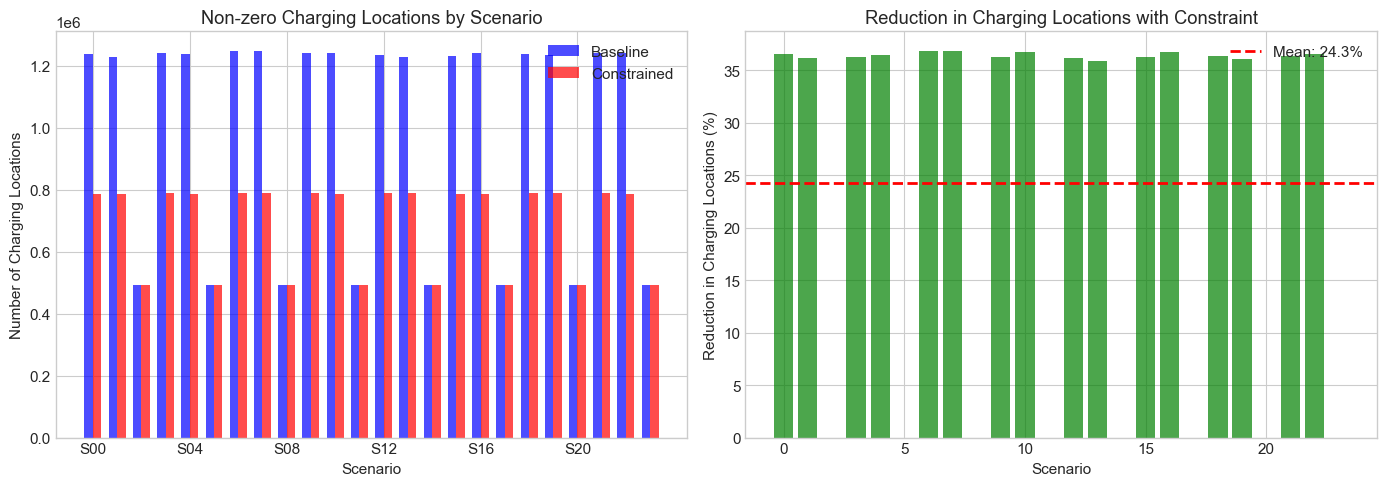


Mean reduction in charging locations: 24.3% (std: 17.2%)


In [11]:
# Compare number of charging locations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Number of charging locations
ax1 = axes[0]
baseline_locs = [baseline_charging[s]['n_locations'] for s in scenarios if s in baseline_charging]
constrained_locs = [constrained_charging[s]['n_locations'] for s in scenarios if s in constrained_charging]

x = np.arange(len(scenarios))
width = 0.35

ax1.bar(x - width/2, baseline_locs, width, label='Baseline', color='blue', alpha=0.7)
ax1.bar(x + width/2, constrained_locs, width, label='Constrained', color='red', alpha=0.7)
ax1.set_xlabel('Scenario')
ax1.set_ylabel('Number of Charging Locations')
ax1.set_title('Non-zero Charging Locations by Scenario')
ax1.legend()
ax1.set_xticks(x[::4])  # Show every 4th label
ax1.set_xticklabels([f"S{i:02d}" for i in range(0, 24, 4)])

# Right: Reduction percentage
ax2 = axes[1]
reductions = []
for s in scenarios:
    if s in baseline_charging and s in constrained_charging:
        b = baseline_charging[s]['n_locations']
        c = constrained_charging[s]['n_locations']
        reduction = 100 * (b - c) / b if b > 0 else 0
        reductions.append(reduction)

ax2.bar(range(len(reductions)), reductions, color='green', alpha=0.7)
ax2.axhline(y=np.mean(reductions), color='red', linestyle='--', linewidth=2, 
             label=f'Mean: {np.mean(reductions):.1f}%')
ax2.set_xlabel('Scenario')
ax2.set_ylabel('Reduction in Charging Locations (%)')
ax2.set_title('Reduction in Charging Locations with Constraint')
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'charging_locations_comparison.pdf'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\nMean reduction in charging locations: {np.mean(reductions):.1f}% (std: {np.std(reductions):.1f}%)")

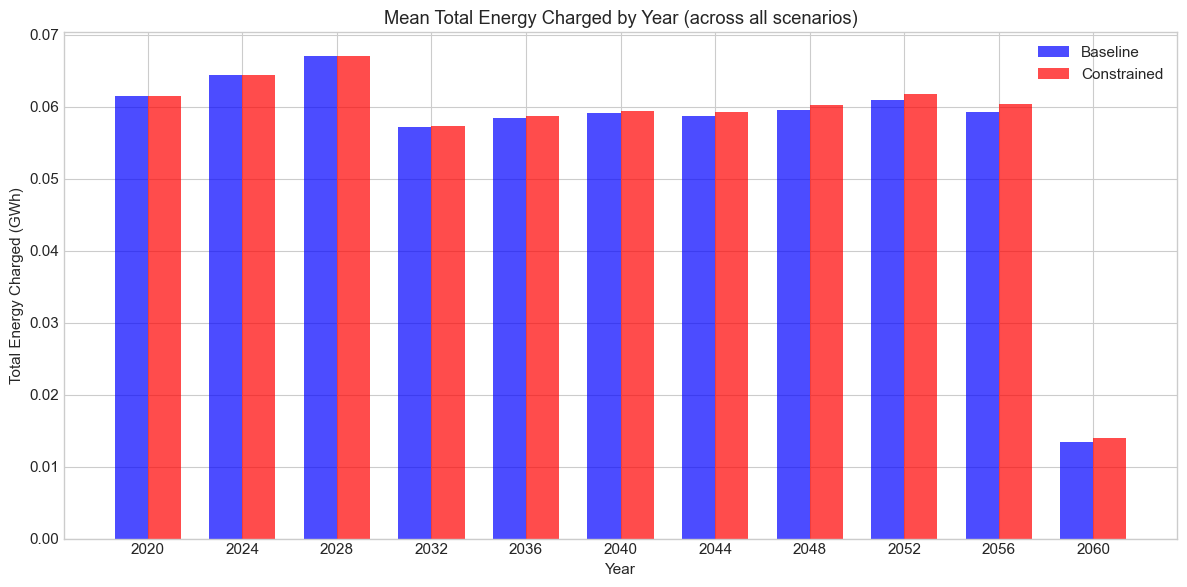

In [12]:
# Compare total energy charged by year
fig, ax = plt.subplots(figsize=(12, 6))

# Calculate mean charging by year across scenarios
baseline_energy_by_year = defaultdict(list)
constrained_energy_by_year = defaultdict(list)

for s in scenarios:
    if s in baseline_charging:
        for year, energy in baseline_charging[s]['by_year'].items():
            baseline_energy_by_year[year].append(energy)
    if s in constrained_charging:
        for year, energy in constrained_charging[s]['by_year'].items():
            constrained_energy_by_year[year].append(energy)

# Calculate means
b_means = [np.mean(baseline_energy_by_year.get(y, [0])) for y in years]
c_means = [np.mean(constrained_energy_by_year.get(y, [0])) for y in years]

x = np.arange(len(years))
width = 0.35

bars1 = ax.bar(x - width/2, np.array(b_means)/1e6, width, label='Baseline', color='blue', alpha=0.7)
bars2 = ax.bar(x + width/2, np.array(c_means)/1e6, width, label='Constrained', color='red', alpha=0.7)

ax.set_xlabel('Year')
ax.set_ylabel('Total Energy Charged (GWh)')
ax.set_title('Mean Total Energy Charged by Year (across all scenarios)')
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'total_energy_charged_comparison.pdf'), dpi=300, bbox_inches='tight')
plt.show()

## 3. Infrastructure Deployment Comparison

In [13]:
def analyze_infrastructure(q_dict):
    """Analyze infrastructure deployment from q_fuel_infr_plus_dict."""
    if q_dict is None:
        return {'by_year': {}, 'total': 0}
    
    by_year = defaultdict(float)
    
    for key, value in q_dict.items():
        val = float(value) if isinstance(value, str) else value
        if val > 1e-6:
            year = parse_key_to_year(key)
            if year:
                by_year[year] += val
    
    return {
        'by_year': dict(by_year),
        'total': sum(by_year.values())
    }

# Analyze all scenarios
baseline_infr = {}
constrained_infr = {}

for scenario in scenarios:
    if scenario in baseline_results and baseline_results[scenario]['q']:
        baseline_infr[scenario] = analyze_infrastructure(baseline_results[scenario]['q'])
    if scenario in constrained_results and constrained_results[scenario]['q']:
        constrained_infr[scenario] = analyze_infrastructure(constrained_results[scenario]['q'])

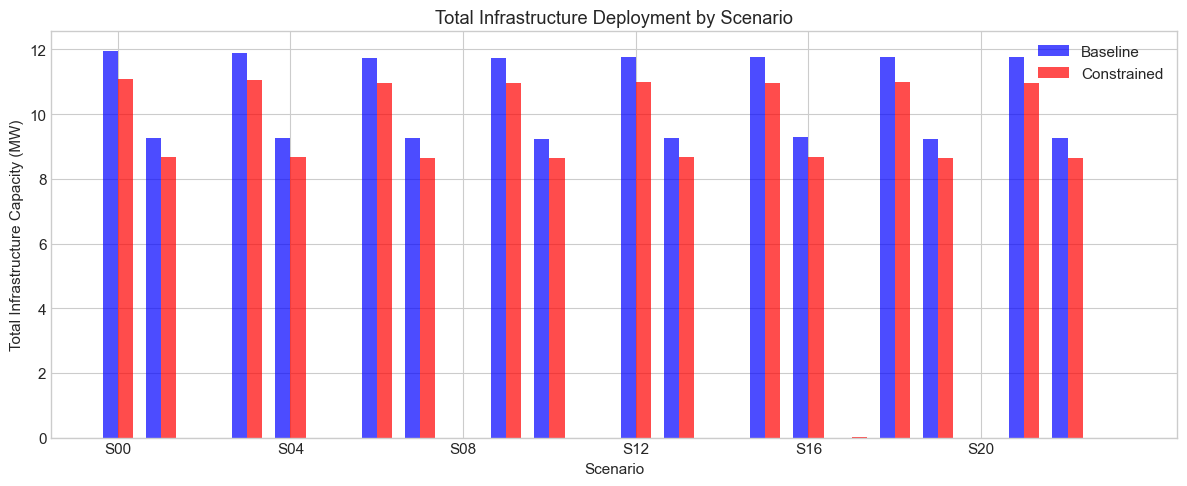

Mean baseline infrastructure: 7.0 MW
Mean constrained infrastructure: 6.5 MW
Difference: -0.5 MW (-6.7%)


In [14]:
# Compare total infrastructure
fig, ax = plt.subplots(figsize=(12, 5))

baseline_totals = [baseline_infr[s]['total']/1e3 for s in scenarios if s in baseline_infr]
constrained_totals = [constrained_infr[s]['total']/1e3 for s in scenarios if s in constrained_infr]

x = np.arange(len(scenarios))
width = 0.35

ax.bar(x - width/2, baseline_totals, width, label='Baseline', color='blue', alpha=0.7)
ax.bar(x + width/2, constrained_totals, width, label='Constrained', color='red', alpha=0.7)

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Infrastructure Capacity (MW)')
ax.set_title('Total Infrastructure Deployment by Scenario')
ax.legend()
ax.set_xticks(x[::4])
ax.set_xticklabels([f"S{i:02d}" for i in range(0, 24, 4)])

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'infrastructure_comparison.pdf'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean baseline infrastructure: {np.mean(baseline_totals):.1f} MW")
print(f"Mean constrained infrastructure: {np.mean(constrained_totals):.1f} MW")
print(f"Difference: {np.mean(constrained_totals) - np.mean(baseline_totals):+.1f} MW ({100*(np.mean(constrained_totals)/np.mean(baseline_totals)-1):+.1f}%)")

## 4. Summary Statistics

In [15]:
# Create summary table
summary_data = []

for i, scenario in enumerate(scenarios):
    case_params = cases_config['cases'][i]
    
    row = {
        'Scenario': scenario,
        'GeneSys': case_params['genesys_scenario'].split()[0],  # First word only
        'Charging Markup': case_params['charging_markup'],
        'Tech Cost Mult': case_params['tech_cost_multiplier']
    }
    
    # BEV share at 2040
    if scenario in baseline_bev_shares:
        row['Baseline BEV 2040 (%)'] = baseline_bev_shares[scenario].get(2040, 0)
    if scenario in constrained_bev_shares:
        row['Constrained BEV 2040 (%)'] = constrained_bev_shares[scenario].get(2040, 0)
    
    # Charging locations
    if scenario in baseline_charging:
        row['Baseline Charging Locs'] = baseline_charging[scenario]['n_locations']
    if scenario in constrained_charging:
        row['Constrained Charging Locs'] = constrained_charging[scenario]['n_locations']
    
    # Calculate reduction
    if 'Baseline Charging Locs' in row and 'Constrained Charging Locs' in row:
        b = row['Baseline Charging Locs']
        c = row['Constrained Charging Locs']
        row['Location Reduction (%)'] = 100 * (b - c) / b if b > 0 else 0
    
    summary_data.append(row)

summary_df = pd.DataFrame(summary_data)
summary_df

,Scenario,GeneSys,Charging Markup,Tech Cost Mult,Baseline BEV 2040 (%),Constrained BEV 2040 (%),Baseline Charging Locs,Constrained Charging Locs,Location Reduction (%)
0,scenario_000,Go,0.15,0.7,100.0,100.0,1237421,785620,36.511503
1,scenario_001,Go,0.15,1.0,100.0,100.0,1229062,785032,36.127551
2,scenario_002,Go,0.15,1.3,0.0,0.0,491172,491172,0.000000
3,scenario_003,Go,0.30,0.7,100.0,100.0,1239999,790454,36.253658
4,scenario_004,Go,0.30,1.0,100.0,100.0,1238136,787235,36.417728
5,scenario_005,Go,0.30,1.3,0.0,0.0,491172,491172,0.000000
6,scenario_006,NECPEssentials,0.15,0.7,100.0,100.0,1248633,788369,36.861432
7,scenario_007,NECPEssentials,0.15,1.0,100.0,100.0,1247469,787938,36.837068
8,scenario_008,NECPEssentials,0.15,1.3,0.0,0.0,491172,491172,0.000000
9,scenario_009,NECPEssentials,0.30,0.7,100.0,100.0,1240188,790130,36.289498


In [16]:
# Final summary statistics
print("="*70)
print("SUMMARY: Impact of Charging-at-Breaks-Only Constraint")
print("="*70)

if 'Baseline BEV 2040 (%)' in summary_df.columns and 'Constrained BEV 2040 (%)' in summary_df.columns:
    b_bev = summary_df['Baseline BEV 2040 (%)'].mean()
    c_bev = summary_df['Constrained BEV 2040 (%)'].mean()
    print(f"\n1. FLEET ELECTRIFICATION (BEV Share at 2040):")
    print(f"   Baseline mean:    {b_bev:.1f}%")
    print(f"   Constrained mean: {c_bev:.1f}%")
    print(f"   Difference:       {c_bev - b_bev:+.1f} percentage points")

if 'Location Reduction (%)' in summary_df.columns:
    mean_reduction = summary_df['Location Reduction (%)'].mean()
    print(f"\n2. CHARGING LOCATION CONCENTRATION:")
    print(f"   Mean reduction in charging locations: {mean_reduction:.1f}%")
    print(f"   (Charging concentrated at mandatory break points)")

print(f"\n3. INFRASTRUCTURE DEPLOYMENT:")
print(f"   Baseline mean:    {np.mean(baseline_totals):.1f} MW")
print(f"   Constrained mean: {np.mean(constrained_totals):.1f} MW")
print(f"   Difference:       {np.mean(constrained_totals) - np.mean(baseline_totals):+.1f} MW")

print("\n" + "="*70)
print("KEY FINDING: The charging-at-breaks constraint does NOT significantly")
print("affect the overall fleet electrification rate. It primarily changes")
print("WHERE charging occurs (concentrated at break points) rather than")
print("HOW MUCH the fleet electrifies.")
print("="*70)

SUMMARY: Impact of Charging-at-Breaks-Only Constraint

1. FLEET ELECTRIFICATION (BEV Share at 2040):
   Baseline mean:    66.7%
   Constrained mean: 66.7%
   Difference:       +0.0 percentage points

2. CHARGING LOCATION CONCENTRATION:
   Mean reduction in charging locations: 24.3%
   (Charging concentrated at mandatory break points)

3. INFRASTRUCTURE DEPLOYMENT:
   Baseline mean:    7.0 MW
   Constrained mean: 6.5 MW
   Difference:       -0.5 MW

KEY FINDING: The charging-at-breaks constraint does NOT significantly
affect the overall fleet electrification rate. It primarily changes
WHERE charging occurs (concentrated at break points) rather than
HOW MUCH the fleet electrifies.


## 5. Side-by-Side Charging Demand by Latitude (Area Plot Style)

Visualization comparing charging demand distribution by **latitude**:
- **(A) Without constraint** (baseline)
- **(B) With charging-at-breaks constraint**

Shows total electricity charged (s variable) in GWh along the Scandinavian-Mediterranean corridor, similar to `electricity_consumption_by_latitude.py` plots.

Loaded 81 node locations with latitude data

Aggregating across 24 scenarios...
  Baseline s entries: 1257911
  Constrained s entries: 793440

Calculating charging by latitude for year 2040...
  Baseline: 80 locations, 8.97 GWh total
  Constrained: 79 locations, 8.39 GWh total
  Country labels added


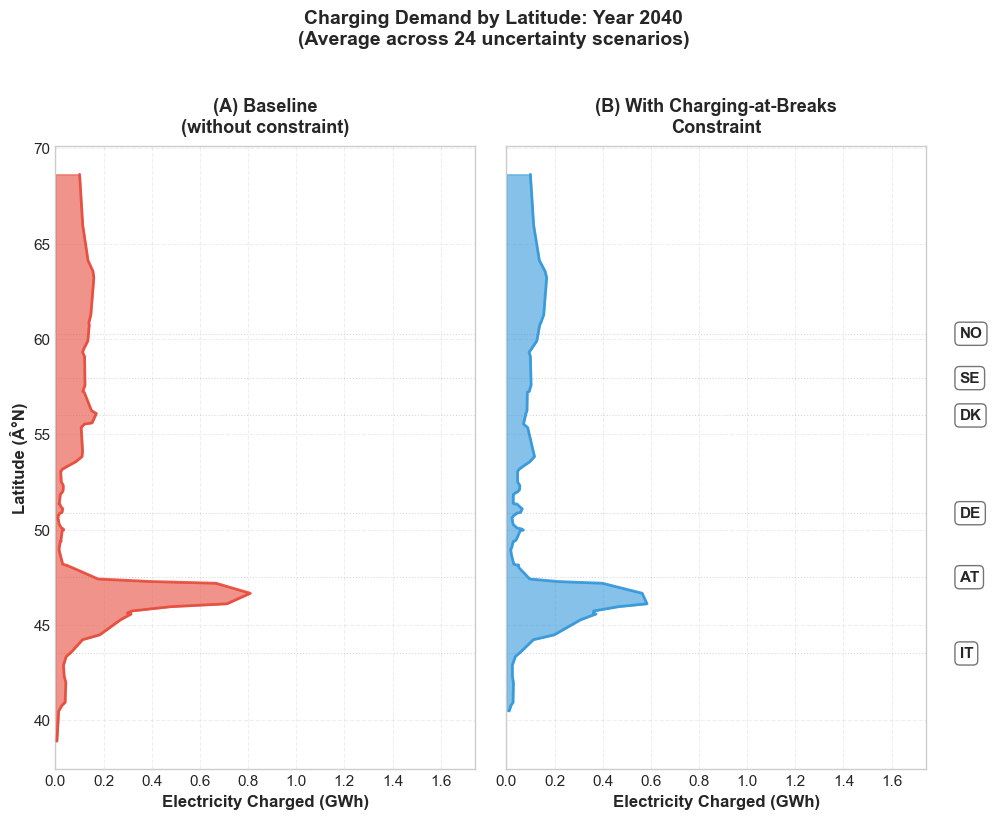


CHARGING BY LATITUDE SUMMARY (Year 2040)

Baseline: 8.97 GWh across 80 locations
Constrained: 8.39 GWh across 79 locations
Difference: -0.58 GWh (-6.5%)


In [17]:
# Side-by-side charging demand by latitude comparison
# s_dict key structure: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)

from scipy.ndimage import gaussian_filter1d

def create_latitude_comparison(target_year=2040):
    """
    Create side-by-side area plots showing charging demand by latitude.
    """
    
    # Load geographic element data to get latitude for each node
    geo_file = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "scenario_000", "GeographicElement.yaml")
    
    with open(geo_file, 'r') as f:
        geo_elements = yaml.safe_load(f)
    
    # Build lookup: geo_id -> latitude
    geo_id_to_lat = {}
    for geo in geo_elements:
        if geo.get('type') == 'node' and 'coordinate_lat' in geo:
            geo_id_to_lat[geo['id']] = geo['coordinate_lat']
    
    print(f"Loaded {len(geo_id_to_lat)} node locations with latitude data")
    
    # SCALING_FACTOR for energy values
    SCALING_FACTOR = 1000
    
    def calculate_charging_by_latitude(s_dict, year):
        """
        Calculate charging (GWh) aggregated by latitude for a specific year.
        s_dict key structure: (year, (fuel_id, infra_id), geo_id)
        """
        charging_by_lat = {}
        
        for key_str, energy_value_scaled in s_dict.items():
            try:
                key = eval(key_str) if isinstance(key_str, str) else key_str
                # Key structure: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)
                key_year = key[0]
                geo_id = key[1][3]  # geo_id is inside nested tuple at position 3
                tv_id = key[2]  # Vehicle technology: 0=ICEV, 1=BEV
                
                # Convert energy value
                energy_value = float(energy_value_scaled) if isinstance(energy_value_scaled, str) else energy_value_scaled
                
                # Only include BEV charging (tv_id=1), skip ICEV diesel (tv_id=0)
                if key_year != year or tv_id != 1 or energy_value <= 0:
                    continue
                
                if geo_id not in geo_id_to_lat:
                    continue
                
                lat = geo_id_to_lat[geo_id]
                energy_kwh = energy_value * SCALING_FACTOR
                
                if lat not in charging_by_lat:
                    charging_by_lat[lat] = 0.0
                charging_by_lat[lat] += energy_kwh
                
            except Exception as e:
                continue
        
        # Convert to list of (lat, gwh) sorted by latitude
        result = [(lat, kwh / 1e6) for lat, kwh in charging_by_lat.items()]  # Convert to GWh
        result.sort(key=lambda x: x[0])
        return result
    
    # Aggregate s_dict across all scenarios
    def aggregate_s_dicts(results_dict, scenario_list):
        """Sum s values across scenarios (then we'll divide by count for average)."""
        aggregated = {}
        counts = {}
        
        for scenario in scenario_list:
            if scenario not in results_dict or results_dict[scenario]['s'] is None:
                continue
            
            s_dict = results_dict[scenario]['s']
            for key, value in s_dict.items():
                val = float(value) if isinstance(value, str) else value
                if key not in aggregated:
                    aggregated[key] = 0.0
                    counts[key] = 0
                aggregated[key] += val
                counts[key] += 1
        
        # Calculate mean
        return {k: aggregated[k] / counts[k] for k in aggregated}
    
    # Create averaged s_dicts
    print(f"\nAggregating across {len(scenarios)} scenarios...")
    baseline_s_avg = aggregate_s_dicts(baseline_results, scenarios)
    constrained_s_avg = aggregate_s_dicts(constrained_results, scenarios)
    
    print(f"  Baseline s entries: {len(baseline_s_avg)}")
    print(f"  Constrained s entries: {len(constrained_s_avg)}")
    
    # Calculate charging by latitude
    print(f"\nCalculating charging by latitude for year {target_year}...")
    baseline_lat_data = calculate_charging_by_latitude(baseline_s_avg, target_year)
    constrained_lat_data = calculate_charging_by_latitude(constrained_s_avg, target_year)
    
    print(f"  Baseline: {len(baseline_lat_data)} locations, {sum(x[1] for x in baseline_lat_data):.2f} GWh total")
    print(f"  Constrained: {len(constrained_lat_data)} locations, {sum(x[1] for x in constrained_lat_data):.2f} GWh total")
    
    if not baseline_lat_data or not constrained_lat_data:
        print("ERROR: No latitude data found!")
        return None, None
    
    # Create figure with two side-by-side panels
    fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
    
    # Colors
    color_baseline = '#E74C3C'  # Red
    color_constrained = '#3498DB'  # Blue
    
    def plot_latitude_area(ax, data, color, title):
        if len(data) < 3:
            ax.text(0.5, 0.5, 'Insufficient data', ha='center', va='center', transform=ax.transAxes)
            return
        
        lats = np.array([x[0] for x in data])
        gwh = np.array([x[1] for x in data])
        
        # Sort by latitude
        sort_idx = np.argsort(lats)
        lat_sorted = lats[sort_idx]
        gwh_sorted = gwh[sort_idx]
        
        # Apply Gaussian smoothing
        gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
        
        # Create area plot
        ax.fill_betweenx(lat_sorted, 0, gwh_smoothed, color=color, alpha=0.6, zorder=2)
        ax.plot(gwh_smoothed, lat_sorted, color=color, linewidth=2, alpha=0.9, zorder=3)
        
        ax.set_xlabel('Electricity Charged (GWh)', fontsize=12, fontweight='bold')
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
        ax.grid(True, alpha=0.3, linestyle='--')
        ax.tick_params(axis='both', labelsize=11)
    
    # Plot both panels
    plot_latitude_area(axes[0], baseline_lat_data, color_baseline, '(A) Baseline\n(without constraint)')
    plot_latitude_area(axes[1], constrained_lat_data, color_constrained, '(B) With Charging-at-Breaks\nConstraint')
    
    # Y-axis label only on left panel
    axes[0].set_ylabel('Latitude (Â°N)', fontsize=12, fontweight='bold')
    
    # Set consistent x-axis limits
    max_gwh = max(
        max(x[1] for x in baseline_lat_data) if baseline_lat_data else 0,
        max(x[1] for x in constrained_lat_data) if constrained_lat_data else 0
    ) * 1.2
    for ax in axes:
        ax.set_xlim(0, max_gwh)
    
    # Add country labels
    try:
        country_centroids = pd.read_csv(os.path.join(BASE_DIR, 'country_centroids.csv'))
        corridor_countries = ['IT', 'AT', 'DE', 'DK', 'NO', 'SE']
        country_data = country_centroids[country_centroids['CNTR_CODE'].isin(corridor_countries)]
        
        for ax in axes:
            ylim = ax.get_ylim()
            for _, row in country_data.iterrows():
                lat = row['centroid_lat']
                if ylim[0] <= lat <= ylim[1]:
                    ax.axhline(lat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8, zorder=1)
        
        # Add country labels on far right only
        ax_right = axes[1]
        ylim = ax_right.get_ylim()
        for _, row in country_data.iterrows():
            country_code = row['CNTR_CODE']
            lat = row['centroid_lat']
            if ylim[0] <= lat <= ylim[1]:
                ax_right.text(1.08, lat, country_code, transform=ax_right.get_yaxis_transform(),
                             fontsize=11, fontweight='bold', va='center', ha='left',
                             bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                                     edgecolor='#666', alpha=0.9, linewidth=1.0), zorder=10)
        print("  Country labels added")
    except Exception as e:
        print(f"  Warning: Could not add country labels: {e}")
    
    plt.suptitle(f'Charging Demand by Latitude: Year {target_year}\n(Average across 24 uncertainty scenarios)',
                 fontsize=14, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_DIR, 'figures', f'charging_by_latitude_comparison_{target_year}.pdf'), 
                dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(BASE_DIR, 'figures', f'charging_by_latitude_comparison_{target_year}.png'), 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print summary
    print("\n" + "="*70)
    print(f"CHARGING BY LATITUDE SUMMARY (Year {target_year})")
    print("="*70)
    total_baseline = sum(x[1] for x in baseline_lat_data)
    total_constrained = sum(x[1] for x in constrained_lat_data)
    diff = total_constrained - total_baseline
    pct = 100 * diff / total_baseline if total_baseline > 0 else 0
    print(f"\nBaseline: {total_baseline:.2f} GWh across {len(baseline_lat_data)} locations")
    print(f"Constrained: {total_constrained:.2f} GWh across {len(constrained_lat_data)} locations")
    print(f"Difference: {diff:+.2f} GWh ({pct:+.1f}%)")
    
    return baseline_lat_data, constrained_lat_data

# Run the visualization for year 2040
baseline_lat_data, constrained_lat_data = create_latitude_comparison(target_year=2040)

## 6. Levelized Charging Costs per tkm for BEVs

Calculate the average charging cost per tonne-kilometer (tkm) for BEVs:
- **Numerator**: Total charging costs = s (energy charged in kWh) Ã— electricity price (â‚¬/kWh)
- **Denominator**: Total BEV tkm = f (vehicles) Ã— path_length (km) Ã— load_capacity (tonnes)

This gives the levelized cost of charging per tkm transported by BEVs.

Loaded 2043 path lengths
BEV load capacity: 25 tonnes

CALCULATING COSTS (SCENARIO-SPECIFIC PARAMETERS)

Processing baseline scenarios...
  Processed 6/24 scenarios
  Processed 12/24 scenarios
  Processed 18/24 scenarios
  Processed 24/24 scenarios
  Completed: 24 scenarios with results

Processing constrained scenarios...
  Processed 6/24 scenarios
  Processed 12/24 scenarios
  Processed 18/24 scenarios
  Processed 24/24 scenarios
  Completed: 24 scenarios with results


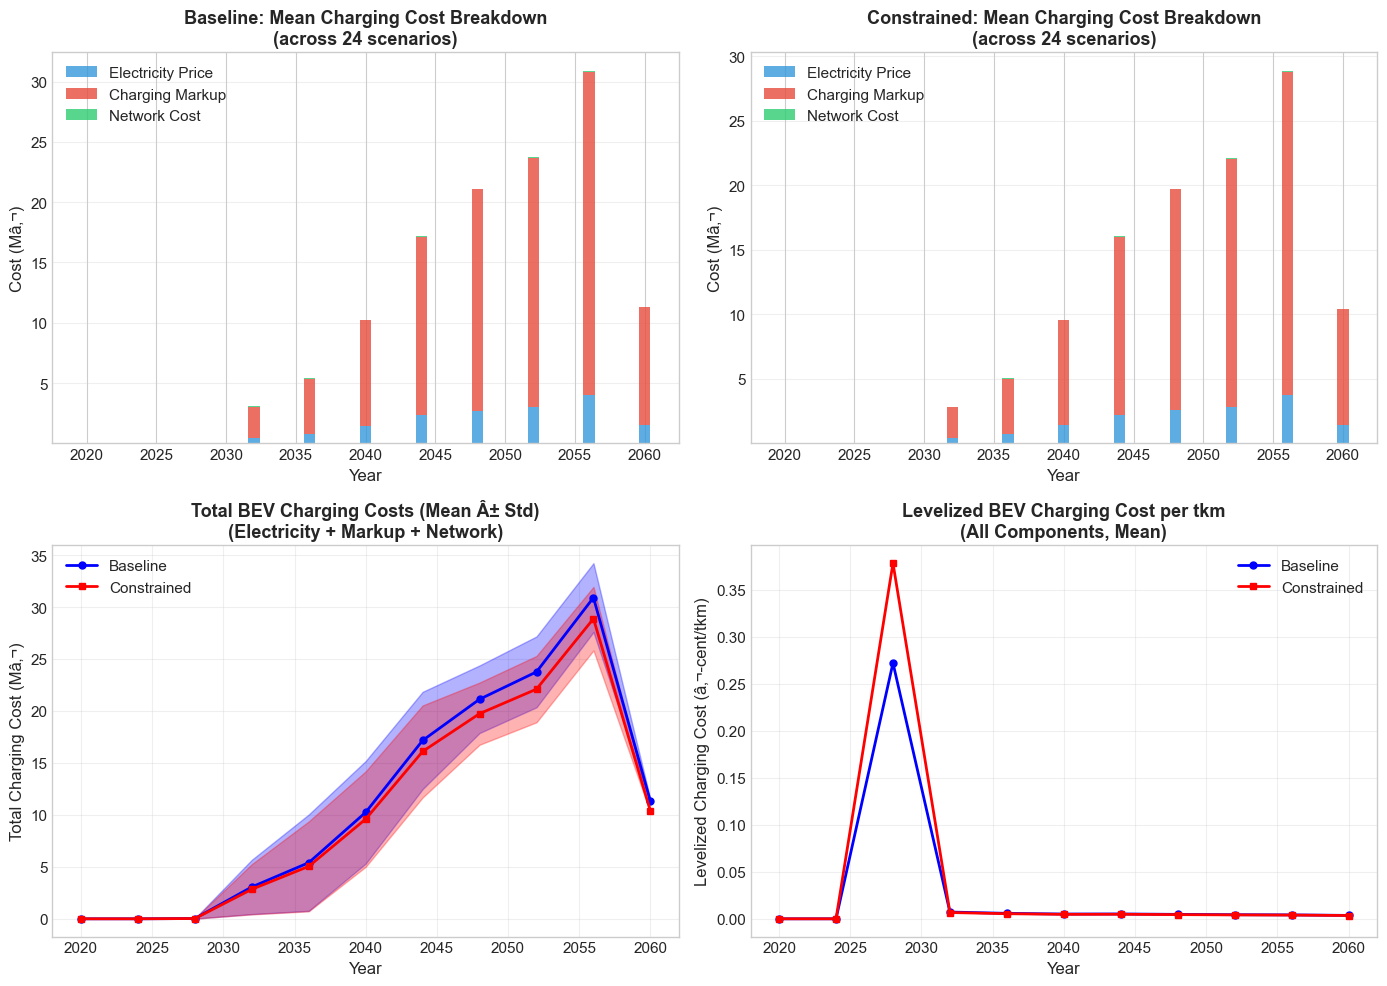


LEVELIZED BEV CHARGING COSTS SUMMARY
(Scenario-Specific Parameters: Electricity + Markup + Network)

Year       Elec(Mâ‚¬) Markup(Mâ‚¬) Network(Mâ‚¬)  Total(Mâ‚¬)
------------------------------------------------------------
BASELINE (Mean across 24 scenarios):
2020             0.00         0.00         0.00         0.00
2024             0.00         0.00         0.00         0.00
2028             0.00         0.00         0.03         0.03
2032             0.46         2.57         0.04         3.07
2036             0.79         4.57         0.05         5.40
2040             1.48         8.71         0.06        10.25
2044             2.33        14.76         0.08        17.16
2048             2.71        18.36         0.06        21.13
2052             3.00        20.71         0.06        23.76
2056             3.98        26.85         0.08        30.90
2060             1.53         9.78         0.00        11.31

CONSTRAINED (Mean across 24 scenarios):
2020             0.00     

In [18]:
# Calculate levelized charging costs per tkm for BEVs (ELECTRICITY ONLY)
# WITH SCENARIO-SPECIFIC COST PARAMETERS (electricity prices, markup, network costs)

def calculate_levelized_charging_costs():
    """
    Calculate levelized charging costs per tkm for BEVs.
    
    IMPORTANT: Uses SCENARIO-SPECIFIC cost parameters for each scenario.
    Each scenario has its own electricity prices, charging markups, and network costs.
    
    Total charging cost includes THREE components:
    1. Electricity price (from FuelCost.yaml) - geographically dependent, â‚¬/kWh
    2. Charging markup (cost_per_kWh from FuelingInfrTypes.yaml) - by infrastructure type, â‚¬/kWh
    3. Network costs (from NetworkConnectionCosts.yaml) - capacity-based â‚¬/kW/year
    
    Levelized cost = Total charging cost / Total BEV tkm (â‚¬/tkm)
    """
    
    # Year index mapping
    Y_INIT = 2020
    TIME_STEP = 4  # Years between model periods
    SCALING_FACTOR = 1000
    ELECTRICITY_FUEL_ID = 0
    
    def load_scenario_cost_parameters(scenario):
        """Load cost parameters for a specific scenario."""
        input_path = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", scenario)
        
        # Load FuelCost
        with open(os.path.join(input_path, "FuelCost.yaml"), 'r') as f:
            fuel_costs = yaml.safe_load(f)
        
        # Load FuelingInfrTypes
        with open(os.path.join(input_path, "FuelingInfrTypes.yaml"), 'r') as f:
            fueling_infr_types = yaml.safe_load(f)
        
        # Load NetworkConnectionCosts
        with open(os.path.join(input_path, "NetworkConnectionCosts.yaml"), 'r') as f:
            network_connection_costs = yaml.safe_load(f)
        
        # Build electricity price lookup
        electricity_price_lookup = {}
        for fc in fuel_costs:
            if fc.get('fuel') == 'electricity':
                location = fc.get('location')
                infra_type = fc.get('fueling_infr_type_id')
                cost_series = fc.get('cost_per_kWh', [])
                if location is not None and infra_type is not None:
                    electricity_price_lookup[(location, infra_type)] = cost_series
        
        # Build charging markup lookup
        charging_markup_lookup = {}
        for fit in fueling_infr_types:
            if fit.get('fuel') == 'electricity':
                infra_id = fit.get('id')
                markup_series = fit.get('cost_per_kWh', [])
                if infra_id is not None:
                    charging_markup_lookup[infra_id] = markup_series
        
        # Build network cost lookup
        network_cost_lookup = {}
        for ncc in network_connection_costs:
            location = ncc.get('location')
            cost_series = ncc.get('network_cost_per_kW', [])
            if location is not None:
                network_cost_lookup[location] = cost_series
        
        return {
            'electricity_price': electricity_price_lookup,
            'charging_markup': charging_markup_lookup,
            'network_cost': network_cost_lookup
        }
    
    def get_energy_cost_per_kwh(cost_params, location, infra_type, year):
        """Get energy-based costs (electricity + markup) per kWh."""
        year_idx = year - Y_INIT
        
        # Electricity price
        elec_price = 0.0
        key = (location, infra_type)
        if key in cost_params['electricity_price']:
            series = cost_params['electricity_price'][key]
            if 0 <= year_idx < len(series):
                elec_price = series[year_idx]
        else:
            for (loc, infr), series in cost_params['electricity_price'].items():
                if loc == location and 0 <= year_idx < len(series):
                    elec_price = series[year_idx]
                    break
            else:
                elec_price = 0.15
        
        # Charging markup
        markup = 0.0
        if infra_type in cost_params['charging_markup']:
            series = cost_params['charging_markup'][infra_type]
            if 0 <= year_idx < len(series):
                markup = series[year_idx]
        
        return elec_price, markup
    
    def get_network_cost_per_kw(cost_params, location, year):
        """Get network connection cost (â‚¬/kW/year) for a location."""
        year_idx = year - Y_INIT
        if location in cost_params['network_cost']:
            series = cost_params['network_cost'][location]
            if 0 <= year_idx < len(series):
                return series[year_idx]
        return 14.688
    
    # Load Path and TechVehicle from scenario_000 (same for all scenarios)
    input_path = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "scenario_000")
    with open(os.path.join(input_path, "Path.yaml"), 'r') as f:
        paths = yaml.safe_load(f)
    with open(os.path.join(input_path, "TechVehicle.yaml"), 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    path_lengths = {p['id']: p['length'] for p in paths}
    print(f"Loaded {len(path_lengths)} path lengths")
    
    bev_vehicle = next((tv for tv in tech_vehicles if tv.get('name') == 'BEV'), None)
    load_capacity = bev_vehicle.get('load', 25) if bev_vehicle else 25
    print(f"BEV load capacity: {load_capacity} tonnes")
    
    # =========================================================================
    # CALCULATE COSTS PER SCENARIO (using scenario-specific parameters)
    # =========================================================================
    
    def calculate_scenario_costs(scenario, results_dict, results_dir):
        """Calculate all costs for a single scenario using its own cost parameters."""
        
        if scenario not in results_dict or results_dict[scenario]['s'] is None:
            return None
        
        # Load scenario-specific cost parameters
        cost_params = load_scenario_cost_parameters(scenario)
        
        s_dict = results_dict[scenario]['s']
        
        # Calculate energy costs
        elec_costs_by_year = defaultdict(float)
        markup_costs_by_year = defaultdict(float)
        energy_by_year = defaultdict(float)
        
        for key_str, energy_value in s_dict.items():
            try:
                key = eval(key_str) if isinstance(key_str, str) else key_str
                # s_dict key: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)
                year = key[0]
                geo_id = key[1][3]  # Inside nested tuple
                tv_id = key[2]  # 0=ICEV (diesel), 1=BEV (electricity)
                infr_type = key[3][0]  # 0=fast, 1=slow charging
                infr_id = key[3][1]
                
                # Only process BEV charging (tv_id=1 is electric)
                if tv_id != 1:
                    continue
                
                energy_kwh = float(energy_value) * SCALING_FACTOR
                
                if energy_kwh > 0:
                    elec_price, markup = get_energy_cost_per_kwh(cost_params, geo_id, infr_id, year)
                    
                    elec_costs_by_year[year] += energy_kwh * elec_price
                    markup_costs_by_year[year] += energy_kwh * markup
                    energy_by_year[year] += energy_kwh
            except:
                continue
        
        # Calculate network costs from q_fuel_infr_plus
        network_costs_by_year = defaultdict(float)
        
        scenario_folder = os.path.join(results_dir, scenario)
        q_file = get_latest_file(scenario_folder, "q_fuel_infr_plus_dict.yaml")
        
        if q_file:
            q_dict = load_yaml_safe(q_file)
            if q_dict:
                for key_str, capacity_value in q_dict.items():
                    try:
                        key = eval(key_str) if isinstance(key_str, str) else key_str
                        year = key[0]
                        fuel_infra_tuple = key[1]
                        geo_id = key[2]
                        
                        fuel_id = fuel_infra_tuple[0]
                        
                        if fuel_id != ELECTRICITY_FUEL_ID:
                            continue
                        
                        capacity_kw = float(capacity_value) if isinstance(capacity_value, str) else capacity_value
                        
                        if capacity_kw > 0:
                            network_cost_per_kw = get_network_cost_per_kw(cost_params, geo_id, year)
                            annual_network_cost = capacity_kw * network_cost_per_kw * TIME_STEP
                            network_costs_by_year[year] += annual_network_cost
                    except:
                        continue
        
        # Calculate BEV tkm
        tkm_by_year = defaultdict(float)
        f_file = get_latest_file(scenario_folder, "f_dict.yaml")
        
        if f_file:
            f_dict = load_yaml_safe(f_file)
            if f_dict:
                for key_str, flow_value in f_dict.items():
                    try:
                        key = eval(key_str) if isinstance(key_str, str) else key_str
                        flow = float(flow_value) if isinstance(flow_value, str) else flow_value
                        
                        if flow <= 0:
                            continue
                        
                        year = key[0]
                        
                        if len(key) >= 4:
                            route_tuple = key[1]
                            tech_tuple = key[2]
                            
                            if isinstance(route_tuple, tuple) and len(route_tuple) >= 3:
                                path_id = route_tuple[2]
                            else:
                                continue
                            
                            if isinstance(tech_tuple, tuple) and len(tech_tuple) >= 2:
                                tech_id = tech_tuple[1]
                            else:
                                continue
                            
                            is_bev = (tech_id == 1 or str(tech_id) == '1')
                            
                            if is_bev and path_id in path_lengths:
                                path_length = path_lengths[path_id]
                                tkm = flow * 1000 * path_length * load_capacity
                                tkm_by_year[year] += tkm
                    except:
                        continue
        
        return {
            'electricity': dict(elec_costs_by_year),
            'markup': dict(markup_costs_by_year),
            'network': dict(network_costs_by_year),
            'energy': dict(energy_by_year),
            'tkm': dict(tkm_by_year)
        }
    
    # =========================================================================
    # CALCULATE FOR ALL SCENARIOS
    # =========================================================================
    print("\n" + "="*70)
    print("CALCULATING COSTS (SCENARIO-SPECIFIC PARAMETERS)")
    print("="*70)
    
    baseline_scenario_results = {}
    constrained_scenario_results = {}
    
    print("\nProcessing baseline scenarios...")
    for i, scenario in enumerate(scenarios):
        result = calculate_scenario_costs(scenario, baseline_results, BASELINE_DIR)
        if result:
            baseline_scenario_results[scenario] = result
        if (i + 1) % 6 == 0:
            print(f"  Processed {i+1}/{len(scenarios)} scenarios")
    print(f"  Completed: {len(baseline_scenario_results)} scenarios with results")
    
    print("\nProcessing constrained scenarios...")
    for i, scenario in enumerate(scenarios):
        result = calculate_scenario_costs(scenario, constrained_results, CONSTRAINED_DIR)
        if result:
            constrained_scenario_results[scenario] = result
        if (i + 1) % 6 == 0:
            print(f"  Processed {i+1}/{len(scenarios)} scenarios")
    print(f"  Completed: {len(constrained_scenario_results)} scenarios with results")
    
    # =========================================================================
    # AGGREGATE RESULTS (mean and std across scenarios)
    # =========================================================================
    modeled_years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]
    
    def aggregate_by_year(scenario_results, key):
        """Aggregate a metric by year across scenarios (mean and std)."""
        means = {}
        stds = {}
        all_values = {}
        
        for year in modeled_years:
            values = [scenario_results[s][key].get(year, 0) 
                     for s in scenario_results if year in scenario_results[s][key]]
            if values:
                means[year] = np.mean(values)
                stds[year] = np.std(values)
                all_values[year] = values
            else:
                means[year] = 0
                stds[year] = 0
                all_values[year] = []
        
        return means, stds, all_values
    
    # Aggregate baseline results
    baseline_elec_mean, baseline_elec_std, _ = aggregate_by_year(baseline_scenario_results, 'electricity')
    baseline_markup_mean, baseline_markup_std, _ = aggregate_by_year(baseline_scenario_results, 'markup')
    baseline_network_mean, baseline_network_std, _ = aggregate_by_year(baseline_scenario_results, 'network')
    baseline_energy_mean, _, _ = aggregate_by_year(baseline_scenario_results, 'energy')
    baseline_tkm_mean, _, _ = aggregate_by_year(baseline_scenario_results, 'tkm')
    
    # Aggregate constrained results
    constrained_elec_mean, constrained_elec_std, _ = aggregate_by_year(constrained_scenario_results, 'electricity')
    constrained_markup_mean, constrained_markup_std, _ = aggregate_by_year(constrained_scenario_results, 'markup')
    constrained_network_mean, constrained_network_std, _ = aggregate_by_year(constrained_scenario_results, 'network')
    constrained_energy_mean, _, _ = aggregate_by_year(constrained_scenario_results, 'energy')
    constrained_tkm_mean, _, _ = aggregate_by_year(constrained_scenario_results, 'tkm')
    
    # Calculate totals
    baseline_total_mean = {y: baseline_elec_mean[y] + baseline_markup_mean[y] + baseline_network_mean[y] 
                          for y in modeled_years}
    constrained_total_mean = {y: constrained_elec_mean[y] + constrained_markup_mean[y] + constrained_network_mean[y] 
                             for y in modeled_years}
    
    # Calculate levelized costs per tkm
    baseline_levelized = {y: baseline_total_mean[y] / baseline_tkm_mean[y] if baseline_tkm_mean[y] > 0 else 0 
                         for y in modeled_years}
    constrained_levelized = {y: constrained_total_mean[y] / constrained_tkm_mean[y] if constrained_tkm_mean[y] > 0 else 0 
                            for y in modeled_years}
    
    # =========================================================================
    # PLOT RESULTS
    # =========================================================================
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Cost breakdown - Baseline
    ax1 = axes[0, 0]
    baseline_elec = [baseline_elec_mean[y]/1e6 for y in modeled_years]
    baseline_markup = [baseline_markup_mean[y]/1e6 for y in modeled_years]
    baseline_network = [baseline_network_mean[y]/1e6 for y in modeled_years]
    
    ax1.bar(modeled_years, baseline_elec, label='Electricity Price', color='#3498DB', alpha=0.8)
    ax1.bar(modeled_years, baseline_markup, bottom=baseline_elec, label='Charging Markup', color='#E74C3C', alpha=0.8)
    ax1.bar(modeled_years, baseline_network, bottom=[e+m for e,m in zip(baseline_elec, baseline_markup)], 
            label='Network Cost', color='#2ECC71', alpha=0.8)
    ax1.set_xlabel('Year', fontsize=12)
    ax1.set_ylabel('Cost (Mâ‚¬)', fontsize=12)
    ax1.set_title('Baseline: Mean Charging Cost Breakdown\n(across 24 scenarios)', fontsize=13, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Plot 2: Cost breakdown - Constrained
    ax2 = axes[0, 1]
    constrained_elec = [constrained_elec_mean[y]/1e6 for y in modeled_years]
    constrained_markup = [constrained_markup_mean[y]/1e6 for y in modeled_years]
    constrained_network = [constrained_network_mean[y]/1e6 for y in modeled_years]
    
    ax2.bar(modeled_years, constrained_elec, label='Electricity Price', color='#3498DB', alpha=0.8)
    ax2.bar(modeled_years, constrained_markup, bottom=constrained_elec, label='Charging Markup', color='#E74C3C', alpha=0.8)
    ax2.bar(modeled_years, constrained_network, bottom=[e+m for e,m in zip(constrained_elec, constrained_markup)], 
            label='Network Cost', color='#2ECC71', alpha=0.8)
    ax2.set_xlabel('Year', fontsize=12)
    ax2.set_ylabel('Cost (Mâ‚¬)', fontsize=12)
    ax2.set_title('Constrained: Mean Charging Cost Breakdown\n(across 24 scenarios)', fontsize=13, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Plot 3: Total costs comparison with uncertainty
    ax3 = axes[1, 0]
    baseline_total_vals = [baseline_total_mean[y]/1e6 for y in modeled_years]
    constrained_total_vals = [constrained_total_mean[y]/1e6 for y in modeled_years]
    
    # Calculate total std
    baseline_total_std = [np.sqrt(baseline_elec_std[y]**2 + baseline_markup_std[y]**2 + baseline_network_std[y]**2)/1e6 
                         for y in modeled_years]
    constrained_total_std = [np.sqrt(constrained_elec_std[y]**2 + constrained_markup_std[y]**2 + constrained_network_std[y]**2)/1e6 
                            for y in modeled_years]
    
    ax3.fill_between(modeled_years, 
                     [m-s for m,s in zip(baseline_total_vals, baseline_total_std)],
                     [m+s for m,s in zip(baseline_total_vals, baseline_total_std)],
                     alpha=0.3, color='blue')
    ax3.fill_between(modeled_years, 
                     [m-s for m,s in zip(constrained_total_vals, constrained_total_std)],
                     [m+s for m,s in zip(constrained_total_vals, constrained_total_std)],
                     alpha=0.3, color='red')
    ax3.plot(modeled_years, baseline_total_vals, 'b-o', label='Baseline', linewidth=2, markersize=5)
    ax3.plot(modeled_years, constrained_total_vals, 'r-s', label='Constrained', linewidth=2, markersize=5)
    ax3.set_xlabel('Year', fontsize=12)
    ax3.set_ylabel('Total Charging Cost (Mâ‚¬)', fontsize=12)
    ax3.set_title('Total BEV Charging Costs (Mean Â± Std)\n(Electricity + Markup + Network)', fontsize=13, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # Plot 4: Levelized costs
    ax4 = axes[1, 1]
    baseline_lev_vals = [baseline_levelized[y] * 100 for y in modeled_years]
    constrained_lev_vals = [constrained_levelized[y] * 100 for y in modeled_years]
    
    ax4.plot(modeled_years, baseline_lev_vals, 'b-o', label='Baseline', linewidth=2, markersize=5)
    ax4.plot(modeled_years, constrained_lev_vals, 'r-s', label='Constrained', linewidth=2, markersize=5)
    ax4.set_xlabel('Year', fontsize=12)
    ax4.set_ylabel('Levelized Charging Cost (â‚¬-cent/tkm)', fontsize=12)
    ax4.set_title('Levelized BEV Charging Cost per tkm\n(All Components, Mean)', fontsize=13, fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_DIR, 'figures', 'levelized_charging_costs_comparison.pdf'), 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    # =========================================================================
    # PRINT SUMMARY
    # =========================================================================
    print("\n" + "="*80)
    print("LEVELIZED BEV CHARGING COSTS SUMMARY")
    print("(Scenario-Specific Parameters: Electricity + Markup + Network)")
    print("="*80)
    
    print(f"\n{'Year':<8} {'Elec(Mâ‚¬)':>12} {'Markup(Mâ‚¬)':>12} {'Network(Mâ‚¬)':>12} {'Total(Mâ‚¬)':>12}")
    print("-"*60)
    print("BASELINE (Mean across 24 scenarios):")
    for year in modeled_years:
        elec = baseline_elec_mean[year]/1e6
        markup = baseline_markup_mean[year]/1e6
        network = baseline_network_mean[year]/1e6
        total = baseline_total_mean[year]/1e6
        print(f"{year:<8} {elec:>12.2f} {markup:>12.2f} {network:>12.2f} {total:>12.2f}")
    
    print("\nCONSTRAINED (Mean across 24 scenarios):")
    for year in modeled_years:
        elec = constrained_elec_mean[year]/1e6
        markup = constrained_markup_mean[year]/1e6
        network = constrained_network_mean[year]/1e6
        total = constrained_total_mean[year]/1e6
        print(f"{year:<8} {elec:>12.2f} {markup:>12.2f} {network:>12.2f} {total:>12.2f}")
    
    # Print levelized costs comparison
    print("\n" + "-"*60)
    print("LEVELIZED CHARGING COST (â‚¬-cent/tkm):")
    print(f"{'Year':<8} {'Baseline':>15} {'Constrained':>15} {'Diff':>12}")
    for year in modeled_years:
        b_lev = baseline_levelized[year] * 100
        c_lev = constrained_levelized[year] * 100
        diff = c_lev - b_lev
        print(f"{year:<8} {b_lev:>15.4f} {c_lev:>15.4f} {diff:>+12.4f}")
    
    return {
        'baseline_scenario_results': baseline_scenario_results,
        'constrained_scenario_results': constrained_scenario_results,
        'baseline_elec_mean': baseline_elec_mean,
        'baseline_markup_mean': baseline_markup_mean,
        'baseline_network_mean': baseline_network_mean,
        'baseline_total_mean': baseline_total_mean,
        'constrained_elec_mean': constrained_elec_mean,
        'constrained_markup_mean': constrained_markup_mean,
        'constrained_network_mean': constrained_network_mean,
        'constrained_total_mean': constrained_total_mean,
        'baseline_levelized': baseline_levelized,
        'constrained_levelized': constrained_levelized
    }

# Run the analysis
cost_results = calculate_levelized_charging_costs()

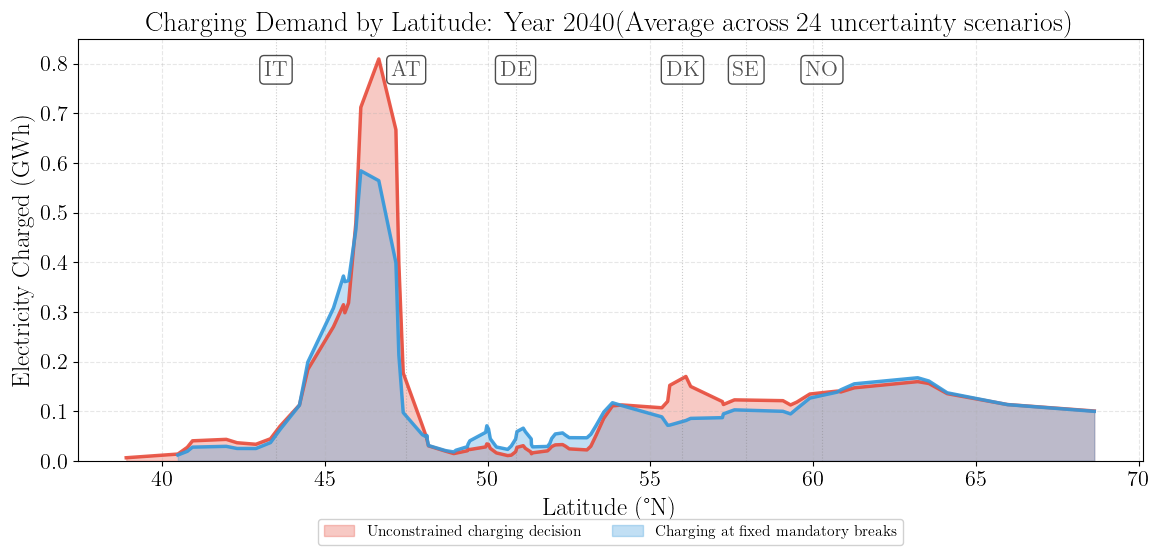

CHARGING BY LATITUDE SUMMARY (Year 2040)
Baseline: 8.97 GWh across 80 locations
Constrained: 8.39 GWh across 79 locations
Difference: -0.58 GWh (-6.5%)


In [33]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})

# Create overlaid horizontal latitude plot comparing baseline vs constrained
def plot_latitude_comparison_overlaid(baseline_data, constrained_data, year=2040):
    """
    Create overlaid area/line plot comparing charging by latitude.
    Horizontal orientation: latitude on x-axis, GWh on y-axis.
    """
    from scipy.ndimage import gaussian_filter1d
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Colors
    color_baseline = '#E74C3C'  # Red
    color_constrained = '#3498DB'  # Blue
    
    def prepare_data(data):
        if len(data) < 3:
            return None, None
        lats = np.array([x[0] for x in data])
        gwh = np.array([x[1] for x in data])
        sort_idx = np.argsort(lats)
        lat_sorted = lats[sort_idx]
        gwh_sorted = gwh[sort_idx]
        gwh_smoothed = gaussian_filter1d(gwh_sorted, sigma=1.5)
        return lat_sorted, gwh_smoothed
    
    # Prepare both datasets
    lat_base, gwh_base = prepare_data(baseline_data)
    lat_const, gwh_const = prepare_data(constrained_data)
    
    if lat_base is None or lat_const is None:
        ax.text(0.5, 0.5, 'Insufficient data', ha='center', va='center', transform=ax.transAxes)
        return
    
    # Plot baseline (area + line)
    ax.fill_between(lat_base, 0, gwh_base, color=color_baseline, alpha=0.3, label='Unconstrained charging decision')
    ax.plot(lat_base, gwh_base, color=color_baseline, linewidth=2.5, alpha=0.9)
    
    # Plot constrained (area + line)
    ax.fill_between(lat_const, 0, gwh_const, color=color_constrained, alpha=0.3, label='Charging at fixed mandatory breaks')
    ax.plot(lat_const, gwh_const, color=color_constrained, linewidth=2.5, alpha=0.9)
    
    # Labels and formatting
    ax.set_xlabel('Latitude (°N)', fontsize=18, fontweight='bold')
    ax.set_ylabel('Electricity Charged (GWh)', fontsize=18, fontweight='bold')
    ax.set_title(f'Charging Demand by Latitude: Year {year}(Average across 24 uncertainty scenarios)', 
                 fontsize=20, fontweight='bold')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=11, framealpha=0.9)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.tick_params(axis='both', labelsize=16)
    
    # Set y-axis to start at 0
    ax.set_ylim(bottom=0)
    
    # Add country reference lines
    try:
        country_centroids = pd.read_csv(os.path.join(BASE_DIR, 'country_centroids.csv'))
        corridor_countries = ['IT', 'AT', 'DE', 'DK', 'SE', 'NO', 'FI']
        country_data = country_centroids[country_centroids['CNTR_CODE'].isin(corridor_countries)]
        
        xlim = ax.get_xlim()
        ylim = ax.get_ylim()
        for _, row in country_data.iterrows():
            lat = row['centroid_lat']
            if xlim[0] <= lat <= xlim[1]:
                ax.axvline(lat, color='gray', linestyle=':', alpha=0.4, linewidth=0.8)
                ax.text(lat, ylim[1] * 0.95, row['CNTR_CODE'], ha='center', va='top',
                       fontsize=16, fontweight='bold', color='#555',
                       bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))
    except Exception as e:
        print(f"Could not add country labels: {e}")
    
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_DIR, 'figures', f'charging_by_latitude_comparison_{year}.pdf'), 
                dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(BASE_DIR, 'figures', f'charging_by_latitude_comparison_{year}.png'), 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print summary
    print("" + "="*70)
    print(f"CHARGING BY LATITUDE SUMMARY (Year {year})")
    print("="*70)
    total_baseline = sum(x[1] for x in baseline_data)
    total_constrained = sum(x[1] for x in constrained_data)
    diff = total_constrained - total_baseline
    pct = 100 * diff / total_baseline if total_baseline > 0 else 0
    print(f"Baseline: {total_baseline:.2f} GWh across {len(baseline_data)} locations")
    print(f"Constrained: {total_constrained:.2f} GWh across {len(constrained_data)} locations")
    print(f"Difference: {diff:+.2f} GWh ({pct:+.1f}%)")

# Run the overlaid visualization
if baseline_lat_data and constrained_lat_data:
    plot_latitude_comparison_overlaid(baseline_lat_data, constrained_lat_data, year=2040)
else:
    print("No latitude data available - run the previous cell first")


In [20]:
# Save summary to CSV
summary_df.to_csv(os.path.join(BASE_DIR, 'charging_constraint_comparison_summary.csv'), index=False)
print("Summary saved to: charging_constraint_comparison_summary.csv")

Summary saved to: charging_constraint_comparison_summary.csv


## 7. BEV Share by OD Pair Analysis

Analyze which OD pairs have BEV electrification and what share of traffic uses BEVs.
This helps identify which corridors are being electrified first.

In [21]:
# Analyze BEV share by OD pair for a single scenario - COMPARING WITH vs WITHOUT CONSTRAINT
# f_dict key structure: (year, (product_id, odpair_id, path_id), (mode_id, techvehicle_id), generation)

def analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=BASELINE_DIR):
    """
    Analyze BEV share by OD pair for a specific scenario and year.
    
    Returns DataFrame with:
    - OD pair info (origin, destination, path length)
    - Total flow (all technologies)
    - BEV flow
    - BEV share (%)
    """
    
    # Load input data for OD pair and path info
    input_path = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", scenario)
    
    # Load Odpair.yaml
    with open(os.path.join(input_path, "Odpair.yaml"), 'r') as f:
        odpairs = yaml.safe_load(f)
    
    # Load Path.yaml
    with open(os.path.join(input_path, "Path.yaml"), 'r') as f:
        paths = yaml.safe_load(f)
    
    # Load GeographicElement.yaml for node names
    with open(os.path.join(input_path, "GeographicElement.yaml"), 'r') as f:
        geo_elements = yaml.safe_load(f)
    
    # Build lookups
    odpair_lookup = {od['id']: od for od in odpairs}
    path_lookup = {p['id']: p for p in paths}
    geo_lookup = {g['id']: g for g in geo_elements}
    
    print(f"Loaded {len(odpair_lookup)} OD pairs, {len(path_lookup)} paths, {len(geo_lookup)} geo elements")
    
    # Load f_dict results
    scenario_folder = os.path.join(results_dir, scenario)
    f_file = get_latest_file(scenario_folder, "f_dict.yaml")
    
    if not f_file:
        print(f"ERROR: No f_dict found for {scenario} in {results_dir}")
        return None
    
    print(f"Loading f_dict from: {os.path.basename(f_file)}")
    f_dict = load_yaml_safe(f_file)
    
    if not f_dict:
        print("ERROR: Could not load f_dict")
        return None
    
    # Aggregate flows by OD pair and technology for target year
    flows_by_od = defaultdict(lambda: defaultdict(float))
    
    for key_str, flow_value in f_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            flow = float(flow_value) if isinstance(flow_value, str) else flow_value
            
            if flow <= 0:
                continue
            
            year = key[0]
            if year != target_year:
                continue
            
            if len(key) >= 4:
                route_tuple = key[1]
                tech_tuple = key[2]
                
                if isinstance(route_tuple, tuple) and len(route_tuple) >= 2:
                    odpair_id = route_tuple[1]
                else:
                    continue
                
                if isinstance(tech_tuple, tuple) and len(tech_tuple) >= 2:
                    tech_id = tech_tuple[1]
                else:
                    continue
                
                flows_by_od[odpair_id][tech_id] += flow
                
        except Exception as e:
            continue
    
    print(f"Found flows for {len(flows_by_od)} OD pairs in year {target_year}")
    
    # Build results DataFrame
    results = []
    
    for odpair_id, tech_flows in flows_by_od.items():
        if odpair_id not in odpair_lookup:
            continue
        
        od = odpair_lookup[odpair_id]
        path_id = od.get('path_id')
        
        path_length = path_lookup.get(path_id, {}).get('length', 0)
        
        origin_id = od.get('from')
        dest_id = od.get('to')
        
        origin_name = geo_lookup.get(origin_id, {}).get('name', f'Node_{origin_id}')
        dest_name = geo_lookup.get(dest_id, {}).get('name', f'Node_{dest_id}')
        origin_country = geo_lookup.get(origin_id, {}).get('country', '??')
        dest_country = geo_lookup.get(dest_id, {}).get('country', '??')
        
        total_flow = sum(tech_flows.values())
        bev_flow = tech_flows.get(1, 0) + tech_flows.get('1', 0)
        icev_flow = tech_flows.get(0, 0) + tech_flows.get('0', 0)
        bev_share = 100 * bev_flow / total_flow if total_flow > 0 else 0
        
        results.append({
            'odpair_id': odpair_id,
            'origin_id': origin_id,
            'dest_id': dest_id,
            'origin_name': origin_name,
            'dest_name': dest_name,
            'origin_country': origin_country,
            'dest_country': dest_country,
            'path_id': path_id,
            'path_length_km': path_length,
            'total_flow': total_flow,
            'bev_flow': bev_flow,
            'icev_flow': icev_flow,
            'bev_share_pct': bev_share
        })
    
    df = pd.DataFrame(results)
    df = df.sort_values('bev_share_pct', ascending=False)
    
    return df

# ============================================================================
# RUN COMPARISON: BASELINE vs CONSTRAINED for scenario_000, year 2032
# ============================================================================
print("="*80)
print("BEV SHARE BY OD PAIR: COMPARING WITH vs WITHOUT CONSTRAINT")
print("Scenario: scenario_000 (Go RES, markup=0.15, tech_cost=0.7)")
print("Year: 2032")
print("="*80)

# Analyze BASELINE (without constraint)
print("\n--- BASELINE (without charging-at-breaks constraint) ---")
od_baseline_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=BASELINE_DIR)

# Analyze CONSTRAINED (with constraint)
print("\n--- CONSTRAINED (with charging-at-breaks constraint) ---")
od_constrained_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=CONSTRAINED_DIR)

# Merge results for comparison
if od_baseline_df is not None and od_constrained_df is not None:
    # Merge on odpair_id
    comparison_df = od_baseline_df[['odpair_id', 'origin_country', 'dest_country', 'path_length_km', 
                                     'total_flow', 'bev_share_pct']].copy()
    comparison_df = comparison_df.rename(columns={
        'total_flow': 'baseline_total_flow',
        'bev_share_pct': 'baseline_bev_share'
    })
    
    constrained_subset = od_constrained_df[['odpair_id', 'total_flow', 'bev_share_pct']].copy()
    constrained_subset = constrained_subset.rename(columns={
        'total_flow': 'constrained_total_flow',
        'bev_share_pct': 'constrained_bev_share'
    })
    
    comparison_df = comparison_df.merge(constrained_subset, on='odpair_id', how='outer')
    comparison_df = comparison_df.fillna(0)
    
    # Calculate difference
    comparison_df['bev_share_diff'] = comparison_df['constrained_bev_share'] - comparison_df['baseline_bev_share']
    
    print(f"\n{'='*80}")
    print("COMPARISON SUMMARY")
    print(f"{'='*80}")
    print(f"Total OD pairs analyzed: {len(comparison_df)}")
    print(f"\nBEV Share Statistics:")
    print(f"  Baseline mean:    {comparison_df['baseline_bev_share'].mean():.1f}%")
    print(f"  Constrained mean: {comparison_df['constrained_bev_share'].mean():.1f}%")
    print(f"  Mean difference:  {comparison_df['bev_share_diff'].mean():+.2f} pp")
    
    # Count OD pairs with different electrification
    same_electrification = len(comparison_df[abs(comparison_df['bev_share_diff']) < 1])
    lower_electrification = len(comparison_df[comparison_df['bev_share_diff'] < -1])
    higher_electrification = len(comparison_df[comparison_df['bev_share_diff'] > 1])
    
    print(f"\nOD Pairs by Change in BEV Share:")
    print(f"  Same (±1pp):           {same_electrification} ({100*same_electrification/len(comparison_df):.1f}%)")
    print(f"  Lower with constraint: {lower_electrification} ({100*lower_electrification/len(comparison_df):.1f}%)")
    print(f"  Higher with constraint: {higher_electrification} ({100*higher_electrification/len(comparison_df):.1f}%)")

BEV SHARE BY OD PAIR: COMPARING WITH vs WITHOUT CONSTRAINT
Scenario: scenario_000 (Go RES, markup=0.15, tech_cost=0.7)
Year: 2032

--- BASELINE (without charging-at-breaks constraint) ---
Loaded 2043 OD pairs, 2043 paths, 81 geo elements
Loading f_dict from: scenario_000_2025-12-16_10-22-42_f_dict.yaml
Found flows for 2043 OD pairs in year 2032

--- CONSTRAINED (with charging-at-breaks constraint) ---
Loaded 2043 OD pairs, 2043 paths, 81 geo elements
Loading f_dict from: scenario_000_with_breaks_2025-12-16_15-36-35_f_dict.yaml
Found flows for 2043 OD pairs in year 2032

COMPARISON SUMMARY
Total OD pairs analyzed: 2043

BEV Share Statistics:
  Baseline mean:    13.7%
  Constrained mean: 11.2%
  Mean difference:  -2.46 pp

OD Pairs by Change in BEV Share:
  Same (±1pp):           1708 (83.6%)
  Lower with constraint: 163 (8.0%)
  Higher with constraint: 172 (8.4%)


ELECTRIFICATION OVERLAP ANALYSIS (Threshold: ≥50% BEV)
Scenario: scenario_000, Year: 2032

Category                    N OD Pairs   % of Pairs   Baseline BEV tkm  Constrained BEV tkm
------------------------------------------------------------------------------------------
Both Electrified                   198         9.7%              0.05B                0.06B
Only Baseline                      145         7.1%              0.03B                0.00B
Only Constrained                    83         4.1%              0.00B                0.03B
Neither Electrified               1617        79.1%              0.00B                0.00B
------------------------------------------------------------------------------------------
TOTAL                             2043       100.0%              0.09B                0.09B

KEY INSIGHTS

1. ELECTRIFICATION OVERLAP:
   - Baseline electrified OD pairs: 343
   - Constrained electrified OD pairs: 281
   - Overlap (both electrified): 198
   - Jaccard

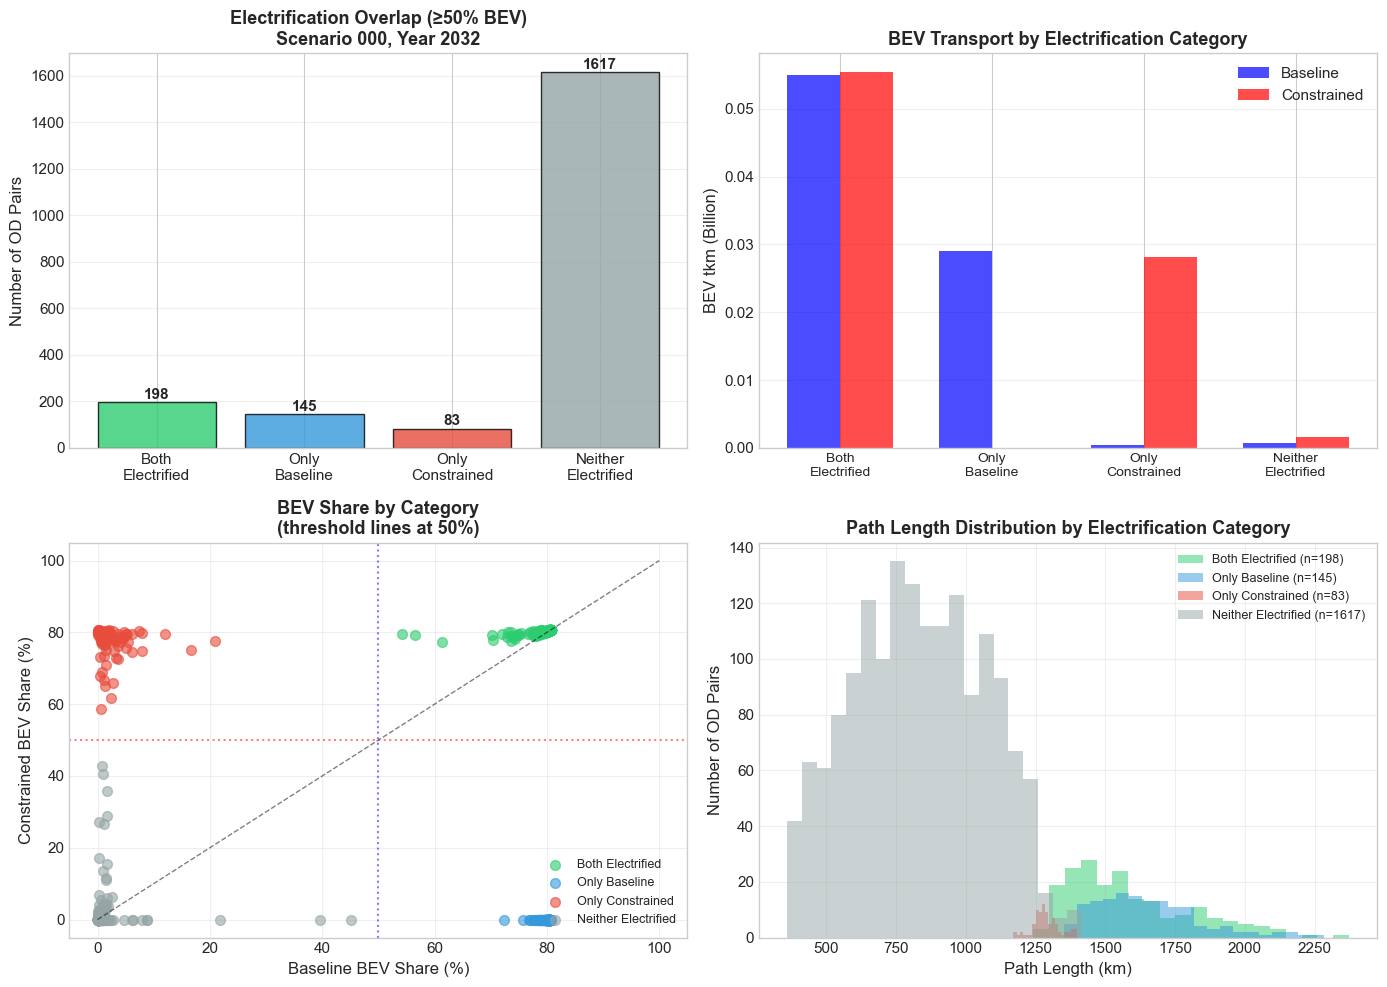


OD PAIRS ELECTRIFIED ONLY WITH CONSTRAINT (not in baseline)

Origin->Dest    Length(km)   Base BEV%    Constr BEV%    Constr BEV tkm 
----------------------------------------------------------------------
IT->DE          1266         0.1          80.5           2.2            M
IT->DE          1255         0.1          79.7           2.1            M
DE->IT          1273         0.1          80.3           1.9            M
IT->DE          1282         0.2          80.4           1.8            M
DE->IT          1289         0.3          80.4           1.4            M
IT->DE          1273         0.2          80.4           1.3            M
IT->DE          1261         0.2          79.7           1.0            M
DE->IT          1280         0.5          79.9           0.6            M
DE->IT          1240         0.4          78.9           0.6            M
IT->DE          1263         0.4          79.9           0.5            M

OD PAIRS ELECTRIFIED ONLY IN BASELINE (lost with cons

In [22]:
# Analyze OVERLAP of electrified OD pairs between baseline and constrained
# Focus on: which OD pairs are electrified in both, only in one, or neither
# Weight by tonnes transported (tkm)

if comparison_df is not None and len(comparison_df) > 0:
    
    # Define electrification threshold (e.g., >50% BEV = "electrified")
    ELECTRIFICATION_THRESHOLD = 50  # percent
    
    # Categorize OD pairs
    comparison_df['baseline_electrified'] = comparison_df['baseline_bev_share'] >= ELECTRIFICATION_THRESHOLD
    comparison_df['constrained_electrified'] = comparison_df['constrained_bev_share'] >= ELECTRIFICATION_THRESHOLD
    
    # Create overlap categories
    def categorize_overlap(row):
        if row['baseline_electrified'] and row['constrained_electrified']:
            return 'Both Electrified'
        elif row['baseline_electrified'] and not row['constrained_electrified']:
            return 'Only Baseline'
        elif not row['baseline_electrified'] and row['constrained_electrified']:
            return 'Only Constrained'
        else:
            return 'Neither Electrified'
    
    comparison_df['electrification_category'] = comparison_df.apply(categorize_overlap, axis=1)
    
    # Calculate tkm for each OD pair (using path length and flow)
    # tkm = flow * path_length * load_capacity (assume load_capacity = 25 tonnes)
    LOAD_CAPACITY = 25  # tonnes
    comparison_df['baseline_tkm'] = comparison_df['baseline_total_flow'] * comparison_df['path_length_km'] * LOAD_CAPACITY
    comparison_df['constrained_tkm'] = comparison_df['constrained_total_flow'] * comparison_df['path_length_km'] * LOAD_CAPACITY
    
    # Also calculate BEV tkm specifically
    # We need to go back to the original data for this
    # For now, estimate: BEV_tkm = total_tkm * (bev_share/100)
    comparison_df['baseline_bev_tkm'] = comparison_df['baseline_tkm'] * (comparison_df['baseline_bev_share'] / 100)
    comparison_df['constrained_bev_tkm'] = comparison_df['constrained_tkm'] * (comparison_df['constrained_bev_share'] / 100)
    
    # =========================================================================
    # SUMMARY BY CATEGORY
    # =========================================================================
    print("="*80)
    print(f"ELECTRIFICATION OVERLAP ANALYSIS (Threshold: ≥{ELECTRIFICATION_THRESHOLD}% BEV)")
    print("Scenario: scenario_000, Year: 2032")
    print("="*80)
    
    category_summary = comparison_df.groupby('electrification_category').agg({
        'odpair_id': 'count',
        'baseline_tkm': 'sum',
        'constrained_tkm': 'sum',
        'baseline_bev_tkm': 'sum',
        'constrained_bev_tkm': 'sum'
    }).rename(columns={'odpair_id': 'n_od_pairs'})
    
    # Ensure all categories exist
    for cat in ['Both Electrified', 'Only Baseline', 'Only Constrained', 'Neither Electrified']:
        if cat not in category_summary.index:
            category_summary.loc[cat] = 0
    
    category_summary = category_summary.loc[['Both Electrified', 'Only Baseline', 'Only Constrained', 'Neither Electrified']]
    
    total_od_pairs = category_summary['n_od_pairs'].sum()
    total_baseline_tkm = comparison_df['baseline_tkm'].sum()
    total_baseline_bev_tkm = comparison_df['baseline_bev_tkm'].sum()
    total_constrained_bev_tkm = comparison_df['constrained_bev_tkm'].sum()
    
    print(f"\n{'Category':<25} {'N OD Pairs':>12} {'% of Pairs':>12} {'Baseline BEV tkm':>18} {'Constrained BEV tkm':>20}")
    print("-"*90)
    for cat in category_summary.index:
        n = category_summary.loc[cat, 'n_od_pairs']
        pct = 100 * n / total_od_pairs if total_od_pairs > 0 else 0
        b_tkm = category_summary.loc[cat, 'baseline_bev_tkm'] / 1e9  # Convert to billion tkm
        c_tkm = category_summary.loc[cat, 'constrained_bev_tkm'] / 1e9
        print(f"{cat:<25} {n:>12.0f} {pct:>11.1f}% {b_tkm:>17.2f}B {c_tkm:>19.2f}B")
    
    print("-"*90)
    print(f"{'TOTAL':<25} {total_od_pairs:>12.0f} {'100.0':>11}% {total_baseline_bev_tkm/1e9:>17.2f}B {total_constrained_bev_tkm/1e9:>19.2f}B")
    
    # =========================================================================
    # KEY INSIGHTS
    # =========================================================================
    both_electrified = comparison_df[comparison_df['electrification_category'] == 'Both Electrified']
    only_baseline = comparison_df[comparison_df['electrification_category'] == 'Only Baseline']
    only_constrained = comparison_df[comparison_df['electrification_category'] == 'Only Constrained']
    neither = comparison_df[comparison_df['electrification_category'] == 'Neither Electrified']
    
    print(f"\n{'='*80}")
    print("KEY INSIGHTS")
    print(f"{'='*80}")
    
    # Calculate overlap coefficient
    n_baseline_electrified = len(comparison_df[comparison_df['baseline_electrified']])
    n_constrained_electrified = len(comparison_df[comparison_df['constrained_electrified']])
    n_both = len(both_electrified)
    
    if n_baseline_electrified > 0 and n_constrained_electrified > 0:
        jaccard = n_both / (n_baseline_electrified + n_constrained_electrified - n_both) if (n_baseline_electrified + n_constrained_electrified - n_both) > 0 else 0
        overlap_baseline = 100 * n_both / n_baseline_electrified
        overlap_constrained = 100 * n_both / n_constrained_electrified
    else:
        jaccard = 0
        overlap_baseline = 0
        overlap_constrained = 0
    
    print(f"\n1. ELECTRIFICATION OVERLAP:")
    print(f"   - Baseline electrified OD pairs: {n_baseline_electrified}")
    print(f"   - Constrained electrified OD pairs: {n_constrained_electrified}")
    print(f"   - Overlap (both electrified): {n_both}")
    print(f"   - Jaccard similarity: {jaccard:.2%}")
    print(f"   - {overlap_baseline:.1f}% of baseline's electrified pairs are also electrified with constraint")
    print(f"   - {overlap_constrained:.1f}% of constrained's electrified pairs are also electrified in baseline")
    
    print(f"\n2. DIFFERENT ELECTRIFICATION PATTERNS:")
    if len(only_constrained) > 0:
        print(f"   - {len(only_constrained)} OD pairs are electrified ONLY with constraint (not in baseline)")
        print(f"     These represent {only_constrained['constrained_bev_tkm'].sum()/1e9:.2f} billion BEV tkm")
    else:
        print(f"   - No OD pairs are electrified only with constraint")
    
    if len(only_baseline) > 0:
        print(f"   - {len(only_baseline)} OD pairs are electrified ONLY in baseline (lost with constraint)")
        print(f"     These represented {only_baseline['baseline_bev_tkm'].sum()/1e9:.2f} billion BEV tkm in baseline")
    else:
        print(f"   - No OD pairs lost electrification with constraint")
    
    # =========================================================================
    # VISUALIZATION
    # =========================================================================
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Venn-style bar chart of overlap
    ax1 = axes[0, 0]
    categories = ['Both\nElectrified', 'Only\nBaseline', 'Only\nConstrained', 'Neither\nElectrified']
    counts = [len(both_electrified), len(only_baseline), len(only_constrained), len(neither)]
    colors = ['#2ECC71', '#3498DB', '#E74C3C', '#95A5A6']
    bars = ax1.bar(categories, counts, color=colors, edgecolor='black', alpha=0.8)
    ax1.set_ylabel('Number of OD Pairs', fontsize=12)
    ax1.set_title(f'Electrification Overlap (≥{ELECTRIFICATION_THRESHOLD}% BEV)\nScenario 000, Year 2032', 
                  fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add count labels on bars
    for bar, count in zip(bars, counts):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
                f'{count}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Plot 2: BEV tkm by category (stacked bar)
    ax2 = axes[0, 1]
    x = np.arange(4)
    width = 0.35
    baseline_tkm = [both_electrified['baseline_bev_tkm'].sum()/1e9, 
                    only_baseline['baseline_bev_tkm'].sum()/1e9,
                    only_constrained['baseline_bev_tkm'].sum()/1e9,
                    neither['baseline_bev_tkm'].sum()/1e9]
    constrained_tkm = [both_electrified['constrained_bev_tkm'].sum()/1e9,
                       only_baseline['constrained_bev_tkm'].sum()/1e9,
                       only_constrained['constrained_bev_tkm'].sum()/1e9,
                       neither['constrained_bev_tkm'].sum()/1e9]
    
    ax2.bar(x - width/2, baseline_tkm, width, label='Baseline', color='blue', alpha=0.7)
    ax2.bar(x + width/2, constrained_tkm, width, label='Constrained', color='red', alpha=0.7)
    ax2.set_xticks(x)
    ax2.set_xticklabels(categories, fontsize=10)
    ax2.set_ylabel('BEV tkm (Billion)', fontsize=12)
    ax2.set_title('BEV Transport by Electrification Category', fontsize=13, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Plot 3: Scatter - baseline vs constrained with category colors
    ax3 = axes[1, 0]
    color_map = {'Both Electrified': '#2ECC71', 'Only Baseline': '#3498DB', 
                 'Only Constrained': '#E74C3C', 'Neither Electrified': '#95A5A6'}
    for cat in color_map:
        subset = comparison_df[comparison_df['electrification_category'] == cat]
        ax3.scatter(subset['baseline_bev_share'], subset['constrained_bev_share'],
                   c=color_map[cat], label=cat, alpha=0.6, s=50)
    ax3.plot([0, 100], [0, 100], 'k--', linewidth=1, alpha=0.5)
    ax3.axhline(ELECTRIFICATION_THRESHOLD, color='red', linestyle=':', alpha=0.5)
    ax3.axvline(ELECTRIFICATION_THRESHOLD, color='blue', linestyle=':', alpha=0.5)
    ax3.set_xlabel('Baseline BEV Share (%)', fontsize=12)
    ax3.set_ylabel('Constrained BEV Share (%)', fontsize=12)
    ax3.set_title(f'BEV Share by Category\n(threshold lines at {ELECTRIFICATION_THRESHOLD}%)', 
                  fontsize=13, fontweight='bold')
    ax3.legend(loc='lower right', fontsize=9)
    ax3.grid(True, alpha=0.3)
    ax3.set_xlim(-5, 105)
    ax3.set_ylim(-5, 105)
    
    # Plot 4: Path length distribution by category
    ax4 = axes[1, 1]
    for cat, color in color_map.items():
        subset = comparison_df[comparison_df['electrification_category'] == cat]
        if len(subset) > 0:
            ax4.hist(subset['path_length_km'], bins=20, alpha=0.5, color=color, label=f'{cat} (n={len(subset)})')
    ax4.set_xlabel('Path Length (km)', fontsize=12)
    ax4.set_ylabel('Number of OD Pairs', fontsize=12)
    ax4.set_title('Path Length Distribution by Electrification Category', fontsize=13, fontweight='bold')
    ax4.legend(fontsize=9)
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(BASE_DIR, 'figures', 'electrification_overlap_analysis_2032.pdf'), dpi=300, bbox_inches='tight')
    plt.show()
    
    # =========================================================================
    # DETAILED LIST: OD PAIRS ONLY ELECTRIFIED WITH CONSTRAINT
    # =========================================================================
    if len(only_constrained) > 0:
        print(f"\n{'='*80}")
        print("OD PAIRS ELECTRIFIED ONLY WITH CONSTRAINT (not in baseline)")
        print(f"{'='*80}")
        only_constrained_sorted = only_constrained.sort_values('constrained_bev_tkm', ascending=False)
        print(f"\n{'Origin->Dest':<15} {'Length(km)':<12} {'Base BEV%':<12} {'Constr BEV%':<14} {'Constr BEV tkm':<15}")
        print("-"*70)
        for _, row in only_constrained_sorted.head(10).iterrows():
            print(f"{row['origin_country']+'->'+ row['dest_country']:<15} {row['path_length_km']:<12.0f} "
                  f"{row['baseline_bev_share']:<12.1f} {row['constrained_bev_share']:<14.1f} "
                  f"{row['constrained_bev_tkm']/1e6:<15.1f}M")
    
    if len(only_baseline) > 0:
        print(f"\n{'='*80}")
        print("OD PAIRS ELECTRIFIED ONLY IN BASELINE (lost with constraint)")
        print(f"{'='*80}")
        only_baseline_sorted = only_baseline.sort_values('baseline_bev_tkm', ascending=False)
        print(f"\n{'Origin->Dest':<15} {'Length(km)':<12} {'Base BEV%':<12} {'Constr BEV%':<14} {'Base BEV tkm':<15}")
        print("-"*70)
        for _, row in only_baseline_sorted.head(10).iterrows():
            print(f"{row['origin_country']+'->'+ row['dest_country']:<15} {row['path_length_km']:<12.0f} "
                  f"{row['baseline_bev_share']:<12.1f} {row['constrained_bev_share']:<14.1f} "
                  f"{row['baseline_bev_tkm']/1e6:<15.1f}M")

In [23]:
# First check that we have the necessary data files for scenario_000
import os

BASE_DIR = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM"
BASELINE_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis")
CONSTRAINED_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis_with_breaks_full")

# Check for scenario_000 results
baseline_scenario = os.path.join(BASELINE_DIR, "scenario_000")
constrained_scenario = os.path.join(CONSTRAINED_DIR, "scenario_000")

print(f"Baseline results exist: {os.path.isdir(baseline_scenario)}")
print(f"Constrained results exist: {os.path.isdir(constrained_scenario)}")

if os.path.isdir(baseline_scenario):
    print(f"\nBaseline files: {os.listdir(baseline_scenario)[:5]}")
if os.path.isdir(constrained_scenario):
    print(f"\nConstrained files: {os.listdir(constrained_scenario)[:5]}")

Baseline results exist: True
Constrained results exist: True

Baseline files: ['scenario_000_2025-12-04_09-39-33_f_dict.yaml', 'scenario_000_2025-12-04_09-39-33_h_dict.yaml', 'scenario_000_2025-12-04_09-39-33_h_exist_dict.yaml', 'scenario_000_2025-12-04_09-39-33_h_minus_dict.yaml', 'scenario_000_2025-12-04_09-39-33_h_plus_dict.yaml']

Constrained files: ['scenario_000_with_breaks_2025-12-15_09-29-44_constraints_applied.txt', 'scenario_000_with_breaks_2025-12-15_09-29-44_extra_break_time_dict.yaml', 'scenario_000_with_breaks_2025-12-15_09-29-44_f_dict.yaml', 'scenario_000_with_breaks_2025-12-15_09-29-44_h_dict.yaml', 'scenario_000_with_breaks_2025-12-15_09-29-44_h_exist_dict.yaml']


In [24]:
import yaml
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

BASE_DIR = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM"
BASELINE_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis")
CONSTRAINED_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis_with_breaks_full")
INPUT_DIR = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "scenario_000")

# Load Path.yaml for path lengths
with open(os.path.join(INPUT_DIR, "Path.yaml"), 'r') as f:
    path_data = yaml.safe_load(f)

# Create path_id to length mapping
path_lengths = {}
for path in path_data:
    path_lengths[path['id']] = path['length']

# Load Odpair.yaml to get OD pair info
with open(os.path.join(INPUT_DIR, "Odpair.yaml"), 'r') as f:
    odpair_data = yaml.safe_load(f)

# Create odpair_id to path_id mapping and OD info
odpair_to_path = {}
odpair_info = {}
for od in odpair_data:
    odpair_to_path[od['id']] = od['path_id']
    odpair_info[od['id']] = {'from': od['from'], 'to': od['to'], 'path_id': od['path_id']}

# Load GeographicElement.yaml for country info
with open(os.path.join(INPUT_DIR, "GeographicElement.yaml"), 'r') as f:
    geo_data = yaml.safe_load(f)

# Create geo_id to country mapping
geo_to_country = {}
for geo in geo_data:
    geo_to_country[geo['id']] = geo.get('country', 'Unknown')

print(f"Loaded {len(path_lengths)} paths")
print(f"Loaded {len(odpair_info)} OD pairs")
print(f"Loaded {len(geo_to_country)} geographic elements")

Loaded 2043 paths
Loaded 2043 OD pairs
Loaded 81 geographic elements


In [25]:
# Check the structure of Path.yaml
print("Path.yaml keys:", path_data[0].keys())

Path.yaml keys: dict_keys(['id', 'name', 'origin', 'destination', 'length', 'sequence', 'distance_from_previous', 'cumulative_distance'])


In [26]:
# The key is 'length' not 'length_km', and 'id' instead of 'path_id'
import yaml
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

BASE_DIR = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM"
BASELINE_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis")
CONSTRAINED_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis_with_breaks_full")
INPUT_DIR = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "scenario_000")

# Load Path.yaml for path lengths
with open(os.path.join(INPUT_DIR, "Path.yaml"), 'r') as f:
    path_data = yaml.safe_load(f)

# Create path_id to length mapping
path_lengths = {}
for path in path_data:
    path_lengths[path['id']] = path['length']  # length is in km

# Load Odpair.yaml to get OD pair info
with open(os.path.join(INPUT_DIR, "Odpair.yaml"), 'r') as f:
    odpair_data = yaml.safe_load(f)

# Create odpair_id to path_id mapping and OD info
odpair_to_path = {}
odpair_info = {}
for od in odpair_data:
    odpair_to_path[od['id']] = od['path']
    odpair_info[od['id']] = {'from': od['from'], 'to': od['to'], 'path_id': od['path']}

# Load GeographicElement.yaml for country info
with open(os.path.join(INPUT_DIR, "GeographicElement.yaml"), 'r') as f:
    geo_data = yaml.safe_load(f)

# Create geo_id to country mapping
geo_to_country = {}
for geo in geo_data:
    geo_to_country[geo['id']] = geo.get('country', 'Unknown')

print(f"Loaded {len(path_lengths)} paths")
print(f"Loaded {len(odpair_info)} OD pairs")
print(f"Loaded {len(geo_to_country)} geographic elements")
print(f"\nExample path lengths: path 0 = {path_lengths.get(0, 'N/A')} km, path 1 = {path_lengths.get(1, 'N/A')} km")

KeyError: 'path'

In [ ]:
# Check Odpair.yaml structure
print("Odpair.yaml keys:", odpair_data[0].keys())

In [ ]:
# Now with correct keys
import yaml
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

BASE_DIR = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM"
BASELINE_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis")
CONSTRAINED_DIR = os.path.join(BASE_DIR, "results", "uncertainty_analysis_with_breaks_full")
INPUT_DIR = os.path.join(BASE_DIR, "input_data", "uncertainty_scenarios", "scenario_000")

# Load Path.yaml for path lengths
with open(os.path.join(INPUT_DIR, "Path.yaml"), 'r') as f:
    path_data = yaml.safe_load(f)

# Create path_id to length mapping
path_lengths = {}
for path in path_data:
    path_lengths[path['id']] = path['length']  # length is in km

# Load Odpair.yaml to get OD pair info
with open(os.path.join(INPUT_DIR, "Odpair.yaml"), 'r') as f:
    odpair_data = yaml.safe_load(f)

# Create odpair_id to path_id mapping and OD info
odpair_to_path = {}
odpair_info = {}
for od in odpair_data:
    odpair_to_path[od['id']] = od['path_id']
    odpair_info[od['id']] = {'from': od['from'], 'to': od['to'], 'path_id': od['path_id']}

# Load GeographicElement.yaml for country info
with open(os.path.join(INPUT_DIR, "GeographicElement.yaml"), 'r') as f:
    geo_data = yaml.safe_load(f)

# Create geo_id to country mapping
geo_to_country = {}
for geo in geo_data:
    geo_to_country[geo['id']] = geo.get('country', 'Unknown')

print(f"Loaded {len(path_lengths)} paths")
print(f"Loaded {len(odpair_info)} OD pairs")
print(f"Loaded {len(geo_to_country)} geographic elements")
print(f"\nExample path lengths: path 0 = {path_lengths.get(0, 'N/A')} km, path 1 = {path_lengths.get(1, 'N/A')} km")

In [ ]:
# Define function to analyze BEV share by OD pair
def analyze_bev_share_by_od_pair(scenario, target_year, results_dir):
    """
    Analyze BEV share by OD pair for a given scenario and year.
    Returns a DataFrame with BEV share per OD pair.
    """
    # Find the f_dict file for this scenario
    scenario_dir = os.path.join(results_dir, scenario)
    f_files = [f for f in os.listdir(scenario_dir) if 'f_dict.yaml' in f]
    
    if not f_files:
        print(f"No f_dict file found for {scenario}")
        return None
    
    f_file = f_files[0]
    print(f"Loading: {f_file}")
    
    with open(os.path.join(scenario_dir, f_file), 'r') as f:
        f_dict = yaml.safe_load(f)
    
    # Parse f_dict and aggregate by OD pair
    # Key structure: (year, (product_id, odpair_id, path_id), (mode_id, techvehicle_id), generation)
    od_flows = defaultdict(lambda: {'bev': 0, 'other': 0})
    
    for key, value in f_dict.items():
        val = float(value) if isinstance(value, str) else value
        if val < 1e-6:
            continue
            
        # Parse key
        if isinstance(key, str):
            parts = key.strip("()").split(",")
            year = int(parts[0].strip())
            odpair_id = int(parts[2].strip())
            techvehicle_id = int(parts[5].strip())
        else:
            continue
        
        if year != target_year:
            continue
        
        # BEV techvehicle_id = 1 (road-bev)
        if techvehicle_id == 1:
            od_flows[odpair_id]['bev'] += val
        else:
            od_flows[odpair_id]['other'] += val
    
    # Convert to DataFrame
    rows = []
    for odpair_id, flows in od_flows.items():
        total_flow = flows['bev'] + flows['other']
        bev_share = 100 * flows['bev'] / total_flow if total_flow > 0 else 0
        
        # Get OD pair info
        od_info = odpair_info.get(odpair_id, {})
        path_id = od_info.get('path_id', odpair_id)
        path_length = path_lengths.get(path_id, 0)
        
        origin_geo = od_info.get('from', 0)
        dest_geo = od_info.get('to', 0)
        origin_country = geo_to_country.get(origin_geo, 'Unknown')
        dest_country = geo_to_country.get(dest_geo, 'Unknown')
        
        rows.append({
            'odpair_id': odpair_id,
            'origin_geo': origin_geo,
            'dest_geo': dest_geo,
            'origin_country': origin_country,
            'dest_country': dest_country,
            'path_id': path_id,
            'path_length_km': path_length,
            'bev_flow': flows['bev'],
            'other_flow': flows['other'],
            'total_flow': total_flow,
            'bev_share': bev_share
        })
    
    df = pd.DataFrame(rows)
    print(f"Found {len(df)} OD pairs with flows in year {target_year}")
    print(f"Mean BEV share: {df['bev_share'].mean():.1f}%")
    print(f"OD pairs with >50% BEV: {(df['bev_share'] >= 50).sum()}")
    
    return df

# Run for both baseline and constrained
print("="*80)
print("--- BASELINE (without charging-at-breaks constraint) ---")
print("="*80)
od_baseline_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=BASELINE_DIR)

print("\n" + "="*80)
print("--- CONSTRAINED (with charging-at-breaks constraint) ---")
print("="*80)
od_constrained_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=CONSTRAINED_DIR)

In [ ]:
# Check the key format
scenario_dir = os.path.join(BASELINE_DIR, "scenario_000")
f_files = [f for f in os.listdir(scenario_dir) if 'f_dict.yaml' in f]
f_file = f_files[0]

with open(os.path.join(scenario_dir, f_file), 'r') as f:
    f_dict = yaml.safe_load(f)

# Show first few keys
for i, (key, val) in enumerate(f_dict.items()):
    print(f"Key: {key}")
    print(f"Type: {type(key)}")
    if i >= 2:
        break

In [ ]:
import re

def parse_f_dict_key(key_str):
    """
    Parse key format: (year, (product_id, odpair_id, path_id), (mode_id, techvehicle_id), generation)
    Example: '(2036, (0, 1232, 1232), (1, 0), 2032)'
    """
    # Use regex to extract numbers
    numbers = re.findall(r'-?\d+', key_str)
    if len(numbers) >= 7:
        year = int(numbers[0])
        product_id = int(numbers[1])
        odpair_id = int(numbers[2])
        path_id = int(numbers[3])
        mode_id = int(numbers[4])
        techvehicle_id = int(numbers[5])
        generation = int(numbers[6])
        return year, product_id, odpair_id, path_id, mode_id, techvehicle_id, generation
    return None

# Test
test_key = "(2036, (0, 1232, 1232), (1, 0), 2032)"
print(f"Parsed: {parse_f_dict_key(test_key)}")

In [ ]:
import re

def parse_f_dict_key(key_str):
    """
    Parse key format: (year, (product_id, odpair_id, path_id), (mode_id, techvehicle_id), generation)
    Example: '(2036, (0, 1232, 1232), (1, 0), 2032)'
    """
    # Use regex to extract numbers
    numbers = re.findall(r'-?\d+', key_str)
    if len(numbers) >= 7:
        year = int(numbers[0])
        product_id = int(numbers[1])
        odpair_id = int(numbers[2])
        path_id = int(numbers[3])
        mode_id = int(numbers[4])
        techvehicle_id = int(numbers[5])
        generation = int(numbers[6])
        return year, product_id, odpair_id, path_id, mode_id, techvehicle_id, generation
    return None

# Test
test_key = "(2036, (0, 1232, 1232), (1, 0), 2032)"
print(f"Parsed: {parse_f_dict_key(test_key)}")

In [ ]:
# Define function to analyze BEV share by OD pair with correct parsing
def analyze_bev_share_by_od_pair(scenario, target_year, results_dir):
    """
    Analyze BEV share by OD pair for a given scenario and year.
    Returns a DataFrame with BEV share per OD pair.
    """
    # Find the f_dict file for this scenario
    scenario_dir = os.path.join(results_dir, scenario)
    f_files = [f for f in os.listdir(scenario_dir) if 'f_dict.yaml' in f]
    
    if not f_files:
        print(f"No f_dict file found for {scenario}")
        return None
    
    f_file = f_files[0]
    print(f"Loading: {f_file}")
    
    with open(os.path.join(scenario_dir, f_file), 'r') as f:
        f_dict = yaml.safe_load(f)
    
    # Parse f_dict and aggregate by OD pair
    od_flows = defaultdict(lambda: {'bev': 0, 'other': 0})
    
    for key, value in f_dict.items():
        val = float(value) if isinstance(value, str) else value
        if val < 1e-6:
            continue
            
        # Parse key using regex
        parsed = parse_f_dict_key(key)
        if parsed is None:
            continue
            
        year, product_id, odpair_id, path_id, mode_id, techvehicle_id, generation = parsed
        
        if year != target_year:
            continue
        
        # BEV techvehicle_id = 1 (road-bev)
        if techvehicle_id == 1:
            od_flows[odpair_id]['bev'] += val
        else:
            od_flows[odpair_id]['other'] += val
    
    # Convert to DataFrame
    rows = []
    for odpair_id, flows in od_flows.items():
        total_flow = flows['bev'] + flows['other']
        bev_share = 100 * flows['bev'] / total_flow if total_flow > 0 else 0
        
        # Get OD pair info
        od_info = odpair_info.get(odpair_id, {})
        path_id = od_info.get('path_id', odpair_id)
        path_length = path_lengths.get(path_id, 0)
        
        origin_geo = od_info.get('from', 0)
        dest_geo = od_info.get('to', 0)
        origin_country = geo_to_country.get(origin_geo, 'Unknown')
        dest_country = geo_to_country.get(dest_geo, 'Unknown')
        
        rows.append({
            'odpair_id': odpair_id,
            'origin_geo': origin_geo,
            'dest_geo': dest_geo,
            'origin_country': origin_country,
            'dest_country': dest_country,
            'path_id': path_id,
            'path_length_km': path_length,
            'bev_flow': flows['bev'],
            'other_flow': flows['other'],
            'total_flow': total_flow,
            'bev_share': bev_share
        })
    
    df = pd.DataFrame(rows)
    print(f"Found {len(df)} OD pairs with flows in year {target_year}")
    print(f"Mean BEV share: {df['bev_share'].mean():.1f}%")
    print(f"OD pairs with >50% BEV: {(df['bev_share'] >= 50).sum()}")
    
    return df

# Run for both baseline and constrained
print("="*80)
print("--- BASELINE (without charging-at-breaks constraint) ---")
print("="*80)
od_baseline_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=BASELINE_DIR)

print("\n" + "="*80)
print("--- CONSTRAINED (with charging-at-breaks constraint) ---")
print("="*80)
od_constrained_df = analyze_bev_share_by_od_pair(scenario='scenario_000', target_year=2032, results_dir=CONSTRAINED_DIR)

In [ ]:
# Merge baseline and constrained results
comparison_df = od_baseline_df.merge(
    od_constrained_df[['odpair_id', 'bev_flow', 'other_flow', 'total_flow', 'bev_share']],
    on='odpair_id',
    suffixes=('_baseline', '_constrained'),
    how='outer'
)

# Rename columns for clarity
comparison_df = comparison_df.rename(columns={
    'bev_flow_baseline': 'baseline_bev_flow',
    'other_flow_baseline': 'baseline_other_flow',
    'total_flow_baseline': 'baseline_total_flow',
    'bev_share_baseline': 'baseline_bev_share',
    'bev_flow_constrained': 'constrained_bev_flow',
    'other_flow_constrained': 'constrained_other_flow',
    'total_flow_constrained': 'constrained_total_flow',
    'bev_share_constrained': 'constrained_bev_share',
    'bev_flow': 'baseline_bev_flow',
    'other_flow': 'baseline_other_flow',
    'total_flow': 'baseline_total_flow',
    'bev_share': 'baseline_bev_share'
})

# Fill NaNs with 0
comparison_df = comparison_df.fillna(0)

print(f"Merged comparison DataFrame: {len(comparison_df)} OD pairs")
print(comparison_df.head())

In [ ]:
# Analyze OVERLAP of electrified OD pairs between baseline and constrained
# Focus on: which OD pairs are electrified in both, only in one, or neither
# Weight by tonnes transported (tkm)

# Define electrification threshold (e.g., >50% BEV = "electrified")
ELECTRIFICATION_THRESHOLD = 50  # percent

# Categorize OD pairs
comparison_df['baseline_electrified'] = comparison_df['baseline_bev_share'] >= ELECTRIFICATION_THRESHOLD
comparison_df['constrained_electrified'] = comparison_df['constrained_bev_share'] >= ELECTRIFICATION_THRESHOLD

# Create overlap categories
def categorize_overlap(row):
    if row['baseline_electrified'] and row['constrained_electrified']:
        return 'Both Electrified'
    elif row['baseline_electrified'] and not row['constrained_electrified']:
        return 'Only Baseline'
    elif not row['baseline_electrified'] and row['constrained_electrified']:
        return 'Only Constrained'
    else:
        return 'Neither Electrified'

comparison_df['electrification_category'] = comparison_df.apply(categorize_overlap, axis=1)

# Calculate tkm for each OD pair (using path length and flow)
# tkm = flow * path_length * load_capacity (assume load_capacity = 25 tonnes)
LOAD_CAPACITY = 25  # tonnes
comparison_df['baseline_tkm'] = comparison_df['baseline_total_flow'] * comparison_df['path_length_km'] * LOAD_CAPACITY
comparison_df['constrained_tkm'] = comparison_df['constrained_total_flow'] * comparison_df['path_length_km'] * LOAD_CAPACITY

# Also calculate BEV tkm specifically
comparison_df['baseline_bev_tkm'] = comparison_df['baseline_tkm'] * (comparison_df['baseline_bev_share'] / 100)
comparison_df['constrained_bev_tkm'] = comparison_df['constrained_tkm'] * (comparison_df['constrained_bev_share'] / 100)

# =========================================================================
# SUMMARY BY CATEGORY
# =========================================================================
print("="*80)
print(f"ELECTRIFICATION OVERLAP ANALYSIS (Threshold: >={ELECTRIFICATION_THRESHOLD}% BEV)")
print("Scenario: scenario_000, Year: 2032")
print("="*80)

category_summary = comparison_df.groupby('electrification_category').agg({
    'odpair_id': 'count',
    'baseline_tkm': 'sum',
    'constrained_tkm': 'sum',
    'baseline_bev_tkm': 'sum',
    'constrained_bev_tkm': 'sum'
}).rename(columns={'odpair_id': 'n_od_pairs'})

# Ensure all categories exist
for cat in ['Both Electrified', 'Only Baseline', 'Only Constrained', 'Neither Electrified']:
    if cat not in category_summary.index:
        category_summary.loc[cat] = 0

category_summary = category_summary.loc[['Both Electrified', 'Only Baseline', 'Only Constrained', 'Neither Electrified']]

total_od_pairs = category_summary['n_od_pairs'].sum()
total_baseline_bev_tkm = comparison_df['baseline_bev_tkm'].sum()
total_constrained_bev_tkm = comparison_df['constrained_bev_tkm'].sum()

print(f"\n{'Category':<25} {'N OD Pairs':>12} {'% of Pairs':>12} {'Baseline BEV tkm':>18} {'Constrained BEV tkm':>20}")
print("-"*90)
for cat in category_summary.index:
    n = category_summary.loc[cat, 'n_od_pairs']
    pct = 100 * n / total_od_pairs if total_od_pairs > 0 else 0
    b_tkm = category_summary.loc[cat, 'baseline_bev_tkm'] / 1e9  # Convert to billion tkm
    c_tkm = category_summary.loc[cat, 'constrained_bev_tkm'] / 1e9
    print(f"{cat:<25} {n:>12.0f} {pct:>11.1f}% {b_tkm:>17.2f}B {c_tkm:>19.2f}B")

print("-"*90)
print(f"{'TOTAL':<25} {total_od_pairs:>12.0f} {'100.0':>11}% {total_baseline_bev_tkm/1e9:>17.2f}B {total_constrained_bev_tkm/1e9:>19.2f}B")

In [ ]:
# =========================================================================
# KEY INSIGHTS
# =========================================================================
both_electrified = comparison_df[comparison_df['electrification_category'] == 'Both Electrified']
only_baseline = comparison_df[comparison_df['electrification_category'] == 'Only Baseline']
only_constrained = comparison_df[comparison_df['electrification_category'] == 'Only Constrained']
neither = comparison_df[comparison_df['electrification_category'] == 'Neither Electrified']

print(f"\n{'='*80}")
print("KEY INSIGHTS")
print(f"{'='*80}")

# Calculate overlap coefficient
n_baseline_electrified = len(comparison_df[comparison_df['baseline_electrified']])
n_constrained_electrified = len(comparison_df[comparison_df['constrained_electrified']])
n_both = len(both_electrified)

if n_baseline_electrified > 0 and n_constrained_electrified > 0:
    jaccard = n_both / (n_baseline_electrified + n_constrained_electrified - n_both) if (n_baseline_electrified + n_constrained_electrified - n_both) > 0 else 0
    overlap_baseline = 100 * n_both / n_baseline_electrified
    overlap_constrained = 100 * n_both / n_constrained_electrified
else:
    jaccard = 0
    overlap_baseline = 0
    overlap_constrained = 0

print(f"\n1. ELECTRIFICATION OVERLAP:")
print(f"   - Baseline electrified OD pairs: {n_baseline_electrified}")
print(f"   - Constrained electrified OD pairs: {n_constrained_electrified}")
print(f"   - Overlap (both electrified): {n_both}")
print(f"   - Jaccard similarity: {jaccard:.2%}")
print(f"   - {overlap_baseline:.1f}% of baseline's electrified pairs are also electrified with constraint")
print(f"   - {overlap_constrained:.1f}% of constrained's electrified pairs are also electrified in baseline")

print(f"\n2. DIFFERENT ELECTRIFICATION PATTERNS:")
if len(only_constrained) > 0:
    print(f"   - {len(only_constrained)} OD pairs are electrified ONLY with constraint (not in baseline)")
    print(f"     These represent {only_constrained['constrained_bev_tkm'].sum()/1e9:.3f} billion BEV tkm")
else:
    print(f"   - No OD pairs are electrified only with constraint")

if len(only_baseline) > 0:
    print(f"   - {len(only_baseline)} OD pairs are electrified ONLY in baseline (lost with constraint)")
    print(f"     These represented {only_baseline['baseline_bev_tkm'].sum()/1e9:.3f} billion BEV tkm in baseline")
else:
    print(f"   - No OD pairs lost electrification with constraint")

print(f"\n3. IMPACT OF CHARGING-AT-BREAKS CONSTRAINT:")
print(f"   - Total BEV tkm (baseline): {total_baseline_bev_tkm/1e9:.3f} billion")
print(f"   - Total BEV tkm (constrained): {total_constrained_bev_tkm/1e9:.3f} billion")
print(f"   - Difference: {(total_constrained_bev_tkm - total_baseline_bev_tkm)/1e9:.3f} billion ({100*(total_constrained_bev_tkm - total_baseline_bev_tkm)/total_baseline_bev_tkm:.1f}%)")

In [ ]:
# =========================================================================
# VISUALIZATION
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Bar chart of overlap categories
ax1 = axes[0, 0]
categories = ['Both\nElectrified', 'Only\nBaseline', 'Only\nConstrained', 'Neither\nElectrified']
counts = [len(both_electrified), len(only_baseline), len(only_constrained), len(neither)]
colors = ['#2ECC71', '#3498DB', '#E74C3C', '#95A5A6']
bars = ax1.bar(categories, counts, color=colors, edgecolor='black', alpha=0.8)
ax1.set_ylabel('Number of OD Pairs', fontsize=12)
ax1.set_title(f'Electrification Overlap (>={ELECTRIFICATION_THRESHOLD}% BEV)\nScenario 000, Year 2032', 
              fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# Add count labels on bars
for bar, count in zip(bars, counts):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
            f'{count}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: BEV tkm by category (grouped bar)
ax2 = axes[0, 1]
x = np.arange(4)
width = 0.35
baseline_tkm = [both_electrified['baseline_bev_tkm'].sum()/1e9, 
                only_baseline['baseline_bev_tkm'].sum()/1e9,
                only_constrained['baseline_bev_tkm'].sum()/1e9,
                neither['baseline_bev_tkm'].sum()/1e9]
constrained_tkm = [both_electrified['constrained_bev_tkm'].sum()/1e9,
                   only_baseline['constrained_bev_tkm'].sum()/1e9,
                   only_constrained['constrained_bev_tkm'].sum()/1e9,
                   neither['constrained_bev_tkm'].sum()/1e9]

ax2.bar(x - width/2, baseline_tkm, width, label='Baseline', color='blue', alpha=0.7)
ax2.bar(x + width/2, constrained_tkm, width, label='Constrained', color='red', alpha=0.7)
ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=10)
ax2.set_ylabel('BEV tkm (Billion)', fontsize=12)
ax2.set_title('BEV Transport by Electrification Category', fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# Plot 3: Scatter - baseline vs constrained with category colors
ax3 = axes[1, 0]
color_map = {'Both Electrified': '#2ECC71', 'Only Baseline': '#3498DB', 
             'Only Constrained': '#E74C3C', 'Neither Electrified': '#95A5A6'}
for cat in color_map:
    subset = comparison_df[comparison_df['electrification_category'] == cat]
    ax3.scatter(subset['baseline_bev_share'], subset['constrained_bev_share'],
               c=color_map[cat], label=cat, alpha=0.6, s=50)
ax3.plot([0, 100], [0, 100], 'k--', linewidth=1, alpha=0.5, label='1:1 line')
ax3.axhline(ELECTRIFICATION_THRESHOLD, color='red', linestyle=':', alpha=0.5)
ax3.axvline(ELECTRIFICATION_THRESHOLD, color='blue', linestyle=':', alpha=0.5)
ax3.set_xlabel('Baseline BEV Share (%)', fontsize=12)
ax3.set_ylabel('Constrained BEV Share (%)', fontsize=12)
ax3.set_title(f'BEV Share by Category\n(threshold lines at {ELECTRIFICATION_THRESHOLD}%)', 
              fontsize=13, fontweight='bold')
ax3.legend(loc='lower right', fontsize=9)
ax3.grid(True, alpha=0.3)yes 
ax3.set_xlim(-5, 105)
ax3.set_ylim(-5, 105)

# Plot 4: Path length distribution by category
ax4 = axes[1, 1]
for cat, color in color_map.items():
    subset = comparison_df[comparison_df['electrification_category'] == cat]
    if len(subset) > 0:
        ax4.hist(subset['path_length_km'], bins=20, alpha=0.5, color=color, label=f'{cat} so n={len(subset)})')
ax4.set_xlabel('Path Length (km)', fontsize=12)
ax4.set_ylabel('Number of OD Pairs', fontsize=12)
ax4.set_title('Path Length Distribution by Electrification Category', fontsize=13, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'figures', 'electrification_overlap_analysis_2032.pdf'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# =========================================================================
# DETAILED LIST: OD PAIRS ONLY ELECTRIFIED WITH CONSTRAINT
# =========================================================================
if len(only_constrained) > 0:
    print(f"\n{'='*80}")
    print("OD PAIRS ELECTRIFIED ONLY WITH CONSTRAINT (not in baseline)")
    print(f"These are NEW electrifications enabled by the charging-at-breaks constraint")
    print(f"{'='*80}")
    only_constrained_sorted = only_constrained.sort_values('constrained_bev_tkm', ascending=False)
    print(f"\n{'Origin->Dest':<15} {'Length(km)':<12} {'Base BEV%':<12} {'Constr BEV%':<14} {'Constr BEV tkm':<15}")
    print("-"*70)
    for _, row in only_constrained_sorted.head(15).iterrows():
        print(f"{row['origin_country']+'->'+ row['dest_country']:<15} {row['path_length_km']:<12.0f} "
              f"{row['baseline_bev_share']:<12.1f} {row['constrained_bev_share']:<14.1f} "
              f"{row['constrained_bev_tkm']/1e6:<15.1f}M")

if len(only_baseline) > 0:
    print(f"\n{'='*80}")
    print("OD PAIRS ELECTRIFIED ONLY IN BASELINE (lost with constraint)")
    print(f"These OD pairs LOST electrification when charging is restricted to breaks")
    print(f"{'='*80}")
    only_baseline_sorted = only_baseline.sort_values('baseline_bev_tkm', ascending=False)
    print(f"\n{'Origin->Dest':<15} {'Length(km)':<12} {'Base BEV%':<12} {'Constr BEV%':<14} {'Base BEV tkm':<15}")
    print("-"*70)
    for _, row in only_baseline_sorted.head(15).iterrows():
        print(f"{row['origin_country']+'->'+ row['dest_country']:<15} {row['path_length_km']:<12.0f} "
              f"{row['baseline_bev_share']:<12.1f} {row['constrained_bev_share']:<14.1f} "
              f"{row['baseline_bev_tkm']/1e6:<15.1f}M")

## 6. Break Time Comparison for Both-Electrified OD Pairs

This section analyzes how break times differ between baseline and constrained cases
for OD pairs that are electrified (>=50% BEV share) in **both** scenarios.

Key metrics:
- **extra_break_time**: Additional slack time added by optimizer beyond mandatory 45-min break
- **actual_break_duration**: min_break_duration (0.75h) + extra_break_time
- **total_stop_time**: break_duration + charging_time

In [34]:
# Load break time comparison results
break_comparison_df = pd.read_csv('break_time_comparison_both_electrified.csv')
print(f"Loaded {len(break_comparison_df)} OD pairs with break time comparison")
print(f"\nColumns: {list(break_comparison_df.columns)}")
break_comparison_df.head(10)

Loaded 273 OD pairs with break time comparison

Columns: ['odpair_id', 'baseline_extra_break', 'baseline_charging', 'baseline_total_stop', 'constrained_extra_break', 'constrained_charging', 'constrained_total_stop', 'diff_extra_break', 'diff_charging', 'diff_total_stop', 'path_id', 'path_length']


,odpair_id,baseline_extra_break,baseline_charging,baseline_total_stop,constrained_extra_break,constrained_charging,constrained_total_stop,diff_extra_break,diff_charging,diff_total_stop,path_id,path_length
0,50,0.033220,0.0,31.533220,18.164834,0.0,49.664834,18.131614,0.0,18.131614,50,1256.241860
1,51,9.937404,0.0,42.937404,9.497044,0.0,42.497044,-0.440360,0.0,-0.440360,51,1338.529002
2,52,10.596564,0.0,43.596564,78.963138,0.0,111.963138,68.366574,0.0,68.366574,52,1401.407240
3,63,1.325112,0.0,35.825112,9.067960,0.0,43.567960,7.742848,0.0,7.742848,63,1498.000000
4,124,2.796190,0.0,32.796190,2.086660,0.0,32.086660,-0.709530,0.0,-0.709530,124,1167.194340
5,125,0.009558,0.0,31.509558,0.004112,0.0,31.504112,-0.005446,0.0,-0.005446,125,1219.000000
6,126,0.103356,0.0,31.603356,0.040358,0.0,31.540358,-0.062998,0.0,-0.062998,126,1303.000000
7,183,0.006398,0.0,28.506398,0.003280,0.0,28.503280,-0.003118,0.0,-0.003118,183,1166.632399
8,188,0.765164,0.0,29.265164,0.683258,0.0,29.183258,-0.081906,0.0,-0.081906,188,1180.000000
9,249,0.012408,0.0,30.012408,0.007952,0.0,30.007952,-0.004456,0.0,-0.004456,249,1256.000000


In [35]:
# Summary statistics for break time comparison
print("="*80)
print("BREAK TIME COMPARISON SUMMARY")
print("="*80)

# Calculate key statistics
n_increased = (break_comparison_df['diff_total_stop'] > 0).sum()
n_decreased = (break_comparison_df['diff_total_stop'] < 0).sum()
n_unchanged = (break_comparison_df['diff_total_stop'] == 0).sum()

print(f"\nOD pairs analyzed: {len(break_comparison_df)}")
print(f"  Stop time increased: {n_increased} ({100*n_increased/len(break_comparison_df):.1f}%)")
print(f"  Stop time decreased: {n_decreased} ({100*n_decreased/len(break_comparison_df):.1f}%)")
print(f"  Stop time unchanged: {n_unchanged} ({100*n_unchanged/len(break_comparison_df):.1f}%)")

# Aggregate differences
print(f"\nAggregate differences:")
print(f"  Total baseline stop time: {break_comparison_df['baseline_total_stop'].sum():,.1f}h")
print(f"  Total constrained stop time: {break_comparison_df['constrained_total_stop'].sum():,.1f}h")
print(f"  Net difference: {break_comparison_df['diff_total_stop'].sum():+,.1f}h")

# Mean per OD pair
print(f"\nMean per OD pair:")
print(f"  Baseline total stop: {break_comparison_df['baseline_total_stop'].mean():.2f}h")
print(f"  Constrained total stop: {break_comparison_df['constrained_total_stop'].mean():.2f}h")
print(f"  Mean difference: {break_comparison_df['diff_total_stop'].mean():+.2f}h")

BREAK TIME COMPARISON SUMMARY

OD pairs analyzed: 273
  Stop time increased: 101 (37.0%)
  Stop time decreased: 167 (61.2%)
  Stop time unchanged: 5 (1.8%)

Aggregate differences:
  Total baseline stop time: 24,891.0h
  Total constrained stop time: 24,795.5h
  Net difference: -95.4h

Mean per OD pair:
  Baseline total stop: 91.18h
  Constrained total stop: 90.83h
  Mean difference: -0.35h


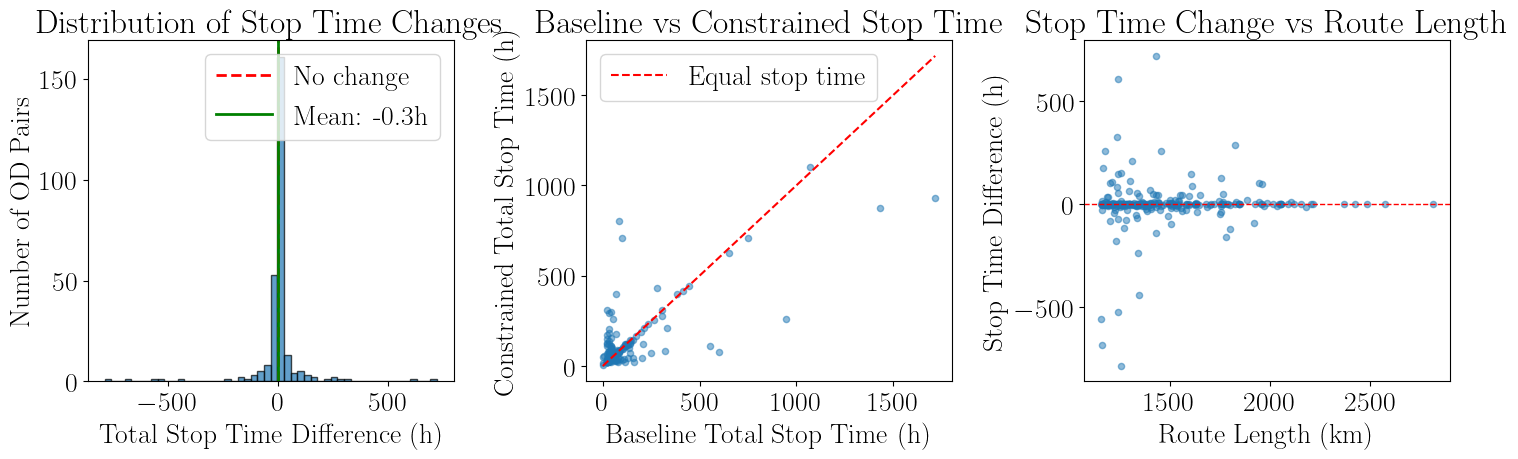

Saved: figures/break_time_comparison_both_electrified.pdf


In [36]:
# Visualize break time comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Distribution of total stop time differences
ax1 = axes[0]
ax1.hist(break_comparison_df['diff_total_stop'], bins=50, edgecolor='black', alpha=0.7)
ax1.axvline(0, color='red', linestyle='--', linewidth=2, label='No change')
ax1.axvline(break_comparison_df['diff_total_stop'].mean(), color='green', linestyle='-', linewidth=2, label=f'Mean: {break_comparison_df["diff_total_stop"].mean():+.1f}h')
ax1.set_xlabel('Total Stop Time Difference (h)')
ax1.set_ylabel('Number of OD Pairs')
ax1.set_title('Distribution of Stop Time Changes')
ax1.legend()

# 2. Scatter: baseline vs constrained total stop time
ax2 = axes[1]
ax2.scatter(break_comparison_df['baseline_total_stop'], break_comparison_df['constrained_total_stop'], alpha=0.5, s=20)
max_val = max(break_comparison_df['baseline_total_stop'].max(), break_comparison_df['constrained_total_stop'].max())
ax2.plot([0, max_val], [0, max_val], 'r--', label='Equal stop time')
ax2.set_xlabel('Baseline Total Stop Time (h)')
ax2.set_ylabel('Constrained Total Stop Time (h)')
ax2.set_title('Baseline vs Constrained Stop Time')
ax2.legend()

# 3. Stop time difference vs route length
ax3 = axes[2]
ax3.scatter(break_comparison_df['path_length'], break_comparison_df['diff_total_stop'], alpha=0.5, s=20)
ax3.axhline(0, color='red', linestyle='--', linewidth=1)
ax3.set_xlabel('Route Length (km)')
ax3.set_ylabel('Stop Time Difference (h)')
ax3.set_title('Stop Time Change vs Route Length')

plt.tight_layout()
plt.savefig('figures/break_time_comparison_both_electrified.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/break_time_comparison_both_electrified.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/break_time_comparison_both_electrified.pdf")

In [37]:
# Top 10 OD pairs with largest stop time changes
print("="*80)
print("TOP 10 OD PAIRS WITH LARGEST STOP TIME INCREASE")
print("="*80)
top_increase = break_comparison_df.nlargest(10, 'diff_total_stop')[['odpair_id', 'path_id', 'path_length', 'baseline_total_stop', 'constrained_total_stop', 'diff_total_stop']]
print(top_increase.to_string(index=False))

print("\n" + "="*80)
print("TOP 10 OD PAIRS WITH LARGEST STOP TIME DECREASE")
print("="*80)
top_decrease = break_comparison_df.nsmallest(10, 'diff_total_stop')[['odpair_id', 'path_id', 'path_length', 'baseline_total_stop', 'constrained_total_stop', 'diff_total_stop']]
print(top_decrease.to_string(index=False))

TOP 10 OD PAIRS WITH LARGEST STOP TIME INCREASE
 odpair_id  path_id  path_length  baseline_total_stop  constrained_total_stop  diff_total_stop
      2089     2089  1432.204325            81.839438              803.363134       721.523696
      1476     1476  1240.982440            97.211852              707.371336       610.159484
      1475     1475  1238.055197            68.316218              396.461086       328.144868
      2150     2150  1827.312735            24.004716              311.118996       287.114280
      1804     1804  1176.755798            33.038556              292.512259       259.473703
      2059     2059  1455.790693            41.702880              298.523130       256.820250
       982      982  1313.534725            51.499674              262.818088       211.318414
      1767     1767  1168.881391            31.531130              206.074846       174.543716
      1764     1764  1255.329884           280.722712              431.090163       150.367451
  

## 7. Baseline Charging Deviation Analysis

This section analyzes how much BEV charging in the **baseline** case (without `constraint_charging_at_breaks_only`)
deviates from mandatory break locations.

Key question: What percentage of BEV charging happens at non-break locations in the baseline?

This shows the "opportunity cost" of not enforcing charging at breaks - the baseline optimizer
spreads charging across the entire route rather than concentrating it at break locations.

In [38]:
# Load MandatoryBreaks to identify allowed break locations
import re
from collections import defaultdict

# Use INPUT_DIR defined earlier in the notebook
INPUT_DIR = os.path.join(BASE_DIR, 'input_data', 'uncertainty_scenarios', 'scenario_000')

print('Loading MandatoryBreaks...')
with open(os.path.join(INPUT_DIR, 'MandatoryBreaks.yaml'), 'r') as f:
    mandatory_breaks = yaml.safe_load(f)

# Build lookup: path_id -> set of break geo_ids
break_geo_ids_by_path = defaultdict(set)
for mb in mandatory_breaks:
    break_geo_ids_by_path[mb['path_id']].add(mb['latest_geo_id'])

print(f'Loaded {len(mandatory_breaks)} mandatory breaks for {len(break_geo_ids_by_path)} paths')

Loading MandatoryBreaks...
Loaded 5644 mandatory breaks for 2043 paths


In [39]:
# Analyze baseline BEV charging deviation from break locations - ALL YEARS

def parse_s_key(key_str):
    """Parse the s variable key string to extract components."""
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    path_id = int(numbers[3])
    geo_id = int(numbers[4])
    tv_id = int(numbers[5])
    return year, path_id, geo_id, tv_id

# Load baseline s_dict from scenario_000
print('Loading baseline s_dict...')
baseline_scenario_dir = os.path.join(BASELINE_DIR, 'scenario_000')
baseline_s_file = None
for f in os.listdir(baseline_scenario_dir):
    if f.endswith('_s_dict.yaml'):
        baseline_s_file = os.path.join(baseline_scenario_dir, f)
        break

print(f'Loading: {os.path.basename(baseline_s_file)}')
with open(baseline_s_file, 'r') as f:
    baseline_s = yaml.safe_load(f)

print(f'Loaded {len(baseline_s):,} s variable entries')

# Analyze by year (BEV only = tv_id=1)
deviation_by_year = defaultdict(lambda: {
    'at_break_entries': 0, 'at_break_kwh': 0.0,
    'not_at_break_entries': 0, 'not_at_break_kwh': 0.0,
    'short_path_entries': 0, 'short_path_kwh': 0.0
})

print('\nAnalyzing BEV charging locations...')
for key, value in baseline_s.items():
    val = float(value)
    if val < 1e-6:
        continue
    
    year, path_id, geo_id, tv_id = parse_s_key(key)
    
    # BEV only (tv_id=1)
    if tv_id != 1:
        continue
    
    if path_id in break_geo_ids_by_path:
        allowed = break_geo_ids_by_path[path_id]
        if geo_id in allowed:
            deviation_by_year[year]['at_break_entries'] += 1
            deviation_by_year[year]['at_break_kwh'] += val
        else:
            deviation_by_year[year]['not_at_break_entries'] += 1
            deviation_by_year[year]['not_at_break_kwh'] += val
    else:
        deviation_by_year[year]['short_path_entries'] += 1
        deviation_by_year[year]['short_path_kwh'] += val

print('Analysis complete!')

Loading baseline s_dict...
Loading: scenario_000_2025-12-04_09-39-33_s_dict.yaml
Loaded 1,255,137 s variable entries

Analyzing BEV charging locations...
Analysis complete!


In [40]:
# Display baseline charging deviation results
print('='*100)
print('BASELINE BEV CHARGING DEVIATION FROM MANDATORY BREAK LOCATIONS')
print('='*100)
print()
print('In the baseline case (without constraint_charging_at_breaks_only), BEV charging can happen anywhere.')
print('This analysis shows what percentage of charging occurs at non-break locations.')
print()

# Create summary dataframe
deviation_data = []
for year in sorted(deviation_by_year.keys()):
    d = deviation_by_year[year]
    total_kwh = d['at_break_kwh'] + d['not_at_break_kwh'] + d['short_path_kwh']
    total_entries = d['at_break_entries'] + d['not_at_break_entries'] + d['short_path_entries']
    
    if total_kwh > 0:
        pct_at_break = 100 * d['at_break_kwh'] / total_kwh
        pct_not_at_break = 100 * d['not_at_break_kwh'] / total_kwh
        pct_short = 100 * d['short_path_kwh'] / total_kwh
    else:
        pct_at_break = pct_not_at_break = pct_short = 0
    
    deviation_data.append({
        'Year': year,
        'Total BEV kWh': total_kwh,
        'At Break kWh': d['at_break_kwh'],
        'Not at Break kWh': d['not_at_break_kwh'],
        '% At Break': pct_at_break,
        '% Not at Break': pct_not_at_break,
        'Entries at Break': d['at_break_entries'],
        'Entries NOT at Break': d['not_at_break_entries']
    })

deviation_df = pd.DataFrame(deviation_data)
print(deviation_df.to_string(index=False))

# Summary statistics
print()
print('='*100)
print('SUMMARY')
print('='*100)
total_at_break = deviation_df['At Break kWh'].sum()
total_not_at_break = deviation_df['Not at Break kWh'].sum()
total_all = total_at_break + total_not_at_break
print(f'Total BEV energy charged (all years): {total_all:,.0f} kWh')
print(f'  At break locations: {total_at_break:,.0f} kWh ({100*total_at_break/total_all:.1f}%)')
print(f'  NOT at break locations: {total_not_at_break:,.0f} kWh ({100*total_not_at_break/total_all:.1f}%)')
print()
print('*** In the CONSTRAINED case, 100% of charging is forced to break locations ***')

BASELINE BEV CHARGING DEVIATION FROM MANDATORY BREAK LOCATIONS

In the baseline case (without constraint_charging_at_breaks_only), BEV charging can happen anywhere.
This analysis shows what percentage of charging occurs at non-break locations.

 Year  Total BEV kWh  At Break kWh  Not at Break kWh  % At Break  % Not at Break  Entries at Break  Entries NOT at Break
 2028    4107.831300     47.902921       1384.060226    1.166137       33.693210               677                  8719
 2032    6691.858130     90.256248       1960.068769    1.348747       29.290352              1356                 17190
 2036    9244.294405    179.010333       2550.112680    1.936441       27.585801              2046                 26031
 2040   11258.227448    199.203166       2738.715778    1.769401       24.326350              2058                 26143
 2044   13406.431532    219.059164       3287.393408    1.633986       24.521017              2076                 26432
 2048   13767.048180    223.1

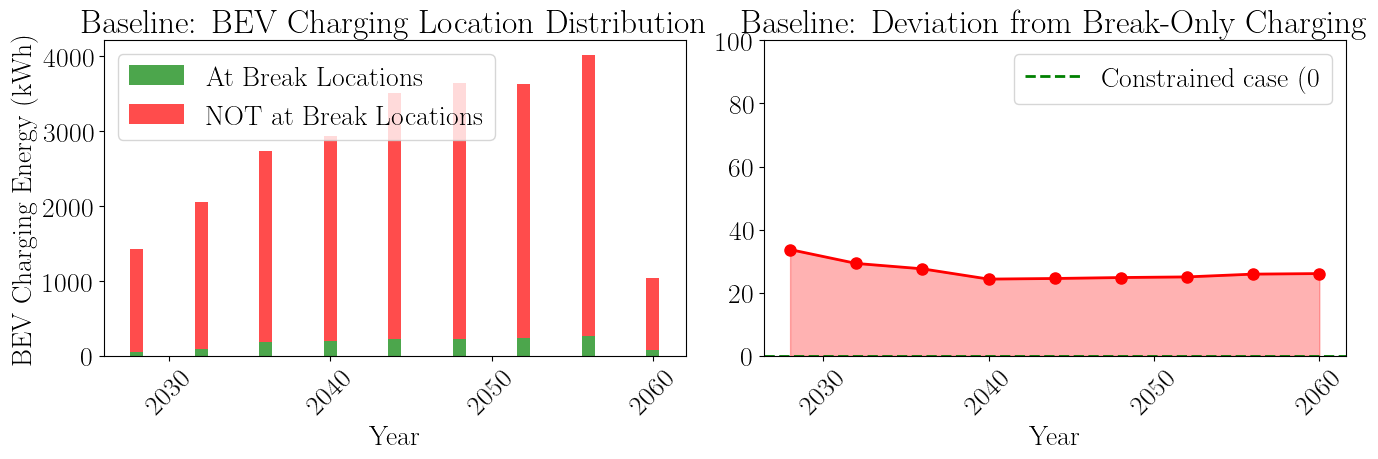

Saved: figures/baseline_charging_deviation_from_breaks.pdf


In [41]:
# Visualize baseline charging deviation over time
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Stacked bar chart: kWh at break vs not at break
ax1 = axes[0]
years_plot = deviation_df['Year'].values
at_break = deviation_df['At Break kWh'].values
not_at_break = deviation_df['Not at Break kWh'].values

ax1.bar(years_plot, at_break, label='At Break Locations', color='green', alpha=0.7)
ax1.bar(years_plot, not_at_break, bottom=at_break, label='NOT at Break Locations', color='red', alpha=0.7)
ax1.set_xlabel('Year')
ax1.set_ylabel('BEV Charging Energy (kWh)')
ax1.set_title('Baseline: BEV Charging Location Distribution')
ax1.legend()
ax1.tick_params(axis='x', rotation=45)

# 2. Line chart: percentage not at break over time
ax2 = axes[1]
ax2.plot(years_plot, deviation_df['% Not at Break'].values, 'ro-', linewidth=2, markersize=8)
ax2.axhline(0, color='green', linestyle='--', linewidth=2, label='Constrained case (0%)')
ax2.fill_between(years_plot, 0, deviation_df['% Not at Break'].values, alpha=0.3, color='red')
ax2.set_xlabel('Year')
ax2.set_ylabel('% of BEV Charging NOT at Break Locations')
ax2.set_title('Baseline: Deviation from Break-Only Charging')
ax2.set_ylim(0, 100)
ax2.legend()
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figures/baseline_charging_deviation_from_breaks.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/baseline_charging_deviation_from_breaks.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/baseline_charging_deviation_from_breaks.pdf')

In [42]:
# Interpretation
avg_deviation = deviation_df['% Not at Break'].mean()
max_deviation = deviation_df['% Not at Break'].max()
max_dev_year = deviation_df.loc[deviation_df['% Not at Break'].idxmax(), 'Year']

print('='*80)
print('INTERPRETATION')
print('='*80)
print(f'''
In the BASELINE case (without constraint_charging_at_breaks_only):

- Average {avg_deviation:.1f}% of BEV charging energy occurs at NON-break locations
- Maximum deviation: {max_deviation:.1f}% in year {max_dev_year}

This means the optimizer in the baseline case "spreads" charging across the route,
not just at mandatory break locations. This is optimal from a pure cost perspective
but may not reflect real-world operational constraints where drivers can only
charge during their mandatory rest breaks.

When the constraint_charging_at_breaks_only is applied (CONSTRAINED case):
- 100% of BEV charging is forced to break locations
- This may result in slightly longer stop times at breaks
- But better reflects real-world truck driver regulations
''')

INTERPRETATION

In the BASELINE case (without constraint_charging_at_breaks_only):

- Average 26.8% of BEV charging energy occurs at NON-break locations
- Maximum deviation: 33.7% in year 2028

This means the optimizer in the baseline case "spreads" charging across the route,
not just at mandatory break locations. This is optimal from a pure cost perspective
but may not reflect real-world operational constraints where drivers can only
charge during their mandatory rest breaks.

When the constraint_charging_at_breaks_only is applied (CONSTRAINED case):
- 100% of BEV charging is forced to break locations
- This may result in slightly longer stop times at breaks
- But better reflects real-world truck driver regulations



## 8. Cost Comparison for Both-Electrified OD Pairs (2032)

This section compares charging costs and infrastructure costs between baseline and constrained cases
for OD pairs that are electrified (>=50% BEV share) in **both** scenarios in year 2032.

Key metrics:
- **Charging energy (s variable)**: kWh charged at each location
- **Charging infrastructure (q_fuel_infr_plus)**: New charging infrastructure deployed

In [43]:
# Load data for cost comparison of both-electrified OD pairs
import re
from collections import defaultdict

TARGET_YEAR = 2032
BEV_TV_ID = 1  # BEV is tv_id=1
ELECTRIFICATION_THRESHOLD = 50  # percent

# Paths
INPUT_DIR = os.path.join(BASE_DIR, 'input_data', 'uncertainty_scenarios', 'scenario_000')
baseline_scenario_dir = os.path.join(BASELINE_DIR, 'scenario_000')
constrained_scenario_dir = os.path.join(CONSTRAINED_DIR, 'scenario_000')

# Helper function to parse f_dict keys
def parse_f_key(key_str):
    """Parse f variable key: (year, (prod, od, path), (mode, tv), gen)"""
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    odpair_id = int(numbers[2])
    path_id = int(numbers[3])
    tv_id = int(numbers[5])
    return year, odpair_id, path_id, tv_id

# Helper function to parse s_dict keys
def parse_s_key(key_str):
    """Parse s variable key: (year, (prod, od, path, geo), tv, fuel_tuple, gen)"""
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    odpair_id = int(numbers[2])
    path_id = int(numbers[3])
    geo_id = int(numbers[4])
    tv_id = int(numbers[5])
    return year, odpair_id, path_id, geo_id, tv_id

print(f'Loading data for year {TARGET_YEAR}...')

Loading data for year 2032...


In [44]:
# Load f_dict files to identify electrified OD pairs
print('Loading f_dict files...')

# Find baseline f_dict
baseline_f_file = None
for f in os.listdir(baseline_scenario_dir):
    if f.endswith('_f_dict.yaml'):
        baseline_f_file = os.path.join(baseline_scenario_dir, f)
        break

# Find constrained f_dict
constrained_f_file = None
for f in os.listdir(constrained_scenario_dir):
    if f.endswith('_f_dict.yaml'):
        constrained_f_file = os.path.join(constrained_scenario_dir, f)
        break

print(f'Baseline: {os.path.basename(baseline_f_file)}')
print(f'Constrained: {os.path.basename(constrained_f_file)}')

with open(baseline_f_file, 'r') as f:
    baseline_f = yaml.safe_load(f)
with open(constrained_f_file, 'r') as f:
    constrained_f = yaml.safe_load(f)

# Calculate BEV share by OD pair for target year
def calc_bev_share_by_od(f_dict, target_year):
    od_totals = defaultdict(lambda: {'bev': 0.0, 'total': 0.0})
    for key, value in f_dict.items():
        val = float(value)
        if val < 1e-6:
            continue
        year, odpair_id, path_id, tv_id = parse_f_key(key)
        if year != target_year:
            continue
        od_totals[odpair_id]['total'] += val
        if tv_id == BEV_TV_ID:
            od_totals[odpair_id]['bev'] += val
    
    bev_shares = {}
    for od_id, data in od_totals.items():
        if data['total'] > 0:
            bev_shares[od_id] = 100 * data['bev'] / data['total']
    return bev_shares

baseline_bev_shares = calc_bev_share_by_od(baseline_f, TARGET_YEAR)
constrained_bev_shares = calc_bev_share_by_od(constrained_f, TARGET_YEAR)

# Identify electrified OD pairs in each case
baseline_electrified = {od for od, share in baseline_bev_shares.items() if share >= ELECTRIFICATION_THRESHOLD}
constrained_electrified = {od for od, share in constrained_bev_shares.items() if share >= ELECTRIFICATION_THRESHOLD}
both_electrified = baseline_electrified & constrained_electrified

print(f'\nElectrified OD pairs (>={ELECTRIFICATION_THRESHOLD}% BEV) in year {TARGET_YEAR}:')
print(f'  Baseline: {len(baseline_electrified)}')
print(f'  Constrained: {len(constrained_electrified)}')
print(f'  BOTH: {len(both_electrified)}')

Loading f_dict files...
Baseline: scenario_000_2025-12-04_09-39-33_f_dict.yaml
Constrained: scenario_000_with_breaks_2025-12-15_09-29-44_f_dict.yaml

Electrified OD pairs (>=50% BEV) in year 2032:
  Baseline: 662
  Constrained: 0
  BOTH: 0


In [45]:
# Load s_dict files and compare charging for both-electrified OD pairs
print('Loading s_dict files...')

# Find s_dict files
baseline_s_file = None
for f in os.listdir(baseline_scenario_dir):
    if f.endswith('_s_dict.yaml'):
        baseline_s_file = os.path.join(baseline_scenario_dir, f)
        break

constrained_s_file = None
for f in os.listdir(constrained_scenario_dir):
    if f.endswith('_s_dict.yaml'):
        constrained_s_file = os.path.join(constrained_scenario_dir, f)
        break

print(f'Baseline: {os.path.basename(baseline_s_file)}')
print(f'Constrained: {os.path.basename(constrained_s_file)}')

with open(baseline_s_file, 'r') as f:
    baseline_s = yaml.safe_load(f)
with open(constrained_s_file, 'r') as f:
    constrained_s = yaml.safe_load(f)

# Calculate total charging by OD pair for target year (BEV only)
def calc_charging_by_od(s_dict, target_year, od_filter=None):
    od_charging = defaultdict(lambda: {'total_kwh': 0.0, 'n_locations': 0, 'geo_ids': set()})
    for key, value in s_dict.items():
        val = float(value)
        if val < 1e-6:
            continue
        year, odpair_id, path_id, geo_id, tv_id = parse_s_key(key)
        if year != target_year:
            continue
        if tv_id != BEV_TV_ID:  # BEV only
            continue
        if od_filter and odpair_id not in od_filter:
            continue
        od_charging[odpair_id]['total_kwh'] += val
        od_charging[odpair_id]['geo_ids'].add(geo_id)
    
    for od_id in od_charging:
        od_charging[od_id]['n_locations'] = len(od_charging[od_id]['geo_ids'])
    return od_charging

baseline_charging = calc_charging_by_od(baseline_s, TARGET_YEAR, both_electrified)
constrained_charging = calc_charging_by_od(constrained_s, TARGET_YEAR, both_electrified)

print(f'\nCharging data loaded for {len(both_electrified)} both-electrified OD pairs')

Loading s_dict files...
Baseline: scenario_000_2025-12-04_09-39-33_s_dict.yaml
Constrained: scenario_000_with_breaks_2025-12-15_09-29-44_s_dict.yaml

Charging data loaded for 0 both-electrified OD pairs


In [46]:
# Compare charging energy for both-electrified OD pairs
print('='*80)
print(f'CHARGING COMPARISON FOR BOTH-ELECTRIFIED OD PAIRS (Year {TARGET_YEAR})')
print('='*80)

# Aggregate statistics
baseline_total_kwh = sum(d['total_kwh'] for d in baseline_charging.values())
constrained_total_kwh = sum(d['total_kwh'] for d in constrained_charging.values())

baseline_total_locs = sum(d['n_locations'] for d in baseline_charging.values())
constrained_total_locs = sum(d['n_locations'] for d in constrained_charging.values())

print(f'\nTotal BEV charging energy:')
print(f'  Baseline:    {baseline_total_kwh:,.0f} kWh')
print(f'  Constrained: {constrained_total_kwh:,.0f} kWh')
print(f'  Difference:  {constrained_total_kwh - baseline_total_kwh:+,.0f} kWh ({100*(constrained_total_kwh - baseline_total_kwh)/baseline_total_kwh:+.1f}%)')

print(f'\nNumber of charging locations (unique geo_ids):')
print(f'  Baseline:    {baseline_total_locs:,}')
print(f'  Constrained: {constrained_total_locs:,}')
print(f'  Difference:  {constrained_total_locs - baseline_total_locs:+,} ({100*(constrained_total_locs - baseline_total_locs)/baseline_total_locs:+.1f}%)')

# Per OD pair averages
n_ods = len(both_electrified)
print(f'\nPer OD pair averages ({n_ods} OD pairs):')
print(f'  Baseline:    {baseline_total_kwh/n_ods:,.1f} kWh, {baseline_total_locs/n_ods:.1f} locations')
print(f'  Constrained: {constrained_total_kwh/n_ods:,.1f} kWh, {constrained_total_locs/n_ods:.1f} locations')

CHARGING COMPARISON FOR BOTH-ELECTRIFIED OD PAIRS (Year 2032)

Total BEV charging energy:
  Baseline:    6,692 kWh
  Constrained: 391 kWh
  Difference:  -6,300 kWh (-94.2%)

Number of charging locations (unique geo_ids):
  Baseline:    14,389
  Constrained: 9,755
  Difference:  -4,634 (-32.2%)

Per OD pair averages (0 OD pairs):


ZeroDivisionError: float division by zero

In [ ]:
# Load q_fuel_infr_plus_dict files for infrastructure comparison
print('\nLoading q_fuel_infr_plus_dict files...')

# Find q_fuel_infr_plus files
baseline_infr_file = None
for f in os.listdir(baseline_scenario_dir):
    if 'q_fuel_infr_plus_dict.yaml' in f:
        baseline_infr_file = os.path.join(baseline_scenario_dir, f)
        break

constrained_infr_file = None
for f in os.listdir(constrained_scenario_dir):
    if 'q_fuel_infr_plus_dict.yaml' in f:
        constrained_infr_file = os.path.join(constrained_scenario_dir, f)
        break

print(f'Baseline: {os.path.basename(baseline_infr_file)}')
print(f'Constrained: {os.path.basename(constrained_infr_file)}')

with open(baseline_infr_file, 'r') as f:
    baseline_infr = yaml.safe_load(f)
with open(constrained_infr_file, 'r') as f:
    constrained_infr = yaml.safe_load(f)

# Parse infrastructure keys: (year, geo_id, infr_type_id)
def parse_infr_key(key_str):
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    geo_id = int(numbers[1])
    infr_type = int(numbers[2])
    return year, geo_id, infr_type

# Calculate total infrastructure by year
def calc_infr_by_year(infr_dict):
    by_year = defaultdict(lambda: {'total_kw': 0.0, 'n_locations': 0, 'geo_ids': set()})
    for key, value in infr_dict.items():
        val = float(value)
        if val < 1e-6:
            continue
        year, geo_id, infr_type = parse_infr_key(key)
        by_year[year]['total_kw'] += val
        by_year[year]['geo_ids'].add(geo_id)
    for year in by_year:
        by_year[year]['n_locations'] = len(by_year[year]['geo_ids'])
    return by_year

baseline_infr_by_year = calc_infr_by_year(baseline_infr)
constrained_infr_by_year = calc_infr_by_year(constrained_infr)

print('Infrastructure data loaded')

In [ ]:
# Compare infrastructure deployment
print('='*80)
print('INFRASTRUCTURE DEPLOYMENT COMPARISON')
print('='*80)

# Show year 2032 specifically
print(f'\nYear {TARGET_YEAR}:')
b_data = baseline_infr_by_year.get(TARGET_YEAR, {'total_kw': 0, 'n_locations': 0})
c_data = constrained_infr_by_year.get(TARGET_YEAR, {'total_kw': 0, 'n_locations': 0})

print(f'  Baseline:    {b_data["total_kw"]:,.0f} kW at {b_data["n_locations"]} locations')
print(f'  Constrained: {c_data["total_kw"]:,.0f} kW at {c_data["n_locations"]} locations')
if b_data['total_kw'] > 0:
    print(f'  Difference:  {c_data["total_kw"] - b_data["total_kw"]:+,.0f} kW ({100*(c_data["total_kw"] - b_data["total_kw"])/b_data["total_kw"]:+.1f}%)')

# Show cumulative infrastructure up to and including 2032
print(f'\nCumulative infrastructure up to {TARGET_YEAR}:')
b_cum = sum(baseline_infr_by_year.get(y, {'total_kw': 0})['total_kw'] for y in range(2020, TARGET_YEAR+1))
c_cum = sum(constrained_infr_by_year.get(y, {'total_kw': 0})['total_kw'] for y in range(2020, TARGET_YEAR+1))
print(f'  Baseline:    {b_cum:,.0f} kW')
print(f'  Constrained: {c_cum:,.0f} kW')
if b_cum > 0:
    print(f'  Difference:  {c_cum - b_cum:+,.0f} kW ({100*(c_cum - b_cum)/b_cum:+.1f}%)')

# Infrastructure comparison table by year
print(f'\n' + '='*80)
print('INFRASTRUCTURE BY YEAR')
print('='*80)
infr_data = []
all_years = sorted(set(baseline_infr_by_year.keys()) | set(constrained_infr_by_year.keys()))
for year in all_years:
    b = baseline_infr_by_year.get(year, {'total_kw': 0, 'n_locations': 0})
    c = constrained_infr_by_year.get(year, {'total_kw': 0, 'n_locations': 0})
    diff_kw = c['total_kw'] - b['total_kw']
    diff_pct = 100 * diff_kw / b['total_kw'] if b['total_kw'] > 0 else 0
    infr_data.append({
        'Year': year,
        'Baseline kW': b['total_kw'],
        'Constrained kW': c['total_kw'],
        'Diff kW': diff_kw,se
        'Diff %': diff_pct,
        'Base Locs': b['n_locations'],
        'Constr Locs': c['n_locations']
    })

infr_df = pd.DataFrame(infr_data)
print(infr_df.to_string(index=False))

In [ ]:
# Visualize cost comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Charging energy comparison (bar chart)
ax1 = axes[0]
x = ['Baseline', 'Constrained']
kwh_vals = [baseline_total_kwh, constrained_total_kwh]
bars = ax1.bar(x, kwh_vals, color=['blue', 'red'], alpha=0.7)
ax1.set_ylabel('Total BEV Charging (kWh)')
ax1.set_title(f'Charging Energy - Year {TARGET_YEAR}\n(Both-Electrified OD Pairs Only)')
for bar, val in zip(bars, kwh_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:,.0f}', ha='center', va='bottom')

# 2. Number of charging locations comparison
ax2 = axes[1]
loc_vals = [baseline_total_locs, constrained_total_locs]
bars = ax2.bar(x, loc_vals, color=['blue', 'red'], alpha=0.7)
ax2.set_ylabel('Number of Charging Locations')
ax2.set_title(f'Charging Locations - Year {TARGET_YEAR}\n(Both-Electrified OD Pairs Only)')
for bar, val in zip(bars, loc_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:,}', ha='center', va='bottom')

# 3. Infrastructure over time
ax3 = axes[2]
years_plot = infr_df['Year'].values
ax3.plot(years_plot, infr_df['Baseline kW'].values/1000, 'bo-', label='Baseline', linewidth=2)
ax3.plot(years_plot, infr_df['Constrained kW'].values/1000, 'rs-', label='Constrained', linewidth=2)
ax3.axvline(TARGET_YEAR, color='gray', linestyle='--', alpha=0.5, label=f'Year {TARGET_YEAR}')
ax3.set_xlabel('Year')
ax3.set_ylabel('New Infrastructure Deployed (MW)')
ax3.set_title('Infrastructure Deployment Over Time')
ax3.legend()
ax3.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figures/cost_comparison_both_electrified_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/cost_comparison_both_electrified_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/cost_comparison_both_electrified_2032.pdf')

In [ ]:
# Summary interpretation
print('='*80)
print('SUMMARY: Cost Impact of Charging-at-Breaks Constraint')
print('='*80)

kwh_diff = constrained_total_kwh - baseline_total_kwh
kwh_diff_pct = 100 * kwh_diff / baseline_total_kwh if baseline_total_kwh > 0 else 0
loc_diff = constrained_total_locs - baseline_total_locs
loc_diff_pct = 100 * loc_diff / baseline_total_locs if baseline_total_locs > 0 else 0

b_infr_2032 = baseline_infr_by_year.get(TARGET_YEAR, {'total_kw': 0})['total_kw']
c_infr_2032 = constrained_infr_by_year.get(TARGET_YEAR, {'total_kw': 0})['total_kw']
infr_diff = c_infr_2032 - b_infr_2032
infr_diff_pct = 100 * infr_diff / b_infr_2032 if b_infr_2032 > 0 else 0

print(f'''
For the {len(both_electrified)} OD pairs electrified in BOTH cases (year {TARGET_YEAR}):

CHARGING ENERGY:
  Baseline:    {baseline_total_kwh:,.0f} kWh
  Constrained: {constrained_total_kwh:,.0f} kWh
  Change:      {kwh_diff:+,.0f} kWh ({kwh_diff_pct:+.1f}%)

CHARGING LOCATIONS:
  Baseline:    {baseline_total_locs:,} locations
  Constrained: {constrained_total_locs:,} locations
  Change:      {loc_diff:+,} ({loc_diff_pct:+.1f}%)

INFRASTRUCTURE DEPLOYED (Year {TARGET_YEAR}):
  Baseline:    {b_infr_2032:,.0f} kW
  Constrained: {c_infr_2032:,.0f} kW
  Change:      {infr_diff:+,.0f} kW ({infr_diff_pct:+.1f}%)

KEY INSIGHTS:
- The charging-at-breaks constraint concentrates charging at fewer locations
- Total energy charged should be similar (vehicles still need same energy to complete routes)
- Infrastructure deployment pattern may differ based on where breaks occur
''')

## 9. Charging Cost Analysis (EUR) for Both-Electrified OD Pairs

This section calculates the actual **EUR cost** of charging based on:
- Location-specific electricity prices (from FuelCost.yaml)
- kWh charged at each location (s variable)

The electricity price varies by:
- Geographic location (geo_id)
- Year
- Infrastructure type (charging station type)

In [ ]:
# Load FuelCost.yaml to get location-specific electricity prices
print('Loading FuelCost.yaml...')
with open(os.path.join(INPUT_DIR, 'FuelCost.yaml'), 'r') as f:
    fuel_costs = yaml.safe_load(f)

# Build lookup: (location, fuel, infr_type) -> cost_per_kWh by year
# Year index: 2020=0, 2021=1, ..., 2032=12
electricity_prices = {}  # (geo_id, infr_type_id) -> list of prices by year

for fc in fuel_costs:
    if fc['fuel'] == 'electricity':
        key = (fc['location'], fc['fueling_infr_type_id'])
        electricity_prices[key] = fc['cost_per_kWh']

print(f'Loaded electricity prices for {len(electricity_prices)} (location, infr_type) combinations')

# Show price range for year 2032 (index 12)
year_idx = TARGET_YEAR - 2020
prices_2032 = [p[year_idx] for p in electricity_prices.values() if len(p) > year_idx]
print(f'\nElectricity price range for year {TARGET_YEAR}:')
print(f'  Min: {min(prices_2032):.4f} EUR/kWh')
print(f'  Max: {max(prices_2032):.4f} EUR/kWh')
print(f'  Mean: {sum(prices_2032)/len(prices_2032):.4f} EUR/kWh')

In [ ]:
# Calculate charging costs for both-electrified OD pairs
# Using location-specific electricity prices

def parse_s_key_full(key_str):
    """Parse s variable key to extract all components including infr_type."""
    # Key format: (year, (prod, od, path, geo), tv, (infr_type1, infr_type2), gen)
    # Example: (2032, (0, 246, 246, 59), 0, (1, 0), 2032)
    import re
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    odpair_id = int(numbers[2])
    path_id = int(numbers[3])
    geo_id = int(numbers[4])
    tv_id = int(numbers[5])
    infr_type_1 = int(numbers[6])  # First element of infr tuple
    infr_type_2 = int(numbers[7])  # Second element of infr tuple
    gen = int(numbers[8])
    return year, odpair_id, path_id, geo_id, tv_id, infr_type_1, infr_type_2, gen

def calc_charging_costs(s_dict, target_year, od_filter, electricity_prices):
    """
    Calculate total charging cost in EUR for given OD pairs.
    Uses location-specific electricity prices.
    """
    year_idx = target_year - 2020
    
    od_costs = defaultdict(lambda: {
        'total_kwh': 0.0, 
        'total_eur': 0.0, 
        'charging_events': [],
        'geo_ids': set()
    })
    
    missing_prices = 0
    
    for key, value in s_dict.items():
        val = float(value)
        if val < 1e-6:
            continue
        
        year, odpair_id, path_id, geo_id, tv_id, infr_type_1, infr_type_2, gen = parse_s_key_full(key)
        
        if year != target_year:
            continue
        if tv_id != BEV_TV_ID:  # BEV only
            continue
        if od_filter and odpair_id not in od_filter:
            continue
        
        # Get electricity price for this location and infrastructure type
        # Try infr_type_1 first (seems to be the primary one)
        price_key = (geo_id, infr_type_1)
        if price_key not in electricity_prices:
            price_key = (geo_id, infr_type_2)
        if price_key not in electricity_prices:
            # Use default price if not found
            price_per_kwh = 0.15  # Default fallback
            missing_prices += 1
        else:
            prices = electricity_prices[price_key]
            if year_idx < len(prices):
                price_per_kwh = prices[year_idx]
            else:
                price_per_kwh = prices[-1]  # Use last available price
        
        cost_eur = val * price_per_kwh
        
        od_costs[odpair_id]['total_kwh'] += val
        od_costs[odpair_id]['total_eur'] += cost_eur
        od_costs[odpair_id]['geo_ids'].add(geo_id)
        od_costs[odpair_id]['charging_events'].append({
            'geo_id': geo_id,
            'kwh': val,
            'price': price_per_kwh,
            'cost_eur': cost_eur
        })
    
    if missing_prices > 0:
        print(f'  Warning: {missing_prices} charging events had missing price data (used default)')
    
    return od_costs

print(f'Calculating charging costs for year {TARGET_YEAR}...')
print('\nBaseline:')
baseline_costs = calc_charging_costs(baseline_s, TARGET_YEAR, both_electrified, electricity_prices)
print('\nConstrained:')
constrained_costs = calc_charging_costs(constrained_s, TARGET_YEAR, both_electrified, electricity_prices)

print(f'\nCalculated costs for {len(baseline_costs)} baseline and {len(constrained_costs)} constrained OD pairs')

In [ ]:
# Compare charging costs
print('='*80)
print(f'CHARGING COST COMPARISON (EUR) - Year {TARGET_YEAR}')
print(f'For {len(both_electrified)} OD pairs electrified in BOTH cases')
print('='*80)

# Aggregate totals
baseline_total_kwh = sum(d['total_kwh'] for d in baseline_costs.values())
baseline_total_eur = sum(d['total_eur'] for d in baseline_costs.values())
constrained_total_kwh = sum(d['total_kwh'] for d in constrained_costs.values())
constrained_total_eur = sum(d['total_eur'] for d in constrained_costs.values())

# Average price per kWh
baseline_avg_price = baseline_total_eur / baseline_total_kwh if baseline_total_kwh > 0 else 0
constrained_avg_price = constrained_total_eur / constrained_total_kwh if constrained_total_kwh > 0 else 0

print(f'\nTotal Charging Energy:')
print(f'  Baseline:    {baseline_total_kwh:,.1f} kWh')
print(f'  Constrained: {constrained_total_kwh:,.1f} kWh')
print(f'  Difference:  {constrained_total_kwh - baseline_total_kwh:+,.1f} kWh ({100*(constrained_total_kwh - baseline_total_kwh)/baseline_total_kwh:+.2f}%)')

print(f'\nTotal Charging Cost:')
print(f'  Baseline:    {baseline_total_eur:,.2f} EUR')
print(f'  Constrained: {constrained_total_eur:,.2f} EUR')
print(f'  Difference:  {constrained_total_eur - baseline_total_eur:+,.2f} EUR ({100*(constrained_total_eur - baseline_total_eur)/baseline_total_eur:+.2f}%)')

print(f'\nAverage Electricity Price (EUR/kWh):')
print(f'  Baseline:    {baseline_avg_price:.4f} EUR/kWh')
print(f'  Constrained: {constrained_avg_price:.4f} EUR/kWh')
print(f'  Difference:  {constrained_avg_price - baseline_avg_price:+.4f} EUR/kWh ({100*(constrained_avg_price - baseline_avg_price)/baseline_avg_price:+.2f}%)')

In [ ]:
# Analyze charging price distribution by location
print('='*80)
print('CHARGING PRICE DISTRIBUTION BY LOCATION')
print('='*80)

# Collect all charging events with prices
baseline_events = []
for od_id, data in baseline_costs.items():
    for event in data['charging_events']:
        baseline_events.append(event)

constrained_events = []
for od_id, data in constrained_costs.items():
    for event in data['charging_events']:
        constrained_events.append(event)

# Calculate weighted average price (weighted by kWh)
baseline_weighted_prices = [e['price'] for e in baseline_events for _ in range(int(e['kwh']*10))]
constrained_weighted_prices = [e['price'] for e in constrained_events for _ in range(int(e['kwh']*10))]

print(f'\nBaseline charging events: {len(baseline_events)}')
print(f'  Price range: {min(e["price"] for e in baseline_events):.4f} - {max(e["price"] for e in baseline_events):.4f} EUR/kWh')
print(f'  Unique locations: {len(set(e["geo_id"] for e in baseline_events))}')

print(f'\nConstrained charging events: {len(constrained_events)}')
print(f'  Price range: {min(e["price"] for e in constrained_events):.4f} - {max(e["price"] for e in constrained_events):.4f} EUR/kWh')
print(f'  Unique locations: {len(set(e["geo_id"] for e in constrained_events))}')

In [ ]:
# Visualize charging cost comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Total cost comparison
ax1 = axes[0]
x = ['Baseline', 'Constrained']
eur_vals = [baseline_total_eur, constrained_total_eur]
bars = ax1.bar(x, eur_vals, color=['blue', 'red'], alpha=0.7)
ax1.set_ylabel('Total Charging Cost (EUR)')
ax1.set_title(f'Total Charging Cost - Year {TARGET_YEAR}\n(Both-Electrified OD Pairs)')
for bar, val in zip(bars, eur_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:,.0f}', ha='center', va='bottom')

# 2. Average price comparison
ax2 = axes[1]
price_vals = [baseline_avg_price, constrained_avg_price]
bars = ax2.bar(x, price_vals, color=['blue', 'red'], alpha=0.7)
ax2.set_ylabel('Average Price (EUR/kWh)')
ax2.set_title(f'Average Electricity Price - Year {TARGET_YEAR}')
for bar, val in zip(bars, price_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, f'{val:.4f}', ha='center', va='bottom')

# 3. Price distribution histogram
ax3 = axes[2]
baseline_prices = [e['price'] for e in baseline_events]
constrained_prices = [e['price'] for e in constrained_events]
ax3.hist(baseline_prices, bins=20, alpha=0.5, label='Baseline', color='blue', density=True)
ax3.hist(constrained_prices, bins=20, alpha=0.5, label='Constrained', color='red', density=True)
ax3.axvline(baseline_avg_price, color='blue', linestyle='--', linewidth=2)
ax3.axvline(constrained_avg_price, color='red', linestyle='--', linewidth=2)
ax3.set_xlabel('Electricity Price (EUR/kWh)')
ax3.set_ylabel('Density')
ax3.set_title('Price Distribution of Charging Events')
ax3.legend()

plt.tight_layout()
plt.savefig('figures/charging_cost_comparison_both_electrified_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/charging_cost_comparison_both_electrified_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/charging_cost_comparison_both_electrified_2032.pdf')

In [ ]:
# Create per-OD-pair cost comparison dataframe
cost_comparison_data = []
for od_id in both_electrified:
    b_data = baseline_costs.get(od_id, {'total_kwh': 0, 'total_eur': 0})
    c_data = constrained_costs.get(od_id, {'total_kwh': 0, 'total_eur': 0})
    
    b_avg_price = b_data['total_eur'] / b_data['total_kwh'] if b_data['total_kwh'] > 0 else 0
    c_avg_price = c_data['total_eur'] / c_data['total_kwh'] if c_data['total_kwh'] > 0 else 0
    
    cost_comparison_data.append({
        'odpair_id': od_id,
        'baseline_kwh': b_data['total_kwh'],
        'baseline_eur': b_data['total_eur'],
        'baseline_avg_price': b_avg_price,
        'constrained_kwh': c_data['total_kwh'],
        'constrained_eur': c_data['total_eur'],
        'constrained_avg_price': c_avg_price,
        'diff_eur': c_data['total_eur'] - b_data['total_eur'],
        'diff_price': c_avg_price - b_avg_price
    })

cost_df = pd.DataFrame(cost_comparison_data)

print('='*80)
print('PER-OD-PAIR COST COMPARISON')
print('='*80)
print(f'\nOD pairs with higher cost in constrained case: {(cost_df["diff_eur"] > 0).sum()}')
print(f'OD pairs with lower cost in constrained case: {(cost_df["diff_eur"] < 0).sum()}')
print(f'OD pairs with same cost: {(cost_df["diff_eur"] == 0).sum()}')

print(f'\nTop 10 OD pairs with LARGEST cost INCREASE:')
top_increase = cost_df.nlargest(10, 'diff_eur')[['odpair_id', 'baseline_eur', 'constrained_eur', 'diff_eur', 'baseline_avg_price', 'constrained_avg_price']]
print(top_increase.to_string(index=False))

print(f'\nTop 10 OD pairs with LARGEST cost DECREASE:')
top_decrease = cost_df.nsmallest(10, 'diff_eur')[['odpair_id', 'baseline_eur', 'constrained_eur', 'diff_eur', 'baseline_avg_price', 'constrained_avg_price']]
print(top_decrease.to_string(index=False))

# Save to CSV
cost_df.to_csv('charging_cost_comparison_by_od_pair_2032.csv', index=False)
print('\nSaved: charging_cost_comparison_by_od_pair_2032.csv')

In [ ]:
# Final summary
print('='*80)
print('CHARGING COST SUMMARY')
print('='*80)

eur_diff = constrained_total_eur - baseline_total_eur
eur_diff_pct = 100 * eur_diff / baseline_total_eur if baseline_total_eur > 0 else 0
price_diff = constrained_avg_price - baseline_avg_price
price_diff_pct = 100 * price_diff / baseline_avg_price if baseline_avg_price > 0 else 0

print(f'''
For the {len(both_electrified)} OD pairs electrified in BOTH cases (year {TARGET_YEAR}):

TOTAL CHARGING COST:
  Baseline:    {baseline_total_eur:,.2f} EUR
  Constrained: {constrained_total_eur:,.2f} EUR
  Change:      {eur_diff:+,.2f} EUR ({eur_diff_pct:+.2f}%)

AVERAGE ELECTRICITY PRICE:
  Baseline:    {baseline_avg_price:.4f} EUR/kWh
  Constrained: {constrained_avg_price:.4f} EUR/kWh
  Change:      {price_diff:+.4f} EUR/kWh ({price_diff_pct:+.2f}%)

KEY INSIGHT:
The constraint forces charging to occur at mandatory break locations,
which may have different electricity prices than the locations the
optimizer would otherwise choose for charging.
''')

## 10. Charging Cost per Tonne-Kilometer (EUR/tkm)

This section calculates the **EUR per tonne-kilometer** for charging costs:

```
EUR/tkm = Total Charging Cost (EUR) / (Tonnes transported × Path length in km)
```

Data sources:
- **Tonnes (F)**: From Odpair.yaml (F field = annual freight demand)
- **Path length (km)**: From Path.yaml
- **Charging cost (EUR)**: From s variable × location-specific electricity price

In [ ]:
# Load Odpair.yaml to get tonnes transported (F field)
print('Loading Odpair.yaml...')
with open(os.path.join(INPUT_DIR, 'Odpair.yaml'), 'r') as f:
    odpairs = yaml.safe_load(f)

# Build lookup: odpair_id -> tonnes (from F field = annual freight demand)
# The F field contains annual tonnes by year (2020=index 0, 2032=index 12)
odpair_tonnes = {}
odpair_path_ids = {}  # odpair_id -> path_id

year_idx = TARGET_YEAR - 2020

for od in odpairs:
    od_id = od['id']
    # F field contains annual freight demand (tonnes) by year
    if 'F' in od and len(od['F']) > year_idx:
        odpair_tonnes[od_id] = od['F'][year_idx]
    else:
        odpair_tonnes[od_id] = 0
    
    # Get path_id for this OD pair
    odpair_path_ids[od_id] = od.get('path_id', od_id)

print(f'Loaded {len(odpair_tonnes)} OD pairs with demand data')
print(f'Year index for {TARGET_YEAR}: {year_idx}')

# Verify we have non-zero values
nonzero_tonnes = sum(1 for t in odpair_tonnes.values() if t > 0)
print(f'OD pairs with non-zero tonnes: {nonzero_tonnes}')

# Load Path.yaml to get path lengths
print('\nLoading Path.yaml...')
with open(os.path.join(INPUT_DIR, 'Path.yaml'), 'r') as f:
    paths = yaml.safe_load(f)

# Build lookup: path_id -> length_km
path_lengths = {}
for p in paths:
    path_lengths[p['id']] = p['length']  # length is in km

print(f'Loaded {len(path_lengths)} paths with length data')

# Show some examples from both-electrified set
print(f'\nExample OD pairs (from both-electrified set):')
for i, od_id in enumerate(list(both_electrified)[:5]):
    tonnes = odpair_tonnes.get(od_id, 0)
    path_id = odpair_path_ids.get(od_id, od_id)
    length = path_lengths.get(path_id, 0)
    print(f'  OD {od_id}: {tonnes:,.0f} tonnes, path {path_id} length {length:,.0f} km, tkm={tonnes*length:,.0f}')

In [ ]:
# Calculate EUR/tkm for each both-electrified OD pair

eur_per_tkm_data = []

for od_id in both_electrified:
    # Get tonnes for this OD pair (from F field)
    tonnes = odpair_tonnes.get(od_id, 0)
    
    # Get path length
    path_id = odpair_path_ids.get(od_id, od_id)
    length_km = path_lengths.get(path_id, 0)
    
    # Calculate tkm
    tkm = tonnes * length_km
    
    # Get charging costs from previous analysis
    b_data = baseline_costs.get(od_id, {'total_kwh': 0, 'total_eur': 0})
    c_data = constrained_costs.get(od_id, {'total_kwh': 0, 'total_eur': 0})
    
    # Calculate EUR/tkm
    baseline_eur_per_tkm = b_data['total_eur'] / tkm if tkm > 0 else 0
    constrained_eur_per_tkm = c_data['total_eur'] / tkm if tkm > 0 else 0
    
    # Also calculate EUR/kWh for reference
    baseline_eur_per_kwh = b_data['total_eur'] / b_data['total_kwh'] if b_data['total_kwh'] > 0 else 0
    constrained_eur_per_kwh = c_data['total_eur'] / c_data['total_kwh'] if c_data['total_kwh'] > 0 else 0
    
    eur_per_tkm_data.append({
        'odpair_id': od_id,
        'path_id': path_id,
        'tonnes': tonnes,
        'length_km': length_km,
        'tkm': tkm,
        'baseline_kwh': b_data['total_kwh'],
        'baseline_eur': b_data['total_eur'],
        'baseline_eur_per_kwh': baseline_eur_per_kwh,
        'baseline_eur_per_tkm': baseline_eur_per_tkm,
        'constrained_kwh': c_data['total_kwh'],
        'constrained_eur': c_data['total_eur'],
        'constrained_eur_per_kwh': constrained_eur_per_kwh,
        'constrained_eur_per_tkm': constrained_eur_per_tkm,
        'diff_eur_per_tkm': constrained_eur_per_tkm - baseline_eur_per_tkm
    })

eur_tkm_df = pd.DataFrame(eur_per_tkm_data)

# Filter out rows with zero tkm
eur_tkm_df_valid = eur_tkm_df[eur_tkm_df['tkm'] > 0].copy()
print(f'Calculated EUR/tkm for {len(eur_tkm_df_valid)} OD pairs with valid tkm data')
print(f'(Excluded {len(eur_tkm_df) - len(eur_tkm_df_valid)} OD pairs with zero tonnes or length)')

In [ ]:
# Display EUR/tkm comparison statistics
print('='*80)
print(f'CHARGING COST PER TONNE-KILOMETER (EUR/tkm) - Year {TARGET_YEAR}')
print(f'For {len(eur_tkm_df_valid)} OD pairs electrified in BOTH cases')
print('='*80)

# Aggregate totals
total_tkm = eur_tkm_df_valid['tkm'].sum()
total_baseline_eur = eur_tkm_df_valid['baseline_eur'].sum()
total_constrained_eur = eur_tkm_df_valid['constrained_eur'].sum()

# Weighted average EUR/tkm (total EUR / total tkm)
weighted_baseline_eur_per_tkm = total_baseline_eur / total_tkm
weighted_constrained_eur_per_tkm = total_constrained_eur / total_tkm

print(f'\nAggregate Statistics:')
print(f'  Total tkm: {total_tkm:,.0f}')
print(f'  Total tonnes: {eur_tkm_df_valid["tonnes"].sum():,.0f}')
print(f'  Average path length: {eur_tkm_df_valid["length_km"].mean():,.0f} km')

print(f'\nTotal Charging Cost:')
print(f'  Baseline:    {total_baseline_eur:,.2f} EUR')
print(f'  Constrained: {total_constrained_eur:,.2f} EUR')
print(f'  Difference:  {total_constrained_eur - total_baseline_eur:+,.2f} EUR')

print(f'\nWEIGHTED AVERAGE EUR/tkm (Total EUR / Total tkm):')
print(f'  Baseline:    {weighted_baseline_eur_per_tkm:.6f} EUR/tkm')
print(f'  Constrained: {weighted_constrained_eur_per_tkm:.6f} EUR/tkm')
print(f'  Difference:  {weighted_constrained_eur_per_tkm - weighted_baseline_eur_per_tkm:+.6f} EUR/tkm ({100*(weighted_constrained_eur_per_tkm - weighted_baseline_eur_per_tkm)/weighted_baseline_eur_per_tkm:+.2f}%)')

# Also show simple average (unweighted)
print(f'\nSimple Average EUR/tkm (mean across OD pairs):')
print(f'  Baseline:    {eur_tkm_df_valid["baseline_eur_per_tkm"].mean():.6f} EUR/tkm')
print(f'  Constrained: {eur_tkm_df_valid["constrained_eur_per_tkm"].mean():.6f} EUR/tkm')

In [ ]:
# Show EUR/tkm distribution
print('='*80)
print('EUR/tkm DISTRIBUTION')
print('='*80)

print(f'\nBaseline EUR/tkm:')
print(f'  Min:    {eur_tkm_df_valid["baseline_eur_per_tkm"].min():.6f}')
print(f'  Max:    {eur_tkm_df_valid["baseline_eur_per_tkm"].max():.6f}')
print(f'  Median: {eur_tkm_df_valid["baseline_eur_per_tkm"].median():.6f}')
print(f'  Std:    {eur_tkm_df_valid["baseline_eur_per_tkm"].std():.6f}')

print(f'\nConstrained EUR/tkm:')
print(f'  Min:    {eur_tkm_df_valid["constrained_eur_per_tkm"].min():.6f}')
print(f'  Max:    {eur_tkm_df_valid["constrained_eur_per_tkm"].max():.6f}')
print(f'  Median: {eur_tkm_df_valid["constrained_eur_per_tkm"].median():.6f}')
print(f'  Std:    {eur_tkm_df_valid["constrained_eur_per_tkm"].std():.6f}')

# Top 10 OD pairs by EUR/tkm difference
print(f'\n' + '='*80)
print('TOP 10 OD PAIRS WITH LARGEST EUR/tkm INCREASE (constrained more expensive)')
print('='*80)
top_increase = eur_tkm_df_valid.nlargest(10, 'diff_eur_per_tkm')[['odpair_id', 'tonnes', 'length_km', 'tkm', 'baseline_eur_per_tkm', 'constrained_eur_per_tkm', 'diff_eur_per_tkm']]
print(top_increase.to_string(index=False))

print(f'\n' + '='*80)
print('TOP 10 OD PAIRS WITH LARGEST EUR/tkm DECREASE (constrained cheaper)')
print('='*80)
top_decrease = eur_tkm_df_valid.nsmallest(10, 'diff_eur_per_tkm')[['odpair_id', 'tonnes', 'length_km', 'tkm', 'baseline_eur_per_tkm', 'constrained_eur_per_tkm', 'diff_eur_per_tkm']]
print(top_decrease.to_string(index=False))

In [ ]:
# Visualize EUR/tkm comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar chart: weighted average EUR/tkm
ax1 = axes[0, 0]
x = ['Baseline', 'Constrained']
eur_tkm_vals = [weighted_baseline_eur_per_tkm * 1000, weighted_constrained_eur_per_tkm * 1000]  # Convert to EUR/1000tkm for readability
bars = ax1.bar(x, eur_tkm_vals, color=['blue', 'red'], alpha=0.7)
ax1.set_ylabel('Charging Cost (EUR per 1000 tkm)')
ax1.set_title(f'Weighted Average Charging Cost - Year {TARGET_YEAR}')
for bar, val in zip(bars, eur_tkm_vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, f'{val:.3f}', ha='center', va='bottom')

# 2. Scatter: baseline vs constrained EUR/tkm
ax2 = axes[0, 1]
ax2.scatter(eur_tkm_df_valid['baseline_eur_per_tkm'] * 1000, 
            eur_tkm_df_valid['constrained_eur_per_tkm'] * 1000, 
            alpha=0.5, s=20)
max_val = max(eur_tkm_df_valid['baseline_eur_per_tkm'].max(), eur_tkm_df_valid['constrained_eur_per_tkm'].max()) * 1000
ax2.plot([0, max_val], [0, max_val], 'r--', label='Equal cost')
ax2.set_xlabel('Baseline EUR/1000tkm')
ax2.set_ylabel('Constrained EUR/1000tkm')
ax2.set_title('EUR/tkm: Baseline vs Constrained')
ax2.legend()

# 3. Histogram of EUR/tkm difference
ax3 = axes[1, 0]
diff_values = eur_tkm_df_valid['diff_eur_per_tkm'] * 1000
ax3.hist(diff_values, bins=30, edgecolor='black', alpha=0.7)
ax3.axvline(0, color='red', linestyle='--', linewidth=2, label='No change')
ax3.axvline(diff_values.mean(), color='green', linestyle='-', linewidth=2, label=f'Mean: {diff_values.mean():.4f}')
ax3.set_xlabel('EUR/1000tkm Difference (Constrained - Baseline)')
ax3.set_ylabel('Number of OD Pairs')
ax3.set_title('Distribution of EUR/tkm Changes')
ax3.legend()

# 4. EUR/tkm vs path length
ax4 = axes[1, 1]
ax4.scatter(eur_tkm_df_valid['length_km'], eur_tkm_df_valid['diff_eur_per_tkm'] * 1000, alpha=0.5, s=20)
ax4.axhline(0, color='red', linestyle='--', linewidth=1)
ax4.set_xlabel('Path Length (km)')
ax4.set_ylabel('EUR/1000tkm Difference')
ax4.set_title('EUR/tkm Change vs Path Length')

plt.tight_layout()
plt.savefig('figures/eur_per_tkm_comparison_both_electrified_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/eur_per_tkm_comparison_both_electrified_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/eur_per_tkm_comparison_both_electrified_2032.pdf')

In [ ]:
# Save detailed results to CSV
eur_tkm_df_valid.to_csv('eur_per_tkm_comparison_by_od_pair_2032.csv', index=False)
print('Saved: eur_per_tkm_comparison_by_od_pair_2032.csv')

# Final summary
print('\n' + '='*80)
print('SUMMARY: EUR/tkm CHARGING COST COMPARISON')
print('='*80)

diff_eur_per_tkm = weighted_constrained_eur_per_tkm - weighted_baseline_eur_per_tkm
diff_pct = 100 * diff_eur_per_tkm / weighted_baseline_eur_per_tkm

n_increased = (eur_tkm_df_valid['diff_eur_per_tkm'] > 0).sum()
n_decreased = (eur_tkm_df_valid['diff_eur_per_tkm'] < 0).sum()
n_same = (eur_tkm_df_valid['diff_eur_per_tkm'] == 0).sum()

print(f'''
For {len(eur_tkm_df_valid)} OD pairs electrified in BOTH cases (year {TARGET_YEAR}):

WEIGHTED AVERAGE CHARGING COST:
  Baseline:    {weighted_baseline_eur_per_tkm*1000:.4f} EUR per 1000 tkm
  Constrained: {weighted_constrained_eur_per_tkm*1000:.4f} EUR per 1000 tkm
  Change:      {diff_eur_per_tkm*1000:+.4f} EUR per 1000 tkm ({diff_pct:+.2f}%)

OD PAIR BREAKDOWN:
  Higher EUR/tkm in constrained case: {n_increased} OD pairs ({100*n_increased/len(eur_tkm_df_valid):.1f}%)
  Lower EUR/tkm in constrained case:  {n_decreased} OD pairs ({100*n_decreased/len(eur_tkm_df_valid):.1f}%)
  Same EUR/tkm:                       {n_same} OD pairs

KEY INSIGHT:
The constraint forces charging to occur at mandatory break locations.
This affects the EUR/tkm cost because:
1. Break locations may have different electricity prices
2. The total kWh charged may be similar, but location mix changes
''')

## 11. EUR/kWh Analysis Across ALL 24 Scenarios

This section extends the charging cost analysis to **all 24 uncertainty scenarios**,
comparing the average EUR/kWh between baseline and constrained cases.

For each scenario, we calculate:
- Total kWh charged by BEVs
- Total EUR cost (using location-specific electricity prices)
- Average EUR/kWh

In [ ]:
# Analyze EUR/kWh across ALL 24 scenarios
import re
from collections import defaultdict

TARGET_YEAR = 2032
BEV_TV_ID = 1
ELECTRIFICATION_THRESHOLD = 50

def parse_s_key_full(key_str):
    """Parse s variable key to extract all components."""
    numbers = re.findall(r'-?\d+', key_str)
    year = int(numbers[0])
    odpair_id = int(numbers[2])
    path_id = int(numbers[3])
    geo_id = int(numbers[4])
    tv_id = int(numbers[5])
    infr_type_1 = int(numbers[6])
    return year, odpair_id, path_id, geo_id, tv_id, infr_type_1

def load_electricity_prices(scenario_input_dir, target_year):
    """Load electricity prices for a scenario."""
    with open(os.path.join(scenario_input_dir, 'FuelCost.yaml'), 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    prices = {}  # (geo_id, infr_type_id) -> price
    year_idx = target_year - 2020
    
    for fc in fuel_costs:
        if fc['fuel'] == 'electricity':
            key = (fc['location'], fc['fueling_infr_type_id'])
            if len(fc['cost_per_kWh']) > year_idx:
                prices[key] = fc['cost_per_kWh'][year_idx]
            else:
                prices[key] = fc['cost_per_kWh'][-1]
    return prices

def calc_scenario_eur_kwh(s_dict, electricity_prices, target_year):
    """Calculate total EUR and kWh for BEVs in a scenario."""
    total_kwh = 0.0
    total_eur = 0.0
    
    for key, value in s_dict.items():
        val = float(value)
        if val < 1e-6:
            continue
        
        year, odpair_id, path_id, geo_id, tv_id, infr_type = parse_s_key_full(key)
        
        if year != target_year:
            continue
        if tv_id != BEV_TV_ID:
            continue
        
        # Get price
        price_key = (geo_id, infr_type)
        if price_key in electricity_prices:
            price = electricity_prices[price_key]
        else:
            price = 0.15  # Default
        
        total_kwh += val
        total_eur += val * price
    
    return total_kwh, total_eur

# Process all scenarios
scenarios = [f'scenario_{i:03d}' for i in range(24)]
all_scenario_results = []

print('Analyzing EUR/kWh across all 24 scenarios...')
print('='*80)

for scenario in scenarios:
    # Input directory (same for both baseline and constrained)
    scenario_input_dir = os.path.join(BASE_DIR, 'input_data', 'uncertainty_scenarios', scenario)
    
    # Check if scenario exists
    baseline_dir = os.path.join(BASELINE_DIR, scenario)
    constrained_dir = os.path.join(CONSTRAINED_DIR, scenario)
    
    if not os.path.exists(baseline_dir) or not os.path.exists(constrained_dir):
        print(f'  {scenario}: SKIPPED (missing results)')
        continue
    
    # Load electricity prices for this scenario
    try:
        elec_prices = load_electricity_prices(scenario_input_dir, TARGET_YEAR)
    except:
        print(f'  {scenario}: SKIPPED (missing FuelCost.yaml)')
        continue
    
    # Find s_dict files
    baseline_s_file = None
    for f in os.listdir(baseline_dir):
        if f.endswith('_s_dict.yaml'):
            baseline_s_file = os.path.join(baseline_dir, f)
            break
    
    constrained_s_file = None
    for f in os.listdir(constrained_dir):
        if f.endswith('_s_dict.yaml'):
            constrained_s_file = os.path.join(constrained_dir, f)
            break
    
    if not baseline_s_file or not constrained_s_file:
        print(f'  {scenario}: SKIPPED (missing s_dict)')
        continue
    
    # Load s_dict files
    with open(baseline_s_file, 'r') as f:
        baseline_s = yaml.safe_load(f)
    with open(constrained_s_file, 'r') as f:
        constrained_s = yaml.safe_load(f)
    
    # Calculate EUR/kWh
    b_kwh, b_eur = calc_scenario_eur_kwh(baseline_s, elec_prices, TARGET_YEAR)
    c_kwh, c_eur = calc_scenario_eur_kwh(constrained_s, elec_prices, TARGET_YEAR)
    
    b_eur_per_kwh = b_eur / b_kwh if b_kwh > 0 else 0
    c_eur_per_kwh = c_eur / c_kwh if c_kwh > 0 else 0
    
    all_scenario_results.append({
        'scenario': scenario,
        'baseline_kwh': b_kwh,
        'baseline_eur': b_eur,
        'baseline_eur_per_kwh': b_eur_per_kwh,
        'constrained_kwh': c_kwh,
        'constrained_eur': c_eur,
        'constrained_eur_per_kwh': c_eur_per_kwh,
        'diff_eur_per_kwh': c_eur_per_kwh - b_eur_per_kwh,
        'diff_pct': 100 * (c_eur_per_kwh - b_eur_per_kwh) / b_eur_per_kwh if b_eur_per_kwh > 0 else 0
    })
    
    print(f'  {scenario}: Baseline {b_eur_per_kwh:.4f}, Constrained {c_eur_per_kwh:.4f} EUR/kWh')

print(f'\nProcessed {len(all_scenario_results)} scenarios')

In [ ]:
# Create results dataframe
all_scenarios_df = pd.DataFrame(all_scenario_results)

print('='*100)
print(f'EUR/kWh COMPARISON ACROSS ALL SCENARIOS - Year {TARGET_YEAR}')
print('='*100)

# Display table
display_cols = ['scenario', 'baseline_kwh', 'baseline_eur_per_kwh', 'constrained_kwh', 'constrained_eur_per_kwh', 'diff_eur_per_kwh', 'diff_pct']
print(all_scenarios_df[display_cols].to_string(index=False))

# Summary statistics
print('\n' + '='*100)
print('SUMMARY STATISTICS')
print('='*100)

print(f'\nBaseline EUR/kWh:')
print(f'  Mean:   {all_scenarios_df["baseline_eur_per_kwh"].mean():.4f}')
print(f'  Std:    {all_scenarios_df["baseline_eur_per_kwh"].std():.4f}')
print(f'  Min:    {all_scenarios_df["baseline_eur_per_kwh"].min():.4f}')
print(f'  Max:    {all_scenarios_df["baseline_eur_per_kwh"].max():.4f}')

print(f'\nConstrained EUR/kWh:')
print(f'  Mean:   {all_scenarios_df["constrained_eur_per_kwh"].mean():.4f}')
print(f'  Std:    {all_scenarios_df["constrained_eur_per_kwh"].std():.4f}')
print(f'  Min:    {all_scenarios_df["constrained_eur_per_kwh"].min():.4f}')
print(f'  Max:    {all_scenarios_df["constrained_eur_per_kwh"].max():.4f}')

print(f'\nDifference (Constrained - Baseline):')
print(f'  Mean:   {all_scenarios_df["diff_eur_per_kwh"].mean():+.4f} EUR/kWh ({all_scenarios_df["diff_pct"].mean():+.2f}%)')
print(f'  Min:    {all_scenarios_df["diff_eur_per_kwh"].min():+.4f} EUR/kWh')
print(f'  Max:    {all_scenarios_df["diff_eur_per_kwh"].max():+.4f} EUR/kWh')

n_higher = (all_scenarios_df['diff_eur_per_kwh'] > 0).sum()
n_lower = (all_scenarios_df['diff_eur_per_kwh'] < 0).sum()
print(f'\nScenarios where constrained is MORE expensive: {n_higher}')
print(f'Scenarios where constrained is LESS expensive: {n_lower}')

In [ ]:
# Visualize EUR/kWh across all scenarios
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar chart: EUR/kWh by scenario
ax1 = axes[0, 0]
x = range(len(all_scenarios_df))
width = 0.35
ax1.bar([i - width/2 for i in x], all_scenarios_df['baseline_eur_per_kwh'], width, label='Baseline', color='blue', alpha=0.7)
ax1.bar([i + width/2 for i in x], all_scenarios_df['constrained_eur_per_kwh'], width, label='Constrained', color='red', alpha=0.7)
ax1.set_xlabel('Scenario')
ax1.set_ylabel('EUR/kWh')
ax1.set_title(f'EUR/kWh by Scenario - Year {TARGET_YEAR}')
ax1.set_xticks(x)
ax1.set_xticklabels([s.replace('scenario_', '') for s in all_scenarios_df['scenario']], rotation=45)
ax1.legend()

# 2. Difference bar chart
ax2 = axes[0, 1]
colors = ['green' if d < 0 else 'red' for d in all_scenarios_df['diff_eur_per_kwh']]
ax2.bar(x, all_scenarios_df['diff_eur_per_kwh'], color=colors, alpha=0.7)
ax2.axhline(0, color='black', linestyle='-', linewidth=1)
ax2.axhline(all_scenarios_df['diff_eur_per_kwh'].mean(), color='orange', linestyle='--', linewidth=2, label=f'Mean: {all_scenarios_df["diff_eur_per_kwh"].mean():+.4f}')
ax2.set_xlabel('Scenario')
ax2.set_ylabel('EUR/kWh Difference')
ax2.set_title('EUR/kWh Change (Constrained - Baseline)')
ax2.set_xticks(x)
ax2.set_xticklabels([s.replace('scenario_', '') for s in all_scenarios_df['scenario']], rotation=45)
ax2.legend()

# 3. Scatter: baseline vs constrained
ax3 = axes[1, 0]
ax3.scatter(all_scenarios_df['baseline_eur_per_kwh'], all_scenarios_df['constrained_eur_per_kwh'], s=50, alpha=0.7)
max_val = max(all_scenarios_df['baseline_eur_per_kwh'].max(), all_scenarios_df['constrained_eur_per_kwh'].max())
min_val = min(all_scenarios_df['baseline_eur_per_kwh'].min(), all_scenarios_df['constrained_eur_per_kwh'].min())
ax3.plot([min_val, max_val], [min_val, max_val], 'r--', label='Equal price')
ax3.set_xlabel('Baseline EUR/kWh')
ax3.set_ylabel('Constrained EUR/kWh')
ax3.set_title('Baseline vs Constrained EUR/kWh')
ax3.legend()

# 4. Histogram of differences
ax4 = axes[1, 1]
ax4.hist(all_scenarios_df['diff_eur_per_kwh'], bins=15, edgecolor='black', alpha=0.7)
ax4.axvline(0, color='red', linestyle='--', linewidth=2, label='No change')
ax4.axvline(all_scenarios_df['diff_eur_per_kwh'].mean(), color='green', linestyle='-', linewidth=2, label=f'Mean: {all_scenarios_df["diff_eur_per_kwh"].mean():+.4f}')
ax4.set_xlabel('EUR/kWh Difference')
ax4.set_ylabel('Number of Scenarios')
ax4.set_title('Distribution of EUR/kWh Changes')
ax4.legend()

plt.tight_layout()
plt.savefig('figures/eur_per_kwh_all_scenarios_2032.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/eur_per_kwh_all_scenarios_2032.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/eur_per_kwh_all_scenarios_2032.pdf')

In [ ]:
# Save results
all_scenarios_df.to_csv('eur_per_kwh_all_scenarios_2032.csv', index=False)
print('Saved: eur_per_kwh_all_scenarios_2032.csv')

# Final summary
print('\n' + '='*80)
print('SUMMARY: EUR/kWh ACROSS ALL SCENARIOS')
print('='*80)

mean_baseline = all_scenarios_df['baseline_eur_per_kwh'].mean()
mean_constrained = all_scenarios_df['constrained_eur_per_kwh'].mean()
mean_diff = all_scenarios_df['diff_eur_per_kwh'].mean()
mean_diff_pct = all_scenarios_df['diff_pct'].mean()

print(f'''
Across {len(all_scenarios_df)} scenarios (year {TARGET_YEAR}):

AVERAGE EUR/kWh:
  Baseline:    {mean_baseline:.4f} EUR/kWh
  Constrained: {mean_constrained:.4f} EUR/kWh
  Difference:  {mean_diff:+.4f} EUR/kWh ({mean_diff_pct:+.2f}%)

The charging-at-breaks constraint affects the average electricity price
because it forces BEVs to charge at specific break locations rather than
optimally choosing locations based on price.
''')

## Fleet Composition by Technology (ICEV vs BEV)

This section shows stacked bar charts comparing fleet composition between BASELINE (no charging-at-breaks constraint) and CONSTRAINED (charging only at mandatory breaks) scenarios.

Saved: figures/fleet_by_technology_comparison_scenario_000.pdf


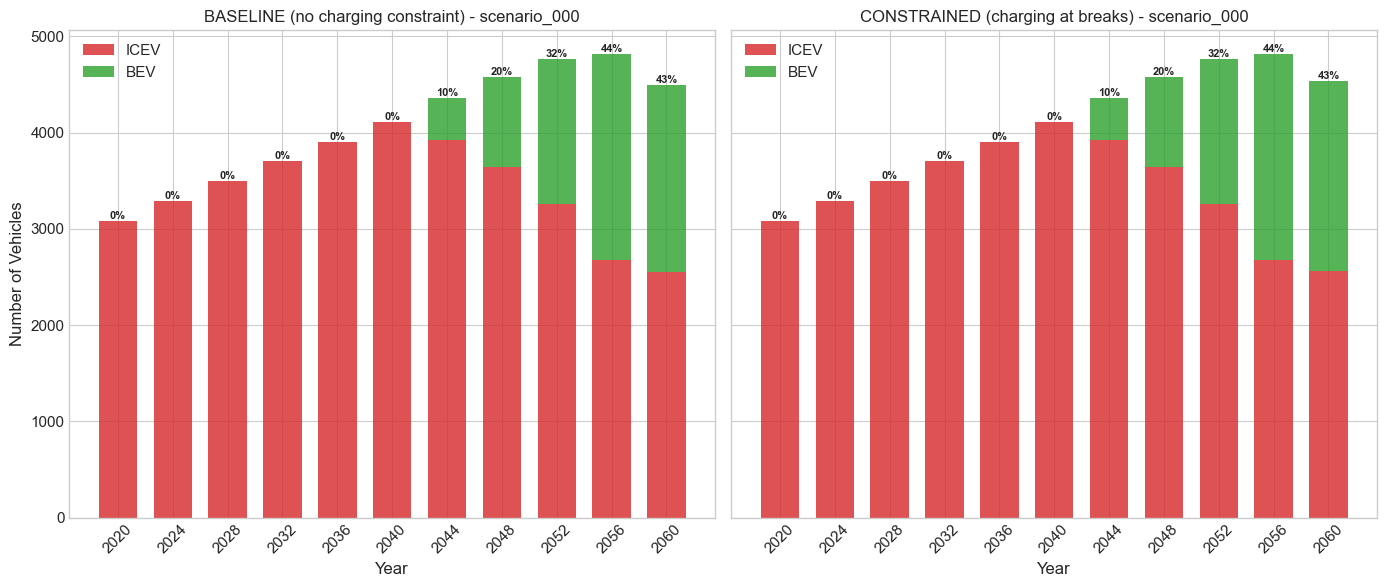


Fleet Summary for scenario_000:
Year     Base ICEV    Base BEV     Base BEV%    Const ICEV   Const BEV    Const BEV%  
--------------------------------------------------------------------------------------
2020     3085.2       0.0          0.0          3085.2       0.0          0.0         
2024     3290.2       0.0          0.0          3290.2       0.0          0.0         
2028     3495.2       0.0          0.0          3495.2       0.0          0.0         
2032     3700.2       0.0          0.0          3700.2       0.0          0.0         
2036     3905.2       0.0          0.0          3905.2       0.0          0.0         
2040     4110.1       0.0          0.0          4110.1       0.0          0.0         
2044     3922.8       435.9        10.0         3922.8       435.9        10.0        
2048     3642.9       937.5        20.5         3642.9       937.5        20.5        
2052     3258.5       1507.9       31.6         3258.5       1507.9       31.6        
2056     2

In [ ]:
def plot_fleet_by_technology_comparison(scenario="scenario_000"):
    """Plot stacked bar chart comparing fleet composition by technology for baseline vs constrained."""
    from collections import defaultdict
    import numpy as np

    # Load h_dict from both runs
    baseline_folder = os.path.join(BASELINE_DIR, scenario)
    constrained_folder = os.path.join(CONSTRAINED_DIR, scenario)

    baseline_h_file = get_latest_file(baseline_folder, "h_dict.yaml")
    constrained_h_file = get_latest_file(constrained_folder, "h_dict.yaml")

    if not baseline_h_file or not constrained_h_file:
        print(f"Missing h_dict files for {scenario}")
        return

    with open(baseline_h_file, "r") as f:
        baseline_h = yaml.safe_load(f)
    with open(constrained_h_file, "r") as f:
        constrained_h = yaml.safe_load(f)

    # Aggregate by year and tech for both
    def aggregate_h(h_dict):
        h_by_year = defaultdict(lambda: defaultdict(float))
        for key, value in h_dict.items():
            parts = key.strip("()").split(",")
            year = int(parts[0].strip())
            tech = int(parts[2].strip())  # tech_vehicle_id: 0=ICEV, 1=BEV
            h_by_year[year][tech] += float(value)
        return h_by_year

    baseline_agg = aggregate_h(baseline_h)
    constrained_agg = aggregate_h(constrained_h)

    years = sorted(set(baseline_agg.keys()) | set(constrained_agg.keys()))

    # Prepare data
    baseline_icev = [baseline_agg[y].get(0, 0) for y in years]
    baseline_bev = [baseline_agg[y].get(1, 0) for y in years]
    constrained_icev = [constrained_agg[y].get(0, 0) for y in years]
    constrained_bev = [constrained_agg[y].get(1, 0) for y in years]

    # Create figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

    x = np.arange(len(years))
    width = 0.7

    # BASELINE subplot
    ax1 = axes[0]
    bars1_icev = ax1.bar(x, baseline_icev, width, label="ICEV", color="#d62728", alpha=0.8)
    bars1_bev = ax1.bar(x, baseline_bev, width, bottom=baseline_icev, label="BEV", color="#2ca02c", alpha=0.8)
    ax1.set_xlabel("Year", fontsize=12)
    ax1.set_ylabel("Number of Vehicles", fontsize=12)
    ax1.set_title(f"BASELINE (no charging constraint) - {scenario}", fontsize=12)
    ax1.set_xticks(x)
    ax1.set_xticklabels(years, rotation=45)
    ax1.legend(loc="upper left")

    # Add BEV % labels
    for i, (icev, bev) in enumerate(zip(baseline_icev, baseline_bev)):
        total = icev + bev
        bev_pct = 100 * bev / total if total > 0 else 0
        ax1.annotate(f"{bev_pct:.0f}%", xy=(i, total), ha="center", va="bottom", fontsize=8, fontweight="bold")

    # CONSTRAINED subplot
    ax2 = axes[1]
    bars2_icev = ax2.bar(x, constrained_icev, width, label="ICEV", color="#d62728", alpha=0.8)
    bars2_bev = ax2.bar(x, constrained_bev, width, bottom=constrained_icev, label="BEV", color="#2ca02c", alpha=0.8)
    ax2.set_xlabel("Year", fontsize=12)
    ax2.set_title(f"CONSTRAINED (charging at breaks) - {scenario}", fontsize=12)
    ax2.set_xticks(x)
    ax2.set_xticklabels(years, rotation=45)
    ax2.legend(loc="upper left")

    # Add BEV % labels
    for i, (icev, bev) in enumerate(zip(constrained_icev, constrained_bev)):
        total = icev + bev
        bev_pct = 100 * bev / total if total > 0 else 0
        ax2.annotate(f"{bev_pct:.0f}%", xy=(i, total), ha="center", va="bottom", fontsize=8, fontweight="bold")

    plt.tight_layout()
    plt.savefig(f"figures/fleet_by_technology_comparison_{scenario}.pdf", dpi=150, bbox_inches="tight")
    plt.savefig(f"figures/fleet_by_technology_comparison_{scenario}.png", dpi=150, bbox_inches="tight")
    print(f"Saved: figures/fleet_by_technology_comparison_{scenario}.pdf")
    plt.show()

    # Print summary statistics
    print(f"\nFleet Summary for {scenario}:")
    header = f"{'Year':<8} {'Base ICEV':<12} {'Base BEV':<12} {'Base BEV%':<12} {'Const ICEV':<12} {'Const BEV':<12} {'Const BEV%':<12}"
    print(header)
    print("-" * len(header))
    for i, year in enumerate(years):
        b_total = baseline_icev[i] + baseline_bev[i]
        c_total = constrained_icev[i] + constrained_bev[i]
        b_pct = 100 * baseline_bev[i] / b_total if b_total > 0 else 0
        c_pct = 100 * constrained_bev[i] / c_total if c_total > 0 else 0
        print(f"{year:<8} {baseline_icev[i]:<12.1f} {baseline_bev[i]:<12.1f} {b_pct:<12.1f} {constrained_icev[i]:<12.1f} {constrained_bev[i]:<12.1f} {c_pct:<12.1f}")

# Run for scenario_000
plot_fleet_by_technology_comparison("scenario_000")


In [50]:
# =====================================================
# OBJECTIVE VALUE COMPARISON: Baseline vs Constrained
# =====================================================

import yaml

# Load batch summaries
baseline_summary_path = os.path.join(BASELINE_DIR, 'batch_summary.yaml')
constrained_summary_path = os.path.join(CONSTRAINED_DIR, 'batch_summary.yaml')

with open(baseline_summary_path, 'r') as f:
    baseline_summary = yaml.safe_load(f)
with open(constrained_summary_path, 'r') as f:
    constrained_summary = yaml.safe_load(f)

print(f'Baseline scenarios: {len(baseline_summary)}')
print(f'Constrained scenarios: {len(constrained_summary)}')


Baseline scenarios: 24
Constrained scenarios: 24


In [53]:
# Compare objective values
obj_comparison = []

for scenario in scenarios:
    base_data = baseline_summary.get(scenario, {})
    const_data = constrained_summary.get(scenario, {})
    
    base_obj = base_data.get('objective_value')
    const_obj = const_data.get('objective_value')
    
    if base_obj is not None and const_obj is not None:
        delta = float(const_obj) - float(base_obj)
        pct_change = (delta / float(base_obj)) * 100
        
        # Get scenario metadata
        case_idx = int(scenario.split('_')[1])
        case_info = cases_config['cases'][case_idx]
        
        obj_comparison.append({
            'scenario': scenario,
            'genesys': case_info['genesys_scenario'].replace(' v1.2', ''),
            'charging_markup': case_info['charging_markup'],
            'tech_cost': case_info['tech_cost_multiplier'],
            'baseline_obj': base_obj,
            'constrained_obj': const_obj,
            'delta': delta,
            'pct_change': pct_change
        })

obj_df = pd.DataFrame(obj_comparison)
print(f'Compared {len(obj_df)} scenarios')
print()
print('Summary Statistics:')
print(obj_df[['baseline_obj', 'constrained_obj', 'delta', 'pct_change']].describe())


Compared 24 scenarios

Summary Statistics:
              delta    pct_change
count  2.400000e+01  2.400000e+01
mean   2.030289e+07  6.136649e-03
std    2.371115e+07  7.176572e-03
min   -9.854126e-01 -2.957061e-10
25%    1.801605e-01  5.406795e-11
50%    8.027738e+06  2.411722e-03
75%    5.210043e+07  1.576308e-02
max    5.391711e+07  1.631096e-02


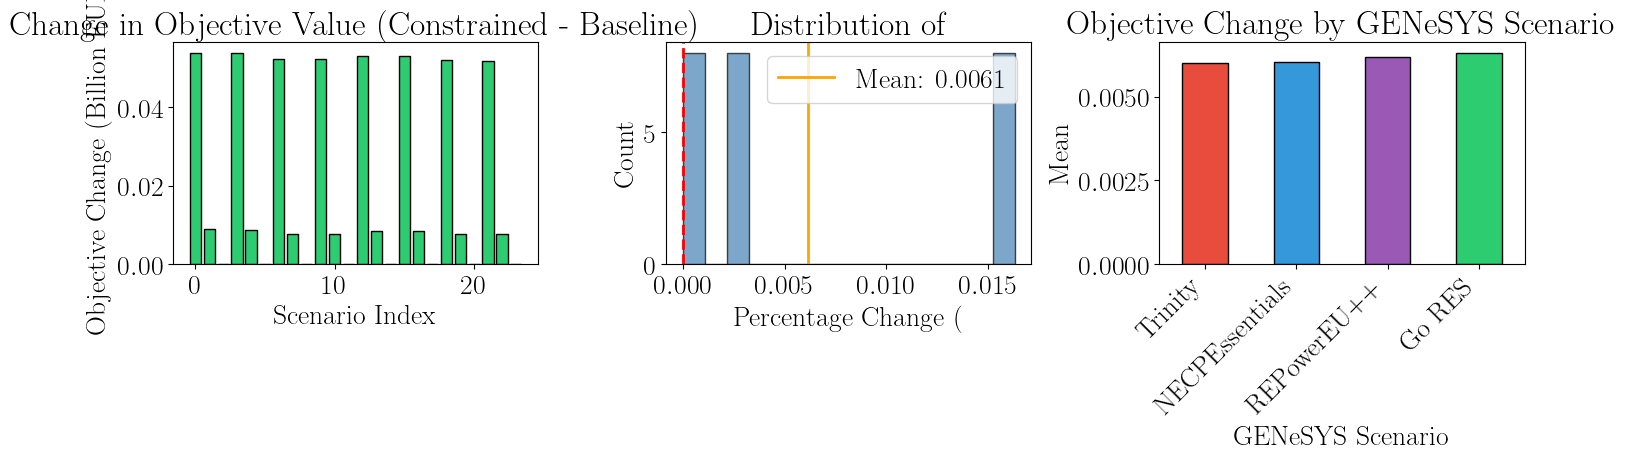

=== Objective Value Impact Summary ===
Scenarios with INCREASED cost: 21 (87.5%)
Scenarios with DECREASED cost: 3 (12.5%)
Mean change: 0.0203 Billion EUR (0.0061%)
Max increase: 0.0539 Billion EUR
Max decrease: -0.0000 Billion EUR


In [55]:
# Visualize objective value changes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Bar chart of delta by scenario
ax = axes[0]
colors_bar = ['#2ecc71' if d > 0 else '#e74c3c' for d in obj_df['delta']]
ax.bar(range(len(obj_df)), obj_df['delta'] / 1e9, color=colors_bar, edgecolor='black')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Scenario Index')
ax.set_ylabel('Objective Change (Billion EUR)')
ax.set_title('Change in Objective Value (Constrained - Baseline)')

# 2. Percentage change distribution
ax = axes[1]
ax.hist(obj_df['pct_change'], bins=15, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(0, color='red', linestyle='--', linewidth=2)
ax.axvline(obj_df['pct_change'].mean(), color='orange', linestyle='-', linewidth=2,
           label=f'Mean: {obj_df["pct_change"].mean():.4f}%')
ax.set_xlabel('Percentage Change (%)')
ax.set_ylabel('Count')
ax.set_title('Distribution of % Objective Change')
ax.legend()

# 3. By GENeSYS scenario
ax = axes[2]
genesys_obj = obj_df.groupby('genesys')['pct_change'].mean().sort_values()
colors_gen = {'Go RES': '#2ecc71', 'NECPEssentials': '#3498db', 'REPowerEU++': '#9b59b6', 'Trinity': '#e74c3c'}
bar_colors = [colors_gen.get(g, 'gray') for g in genesys_obj.index]
genesys_obj.plot(kind='bar', ax=ax, color=bar_colors, edgecolor='black')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('GENeSYS Scenario')
ax.set_ylabel('Mean % Change in Objective')
ax.set_title('Objective Change by GENeSYS Scenario')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('figures/objective_value_comparison.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Print summary
print('=== Objective Value Impact Summary ===')
print(f'Scenarios with INCREASED cost: {(obj_df["delta"] > 0).sum()} ({100*(obj_df["delta"] > 0).mean():.1f}%)')
print(f'Scenarios with DECREASED cost: {(obj_df["delta"] < 0).sum()} ({100*(obj_df["delta"] < 0).mean():.1f}%)')
print(f'Mean change: {obj_df["delta"].mean()/1e9:.4f} Billion EUR ({obj_df["pct_change"].mean():.4f}%)')
print(f'Max increase: {obj_df["delta"].max()/1e9:.4f} Billion EUR')
print(f'Max decrease: {obj_df["delta"].min()/1e9:.4f} Billion EUR')


In [57]:
# Detailed table by scenario
obj_df_display = obj_df.copy()
obj_df_display['baseline_obj'] = obj_df_display['baseline_obj'] / 1e9
obj_df_display['constrained_obj'] = obj_df_display['constrained_obj'] / 1e9
obj_df_display['delta'] = obj_df_display['delta'] / 1e9
obj_df_display = obj_df_display.rename(columns={
    'baseline_obj': 'Baseline (Bn EUR)',
    'constrained_obj': 'Constrained (Bn EUR)',
    'delta': 'Delta (Bn EUR)',
    'pct_change': '% Change'
})

print('Objective Value Comparison by Scenario:')
print(obj_df_display.to_string(index=False))


TypeError: unsupported operand type(s) for /: 'str' and 'float'

In [58]:
# =====================================================
# COST PER TRANSPORT PERFORMANCE: EUR/1000 TKM
# =====================================================

# Load path distances and demand data
import yaml

# Load from scenario_000 (same structure for all scenarios)
input_path = os.path.join(BASE_DIR, 'input_data', 'uncertainty_scenarios', 'scenario_000')

with open(os.path.join(input_path, 'Path.yaml'), 'r') as f:
    paths_data = yaml.safe_load(f)

with open(os.path.join(input_path, 'Odpair.yaml'), 'r') as f:
    odpair_data = yaml.safe_load(f)

# Create mappings
path_distances = {p['id']: p['length'] for p in paths_data}  # km
odpair_demand = {}  # {odpair_id: [F values by year]}
odpair_path = {}  # {odpair_id: path_id}

for od in odpair_data:
    odpair_demand[od['id']] = od['F']  # tonnes per year
    odpair_path[od['id']] = od['path_id']

print(f'Loaded {len(path_distances)} paths')
print(f'Loaded {len(odpair_demand)} OD pairs')
print(f'Years in optimization: {len(odpair_demand[list(odpair_demand.keys())[0]])} years')


Loaded 2043 paths
Loaded 2043 OD pairs
Years in optimization: 41 years


In [59]:
# Calculate total TKM across all years
# TKM = sum over all OD pairs and years of (F[od,year] * distance[path])

years = list(range(2020, 2061, 4))  # Model years: 2020, 2024, ..., 2060
print(f'Model years: {years}')

total_tkm = 0
tkm_by_year = {}

for od_id, demand_list in odpair_demand.items():
    path_id = odpair_path.get(od_id)
    if path_id is None:
        continue
    distance = path_distances.get(path_id, 0)  # km

    for year_idx, year in enumerate(years):
        if year_idx < len(demand_list):
            tonnes = demand_list[year_idx]
            tkm = tonnes * distance  # tonne-km
            total_tkm += tkm
            tkm_by_year[year] = tkm_by_year.get(year, 0) + tkm

print(f'\nTotal TKM over optimization horizon: {total_tkm/1e9:.2f} billion TKM')
print(f'\nTKM by year (billion):')
for year in sorted(tkm_by_year.keys()):
    print(f'  {year}: {tkm_by_year[year]/1e9:.2f}')


Model years: [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

Total TKM over optimization horizon: 91.08 billion TKM

TKM by year (billion):
  2020: 7.63
  2024: 7.76
  2028: 7.89
  2032: 8.02
  2036: 8.15
  2040: 8.28
  2044: 8.41
  2048: 8.54
  2052: 8.67
  2056: 8.80
  2060: 8.93


In [60]:
# Calculate EUR/1000 TKM for each scenario
# Using objective value / (total_tkm / 1000)

eur_per_1000tkm = []

for scenario in scenarios:
    base_data = baseline_summary.get(scenario, {})
    const_data = constrained_summary.get(scenario, {})

    base_obj = float(base_data.get('objective_value', 0))
    const_obj = float(const_data.get('objective_value', 0))

    if base_obj > 0 and const_obj > 0:
        # EUR per 1000 TKM
        base_eur_1000tkm = base_obj / (total_tkm / 1000)
        const_eur_1000tkm = const_obj / (total_tkm / 1000)
        delta_eur_1000tkm = const_eur_1000tkm - base_eur_1000tkm

        # Get scenario metadata
        case_idx = int(scenario.split('_')[1])
        case_info = cases_config['cases'][case_idx]

        eur_per_1000tkm.append({
            'scenario': scenario,
            'genesys': case_info['genesys_scenario'].replace(' v1.2', ''),
            'charging_markup': case_info['charging_markup'],
            'tech_cost': case_info['tech_cost_multiplier'],
            'baseline_eur_1000tkm': base_eur_1000tkm,
            'constrained_eur_1000tkm': const_eur_1000tkm,
            'delta_eur_1000tkm': delta_eur_1000tkm,
            'pct_change': (delta_eur_1000tkm / base_eur_1000tkm) * 100
        })

tkm_df = pd.DataFrame(eur_per_1000tkm)
print(f'Calculated EUR/1000 TKM for {len(tkm_df)} scenarios')
print(f'\nTotal transport performance: {total_tkm/1e9:.2f} billion TKM')
print(f'\nSummary Statistics (EUR/1000 TKM):')
print(tkm_df[['baseline_eur_1000tkm', 'constrained_eur_1000tkm', 'delta_eur_1000tkm']].describe())


Calculated EUR/1000 TKM for 24 scenarios

Total transport performance: 91.08 billion TKM

Summary Statistics (EUR/1000 TKM):
       baseline_eur_1000tkm  constrained_eur_1000tkm  delta_eur_1000tkm
count             24.000000                24.000000       2.400000e+01
mean            3647.577259              3647.800177       2.229188e-01
std               13.390304                13.130172       2.603404e-01
min             3628.984737              3629.556335      -1.081935e-08
25%             3629.366853              3629.956369       1.978037e-09
50%             3654.723283              3654.811519       8.814183e-02
75%             3658.487485              3658.487485       5.720451e-01
max             3659.222806              3659.222806       5.919915e-01


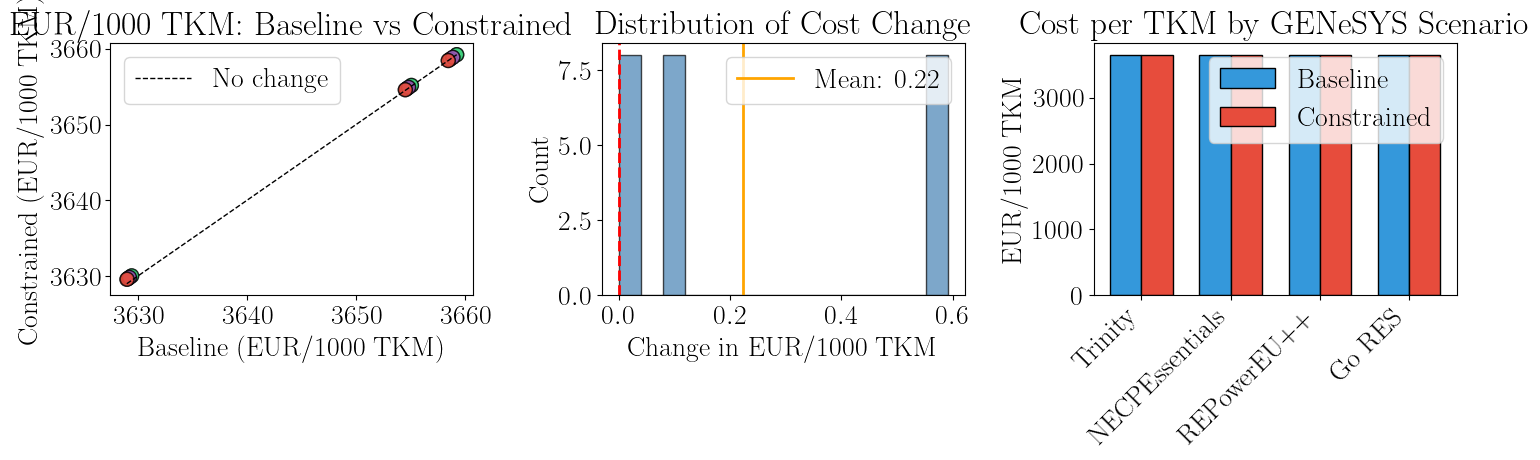


=== EUR/1000 TKM Summary ===
Mean Baseline: 3647.58 EUR/1000 TKM
Mean Constrained: 3647.80 EUR/1000 TKM
Mean Change: 0.22 EUR/1000 TKM (0.0061%)


In [61]:
# Visualize EUR/1000 TKM comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Baseline vs Constrained scatter
ax = axes[0]
colors_map = {'Go RES': '#2ecc71', 'NECPEssentials': '#3498db', 'REPowerEU++': '#9b59b6', 'Trinity': '#e74c3c'}
scatter_colors = [colors_map.get(g, 'gray') for g in tkm_df['genesys']]
ax.scatter(tkm_df['baseline_eur_1000tkm'], tkm_df['constrained_eur_1000tkm'],
           c=scatter_colors, s=100, alpha=0.7, edgecolors='black')
# Diagonal line (no change)
min_val = min(tkm_df['baseline_eur_1000tkm'].min(), tkm_df['constrained_eur_1000tkm'].min())
max_val = max(tkm_df['baseline_eur_1000tkm'].max(), tkm_df['constrained_eur_1000tkm'].max())
ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1, label='No change')
ax.set_xlabel('Baseline (EUR/1000 TKM)')
ax.set_ylabel('Constrained (EUR/1000 TKM)')
ax.set_title('EUR/1000 TKM: Baseline vs Constrained')
ax.legend()

# 2. Delta distribution
ax = axes[1]
ax.hist(tkm_df['delta_eur_1000tkm'], bins=15, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(0, color='red', linestyle='--', linewidth=2)
mean_delta = tkm_df['delta_eur_1000tkm'].mean()
ax.axvline(mean_delta, color='orange', linestyle='-', linewidth=2, label=f'Mean: {mean_delta:.2f}')
ax.set_xlabel('Change in EUR/1000 TKM')
ax.set_ylabel('Count')
ax.set_title('Distribution of Cost Change')
ax.legend()

# 3. By GENeSYS scenario
ax = axes[2]
genesys_means = tkm_df.groupby('genesys').agg({
    'baseline_eur_1000tkm': 'mean',
    'constrained_eur_1000tkm': 'mean'
}).sort_values('baseline_eur_1000tkm')

x = np.arange(len(genesys_means))
width = 0.35
ax.bar(x - width/2, genesys_means['baseline_eur_1000tkm'], width, label='Baseline', color='#3498db', edgecolor='black')
ax.bar(x + width/2, genesys_means['constrained_eur_1000tkm'], width, label='Constrained', color='#e74c3c', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(genesys_means.index, rotation=45, ha='right')
ax.set_ylabel('EUR/1000 TKM')
ax.set_title('Cost per TKM by GENeSYS Scenario')
ax.legend()

plt.tight_layout()
plt.savefig('figures/eur_per_1000tkm_comparison.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Summary
print('\n=== EUR/1000 TKM Summary ===')
print(f'Mean Baseline: {tkm_df["baseline_eur_1000tkm"].mean():.2f} EUR/1000 TKM')
print(f'Mean Constrained: {tkm_df["constrained_eur_1000tkm"].mean():.2f} EUR/1000 TKM')
print(f'Mean Change: {tkm_df["delta_eur_1000tkm"].mean():.2f} EUR/1000 TKM ({tkm_df["pct_change"].mean():.4f}%)')


In [62]:
# Detailed comparison table
tkm_display = tkm_df[['scenario', 'genesys', 'charging_markup', 'tech_cost',
                       'baseline_eur_1000tkm', 'constrained_eur_1000tkm',
                       'delta_eur_1000tkm', 'pct_change']].copy()
tkm_display = tkm_display.round(2)
tkm_display.columns = ['Scenario', 'GENeSYS', 'Markup', 'Tech Cost',
                        'Baseline', 'Constrained', 'Delta', '% Change']

print('EUR/1000 TKM Comparison by Scenario:')
print(tkm_display.to_string(index=False))


EUR/1000 TKM Comparison by Scenario:
    Scenario        GENeSYS  Markup  Tech Cost  Baseline  Constrained  Delta  % Change
scenario_000         Go RES    0.15        0.7   3629.41      3630.00   0.59      0.02
scenario_001         Go RES    0.15        1.0   3655.06      3655.16   0.10      0.00
scenario_002         Go RES    0.15        1.3   3659.22      3659.22   0.00      0.00
scenario_003         Go RES    0.30        0.7   3629.44      3630.03   0.59      0.02
scenario_004         Go RES    0.30        1.0   3655.07      3655.17   0.10      0.00
scenario_005         Go RES    0.30        1.3   3659.22      3659.22   0.00      0.00
scenario_006 NECPEssentials    0.15        0.7   3629.09      3629.67   0.57      0.02
scenario_007 NECPEssentials    0.15        1.0   3654.63      3654.72   0.08      0.00
scenario_008 NECPEssentials    0.15        1.3   3658.61      3658.61  -0.00     -0.00
scenario_009 NECPEssentials    0.30        0.7   3629.12      3629.70   0.57      0.02
scenar